# EviTab-NS: Cascaded Evidential Decision-Table Ensembles with Vacuity-Gated Symbolic Evidence Fusion for Multi-Attack and Zero-Day Intrusion Detection in Resource-Constrained IIoT and ICS Networks
**Datasets:** RT-IoT2022 · NF-ToN-IoT-v2 · Edge-IIoTset

**Design goals (in order):** high accuracy · CPU-only training (no backpropagation through the
model) · low, tail-bounded single-flow latency for delay-sensitive pipelines · native,
count-backed uncertainty · auditable (optional) symbolic channel.

**Contributions implemented in this notebook**
1. **Greedy-oblivious evidential decision tables:** each table is a CatBoost-style *oblivious*
   tree - one shared (feature, threshold) test per level, chosen by class-weighted-Gini
   histogram search over binned features - so every table *is* a flat 2^D-entry lookup table.
   **Training is counting + split search, not gradient descent**: one seed fits on a single CPU
   core in minutes, with per-stage fit times printed and aggregated.
2. **Count-backed evidential leaves:** a leaf stores occupancy-smoothed Dirichlet evidence
   e[c] = N[leaf, c] / (N[leaf] + κ) - literal training-flow counts. Total evidence answers
   *"how many training flows looked like this, and how pure were they"*; α = e + 1 gives class
   probabilities and **vacuity** u = C/S, an uncertainty meant to be high where training
   support is thin (tested in Cells 15 and 17). Leaves carry a **dual payload**: a short convex
   multiplicative refinement (mild √-class-weights, internal-holdout early stopping on accuracy)
   produces the *decision* leaves, while the pristine *count* leaves are preserved as the
   evidential/novelty channel - calibration for decisions, honest counts for uncertainty.
3. **Adaptive table-only cascade:** every level trains a *pair* of ensembles on complementary
   halves (2-fold cross-fitting), so the class-probability features passed to the next level are
   always out-of-fold - no stacking leakage at any depth. Levels are added **while validation
   accuracy improves** (capped at 4), and inference optionally averages level probabilities when
   that wins on validation. The cascade narrows the gap to RandomForest while keeping every
   component a lookup table.
4. **Coverage tables:** a block of *random-split* tables whose leaves hold occupancy only - an
   unsupervised density channel in the same format. Their leaf-rarity reacts along features the
   discriminative splits never test. **Native novelty = z(vacuity) + z(rarity)** is the free,
   count-backed zero-day score; the *same vacuity* gates the symbolic channel (one mechanism,
   two jobs).
5. **Vacuity-Gated Symbolic Evidence Fusion (VGSEF):** auditable traffic rules (flood-rate,
   half-open SYN probe, service ports, RST/ICMP logic) inject **evidence, not logits** for
   their attack group, scaled by u(x): heard where counts are thin, ignored where counts are
   decisive. Weights are learnable (init 0 = exact learner-only baseline) and kept **only if** they
   improve held-out macro-F1 (do-no-harm gate). The headline model needs no rules at all.
6. **Zero-day protocol with negative controls (Cells 12a-12b):** an entire attack family is
   withheld; native novelty vs **MSP, ODIN, Mahalanobis, dissonance** (+ each single channel in
   the CSV) under identical models/splits; benign-rarity symbolic evidence as an additive channel
   with **double-guarded** λ calibration (validation AUROC *and* Recall@95%TNR must not degrade);
   case designations measured by weighted rule activation (5% threshold). Partition-score
   extrapolation limits are disclosed and measured against input-space Mahalanobis.
7. **Delay-sensitive deployment, measured (Cell 11):** inference = threshold comparisons + table
   lookups + sums - **zero matrix multiplications, no ML runtime**. Reports median **and p99**
   single-flow latency (single CPU thread), throughput, FP32 vs INT8-leaf size (INT8 kept under
   a ≤1-point *validation*-accuracy guard), and the exported `.npz` tables are the *evaluated* model.
8. **Resource-aware depth and uncertainty validation (Cells 15-17):** every cascade prefix is
   scored from one fit and a budgeted objective (latency, memory, minimum accuracy) picks the
   configuration to ship; vacuity is checked against recovered leaf training support, and
   calibration (ECE, Brier) and error detection (AUROC, AUPR, AURC) are compared with 1-MSP.
9. **Statistical rigour & journal-ready reporting:** 10-seed protocol (fresh split + init),
   mean ± std, paired Wilcoxon + t-tests, bootstrap 95% CIs, Cohen's d_z, leak-free
   preprocessing, and - for the temporal Edge-IIoTset split - **drift-aware validation**
   (model selection and refinement early-stop on the chronological tail of train, the same
   forward-in-time condition as the test set). A **publication master table**
   (`evitab_ns_publication_table.csv`) consolidates Accuracy, Precision/Recall/F1
   (macro & weighted), MCC, Cohen's κ, Balanced Accuracy, G-mean, ROC-AUC, PR-AUC,
   TP/TN/FP/FN, TPR/TNR/FPR/FNR, DR/FAR, p50/p99 latency, throughput (flows/s), model
   sizes, and fit times. Figures follow conventional journal forms: confusion matrices,
   per-class precision/recall/F1 heatmaps, grouped bars with error bars, box plots,
   reliability diagrams and risk-coverage curves.

**How EviTab-NS differs from the two prior architectures**

| Axis | EdgeGuard-NS (fusion MLP) | ProtoGuard-NS (prototype net) | **EviTab-NS (this work)** |
|---|---|---|---|
| Backbone | Dense MLP | Dense encoder + prototypes | **Greedy-oblivious decision tables (cascade) - no dense layers** |
| Trained by | Backprop (GPU-friendly) | Backprop | **Counting + histogram split search (CPU-only)** |
| Output semantics | Softmax logits | Distance logits | **Dirichlet evidence = smoothed training-flow counts** |
| Uncertainty | Predictive entropy | Distance margin | **Count-backed vacuity + coverage leaf-rarity** |
| Symbolic fusion | Logit bias | Distance correction | **Evidence injection, vacuity-gated, do-no-harm gate** |
| Zero-day score | Energy (post-hoc) | d_min to prototypes | **Native novelty: the tables' own counts** |
| Deployed inference | INT8 mat-muls | INT8 mat-muls | **Comparisons + lookups + sums: zero mat-muls** |
| Single-flow latency | not re-measured here | not re-measured here | **measured in Cell 11 (p50 and p99)** |

**Outputs:** 16 bold, 300-dpi figures in `./figures`; summary + per-seed + zero-day + baseline +
confusion-rate + resource-aware + uncertainty CSVs; deployable `.npz` lookup tables per dataset.
Long-running results are checkpointed to Google Drive, so a restarted session reloads them
instead of retraining.

*Requirements:* `pandas pyarrow scikit-learn scipy matplotlib torch kagglehub` (torch is used only
for the deep baseline and two small convex fits; EviTab-NS itself trains without it). Cell 0
downloads the three datasets from Kaggle with `kagglehub`.

In [2]:
# Cell 0 - Environment setup (Colab or local) + dataset download
#   Colab: mounts Drive, downloads the three datasets with kagglehub, and switches the working
#   directory to OUT_DIR on Drive so figures / CSVs survive a runtime disconnect.
#   Kaggle login: add KAGGLE_USERNAME / KAGGLE_KEY in Colab Secrets (key icon, enable notebook
#   access), or log in when the prompt appears.
#   Locally (or to use files you already have on Drive), set the paths in LOCAL_PATHS, or the
#   EVITAB_RT / EVITAB_NF / EVITAB_EDGE environment variables. A path may be the data file itself
#   or any folder that contains it (searched recursively).
# ----------------------------------------------------------------------------------------------
print('Cell 0 - Environment setup (Colab or local) + dataset download')
import os, sys, subprocess, zipfile, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

LOCAL_PATHS = {
    "rt":   None,     # RT-IoT2022    -> RT_IOT2022.csv
    "nf":   None,     # NF-ToN-IoT-v2 -> NF-ToN-IoT-V2.parquet (dhoogla parquet release)
    "edge": None,     # Edge-IIoTset  -> .../Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv
}
DATA_FILES = {"rt": "*[Rr][Tt]_[Ii][Oo][Tt]2022*.csv", "nf": "NF-ToN-IoT-V2*.parquet",
              "edge": "ML-EdgeIIoT-dataset.csv"}

# Kaggle handles tried in order (pinned version = the one behind the paper's numbers, then
# latest). If all fail, the slug is searched on Kaggle; paste the owner/slug from the dataset URL
# at the front of a list to force a particular copy.
KAGGLE = {
    "rt":   ("rt-iot2022real-time-internet-of-things", 3,
             ["supplejade/rt-iot2022real-time-internet-of-things"]),
    "nf":   ("nftoniotv2", 2, ["dhoogla/nftoniotv2"]),
    "edge": ("edgeiiotset-cyber-security-dataset-of-iot-iiot", 5,
             ["mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"]),
}
RT_UCI_ZIP = "https://archive.ics.uci.edu/static/public/942/rt-iot2022.zip"   # RT-IoT2022 fallback

def find_file(root, pattern):
    root = Path(root)
    if root.is_file(): return root
    hits = sorted(root.rglob(pattern))
    if not hits:
        raise FileNotFoundError(f"no '{pattern}' under {root}")
    return hits[0]

if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/EviTab-NS")
    except Exception as e:
        print(f"   WARNING: Drive mount failed ({type(e).__name__}: {e}); using local directory.")
        OUT_DIR = Path("/content/EviTab-NS")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub", "kaggle"],
                   check=False)
else:
    OUT_DIR = Path(os.environ.get("EVITAB_OUT", "./EviTab-NS"))
    for key in LOCAL_PATHS:
        env = os.environ.get(f"EVITAB_{key.upper()}")
        if env: LOCAL_PATHS[key] = env
OUT_DIR = OUT_DIR.resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)

if any(v is None for v in LOCAL_PATHS.values()):
    import kagglehub
    if IN_COLAB:
        try:
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        except Exception:
            kagglehub.login()

    def kaggle_search(slug):
        try:
            r = subprocess.run(["kaggle", "datasets", "list", "-s", slug.replace("-", " "), "--csv"],
                               capture_output=True, text=True, timeout=120)
        except Exception:
            return []
        rows = [l.split(",")[0] for l in r.stdout.splitlines()[1:] if l.strip()]
        return [h for h in rows if h.split("/")[-1] == slug] + [h for h in rows if h.split("/")[-1] != slug]

    def fetch(key, slug, ver, cands):
        tried = []
        for h in cands + [c for c in kaggle_search(slug) if c not in cands]:
            for ref in ([f"{h}/versions/{ver}"] if ver else []) + [h]:
                try:
                    p = Path(kagglehub.dataset_download(ref))
                    find_file(p, DATA_FILES[key])          # right dataset, right file?
                    if ver and ref == h:
                        print(f"   WARNING: {h} version {ver} unavailable - using latest version")
                    return h, p
                except Exception as e:
                    tried.append(f"{ref} ({type(e).__name__})")
        raise RuntimeError(f"could not download '{slug}'. Tried: {tried}. Put the correct owner/slug "
                           f"from the Kaggle URL first in KAGGLE['{key}'], or set LOCAL_PATHS.")

    def fetch_rt_uci():
        dst = OUT_DIR / "data" / "rt-iot2022"; dst.mkdir(parents=True, exist_ok=True)
        zp = dst / "rt-iot2022.zip"
        if not zp.exists():
            urllib.request.urlretrieve(RT_UCI_ZIP, zp)
        with zipfile.ZipFile(zp) as z:
            z.extractall(dst)
        for inner in dst.rglob("*.zip"):             # UCI archives are sometimes nested
            if inner != zp:
                with zipfile.ZipFile(inner) as z: z.extractall(inner.parent)
        find_file(dst, DATA_FILES["rt"])
        return "UCI repository (id 942)", dst

    for key, (slug, ver, cands) in KAGGLE.items():
        if LOCAL_PATHS[key] is not None: continue
        try:
            handle, root = fetch(key, slug, ver, cands)
        except RuntimeError:
            if key != "rt": raise
            print("   RT-IoT2022 not found on Kaggle - downloading from the UCI repository")
            handle, root = fetch_rt_uci()
        LOCAL_PATHS[key] = str(root)
        size = sum(f.stat().st_size for f in Path(root).rglob("*") if f.is_file()) / 1e6
        print(f"   {key:5s} {handle:68s} -> {root}  ({size:,.0f} MB)")

DATA_PATHS = {k: find_file(v, DATA_FILES[k]) for k, v in LOCAL_PATHS.items()}
os.chdir(OUT_DIR)
print(f"outputs -> {Path.cwd()}")
for k, v in DATA_PATHS.items():
    print(f"   {k:5s}: {v}")
print('Cell 0 - Environment setup is complete')


Cell 0 - Environment setup (Colab or local) + dataset download
Mounted at /content/drive


100%|██████████| 3.64M/3.64M [00:00<00:00, 103MB/s]

Extracting files...


   rt    supplejade/rt-iot2022real-time-internet-of-things                    -> /root/.cache/kagglehub/datasets/supplejade/rt-iot2022real-time-internet-of-things/versions/3  (55 MB)


100%|██████████| 174M/174M [00:01<00:00, 103MB/s]

Extracting files...


   nf    dhoogla/nftoniotv2                                                   -> /root/.cache/kagglehub/datasets/dhoogla/nftoniotv2/versions/2  (209 MB)
Using Colab cache for faster access to the 'edgeiiotset-cyber-security-dataset-of-iot-iiot' dataset.
   edge  mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot    -> /kaggle/input/edgeiiotset-cyber-security-dataset-of-iot-iiot  (11,249 MB)
outputs -> /content/drive/MyDrive/EviTab-NS
   rt   : /root/.cache/kagglehub/datasets/supplejade/rt-iot2022real-time-internet-of-things/versions/3/RT_IOT2022.csv
   nf   : /root/.cache/kagglehub/datasets/dhoogla/nftoniotv2/versions/2/NF-ToN-IoT-V2.parquet
   edge : /kaggle/input/edgeiiotset-cyber-security-dataset-of-iot-iiot/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv
Cell 0 - Environment setup is complete


In [3]:
# Cell 1 - Imports, configuration, reproducibility, bold style
# ------------------------------------------------------------
print('Cell 1 - Imports, configuration, reproducibility, bold style')

import os, time, json, io, pickle, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # avoids noisy wmic traceback on Windows
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import wilcoxon, ttest_rel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             balanced_accuracy_score, cohen_kappa_score,
                             confusion_matrix, classification_report,
                             matthews_corrcoef, roc_auc_score, f1_score,
                             roc_curve, precision_recall_curve, average_precision_score)
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # torch is used only for
# the compact deep BASELINE and the convex leaf-refinement / rule-weight fits; EviTab-NS itself
# trains with histogram counting + greedy split search - CPU-only devices are first-class here.

# dataset files come from Cell 0 (DATA_PATHS); outputs go to its OUT_DIR
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# checkpoints (on Drive when Cell 0 mounted it): every finished fit is saved under
# OUT_DIR/checkpoints and reloaded on re-run, so a runtime disconnect only costs the fit
# in progress. Delete the folder (or one file) to force a refit.
CKPT_DIR = Path("checkpoints"); CKPT_DIR.mkdir(exist_ok=True)
RUN_MAIN_PROTOCOL = True    # False: Cells 5-6 only define functions (go straight to Cells 15-17)

def ckpt_load(tag):
    f = CKPT_DIR / f"{tag}.pkl"
    if not f.exists(): return None
    with open(f, "rb") as fh:
        return pickle.load(fh)

def ckpt_save(tag, obj):
    tmp = CKPT_DIR / f"{tag}.pkl.tmp"
    with open(tmp, "wb") as fh:
        pickle.dump(obj, fh, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, CKPT_DIR / f"{tag}.pkl")      # never leaves a half-written checkpoint

# experimental protocol
N_SEEDS  = 10                       # >=10 so paired Wilcoxon (min p = 2/2^n) can reach p < 0.05
SEEDS    = list(range(42, 42 + N_SEEDS))
REP_SEED = SEEDS[0]                 # representative run for per-class figures
ZD_SEEDS = SEEDS[:3]                # zero-day seeds (3 keeps CPU wall-time modest; raise to 5
                                    # for camera-ready numbers - per-seed values land in the CSV)

# evaluation-honesty switches
TEMPORAL_SPLIT_EDGE   = True        # Edge-IIoTset: chronological 80/20 split (frame.time)
SINGLE_THREAD_LATENCY = True        # profile single-flow latency on ONE cpu thread ("edge-honest")
CONTROL_ACT_MAX       = 0.05        # negative-control holdout must fire rules on <5% of its flows

# EviTab-NS: cascaded greedy-oblivious evidential decision tables
# Training = histogram BINNING + greedy per-LEVEL split search (CatBoost-style oblivious trees)
# + one counting pass for Dirichlet leaf evidence + a short convex leaf refinement.
# No backpropagation through structure, no epochs over the full data: designed for CPU-only boxes.
NF_MAX_PER_CLASS = 100_000          # stratified cap for NF-ToN-IoT-v2 (16.9M rows); None = all
N_BINS   = 32                       # histogram bins per feature for split search
T1, D1   = 96, 10                   # layer-1: tables x depth (2^10 = 1024 evidence leaves)
T2, D2   = 64, 12                   # levels 2+ (deeper; see previous-level class probs)
MAX_LEVELS     = 4                  # adaptive cascade depth cap (levels added while val improves)
LEVEL_PATIENCE = 1                  # stop after this many levels without val improvement
F_FRAC   = 0.7                      # feature subspace per table
TREE_SUB = 160_000                  # bootstrap rows per table (caps per-table induction cost)
KAPPA    = 2.0                      # occupancy smoothing: evidence = counts / (leaf_n + KAPPA)
REFINE_EPOCHS = 8                   # convex multiplicative leaf refinement (torch, sparse gathers)
REFINE_MAX    = 250_000             # refinement subsample cap
COV_T, COV_D  = 128, 8              # coverage tables (random splits, occupancy only) for novelty
FUSION_STEPS  = 400                 # gradient steps for learned rule weights

# deep-baseline budget (TabCNN under the same split; capped so baseline training does not
# dominate notebook wall-time on CPU-only devices)
EPOCHS_BASELINE = 40
BATCH_SIZE      = 4096
LR_BASELINE     = 2e-3
PATIENCE        = 8
MIN_EPOCHS      = 12

# bold, publication-ready figure style - EviTab-NS visual identity: warm paper
# background, open (top/right-free) spines, dotted y-grid, teal/ember/plum palette
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "#FDFBF7",
    "font.size": 13, "font.weight": "bold",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 14, "axes.labelweight": "bold",
    "axes.linewidth": 1.6, "axes.edgecolor": "#37474F",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.linestyle": ":",
    "grid.linewidth": 1.0, "grid.color": "#B0A79B", "grid.alpha": 0.55,
    "axes.axisbelow": True,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "legend.framealpha": 0.92, "legend.edgecolor": "#37474F",
    "lines.linewidth": 2.6,
    "axes.prop_cycle": plt.cycler(color=["#00695C", "#AD1457", "#E65100", "#5C6BC0",
                                         "#C77800", "#00838F", "#6A1B9A", "#A1887F"]),
})
def bold_ticks(ax):
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")

print(f"Device (baseline/refinement only): {DEVICE} | PyTorch {torch.__version__} | "
      f"seeds: {SEEDS} | zero-day seeds: {ZD_SEEDS}")
print(f"Layer-1: {T1} tables x depth {D1} | Layer-2: {T2} x {D2} | coverage: {COV_T} x {COV_D} | "
      f"bins={N_BINS} | temporal split (Edge-IIoTset): {TEMPORAL_SPLIT_EDGE} | "
      f"single-thread latency: {SINGLE_THREAD_LATENCY}")
print('Cell 1 - Imports, configuration, reproducibility, bold style is complete')

Cell 1 - Imports, configuration, reproducibility, bold style
Device (baseline/refinement only): cpu | PyTorch 2.14.1+cpu | seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] | zero-day seeds: [42, 43, 44]
Layer-1: 96 tables x depth 10 | Layer-2: 64 x 12 | coverage: 128 x 8 | bins=32 | temporal split (Edge-IIoTset): True | single-thread latency: True
Cell 1 - Imports, configuration, reproducibility, bold style is complete


In [4]:
# Cell 2 - Load the three OT/ICS/IIoT datasets
# ---------------------------------------------
print('Cell 2 - Load the three OT/ICS/IIoT datasets')
t0 = time.time()

# RT-IoT2022
rt = pd.read_csv(DATA_PATHS["rt"])
rt = rt.drop(columns=[c for c in ["Unnamed: 0"] if c in rt.columns])

# NF-ToN-IoT-v2  (per-class cap keeps 16.9M rows tractable; class proportions
# before/after the cap are printed so the sub-sampling is auditable)
nf_full_counts = None
nf = pd.read_parquet(DATA_PATHS["nf"])
if NF_MAX_PER_CLASS is not None:
    nf_full_counts = nf["Attack"].value_counts()
    nf = pd.concat([g.sample(min(len(g), NF_MAX_PER_CLASS), random_state=REP_SEED)
                    for _, g in nf.groupby("Attack")], ignore_index=True)
    cap_tbl = pd.DataFrame({"full": nf_full_counts, "capped": nf["Attack"].value_counts()})
    print("NF-ToN-IoT-v2 per-class cap (full vs capped rows):")
    print(cap_tbl.to_string())

# Edge-IIoTset
edge = pd.read_csv(DATA_PATHS["edge"], low_memory=False)

LABEL_COL = {"RT-IoT2022": "Attack_type", "NF-ToN-IoT-v2": "Attack", "Edge-IIoTset": "Attack_type"}
DATASETS  = {"RT-IoT2022": rt, "NF-ToN-IoT-v2": nf, "Edge-IIoTset": edge}
for name, df in DATASETS.items():
    print(f"{name:15s} rows={len(df):>9,}  cols={df.shape[1]:>3}  classes={df[LABEL_COL[name]].nunique()}")
print(f"Loaded in {time.time()-t0:.1f}s")
print('Cell 2 - Load the three OT/ICS/IIoT datasets is complete')

Cell 2 - Load the three OT/ICS/IIoT datasets
NF-ToN-IoT-v2 per-class cap (full vs capped rows):
               full  capped
Attack                     
Benign      3601284  100000
backdoor      16259   16259
ddos        1746590  100000
dos          654359  100000
injection    660467  100000
mitm           7723    7723
password     993718  100000
ransomware     3357    3357
scanning    3002169  100000
xss         2449955  100000
RT-IoT2022      rows=  123,117  cols= 85  classes=12
NF-ToN-IoT-v2   rows=  727,339  cols= 43  classes=10
Edge-IIoTset    rows=  157,800  cols= 63  classes=15
Loaded in 54.7s
Cell 2 - Load the three OT/ICS/IIoT datasets is complete


Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1


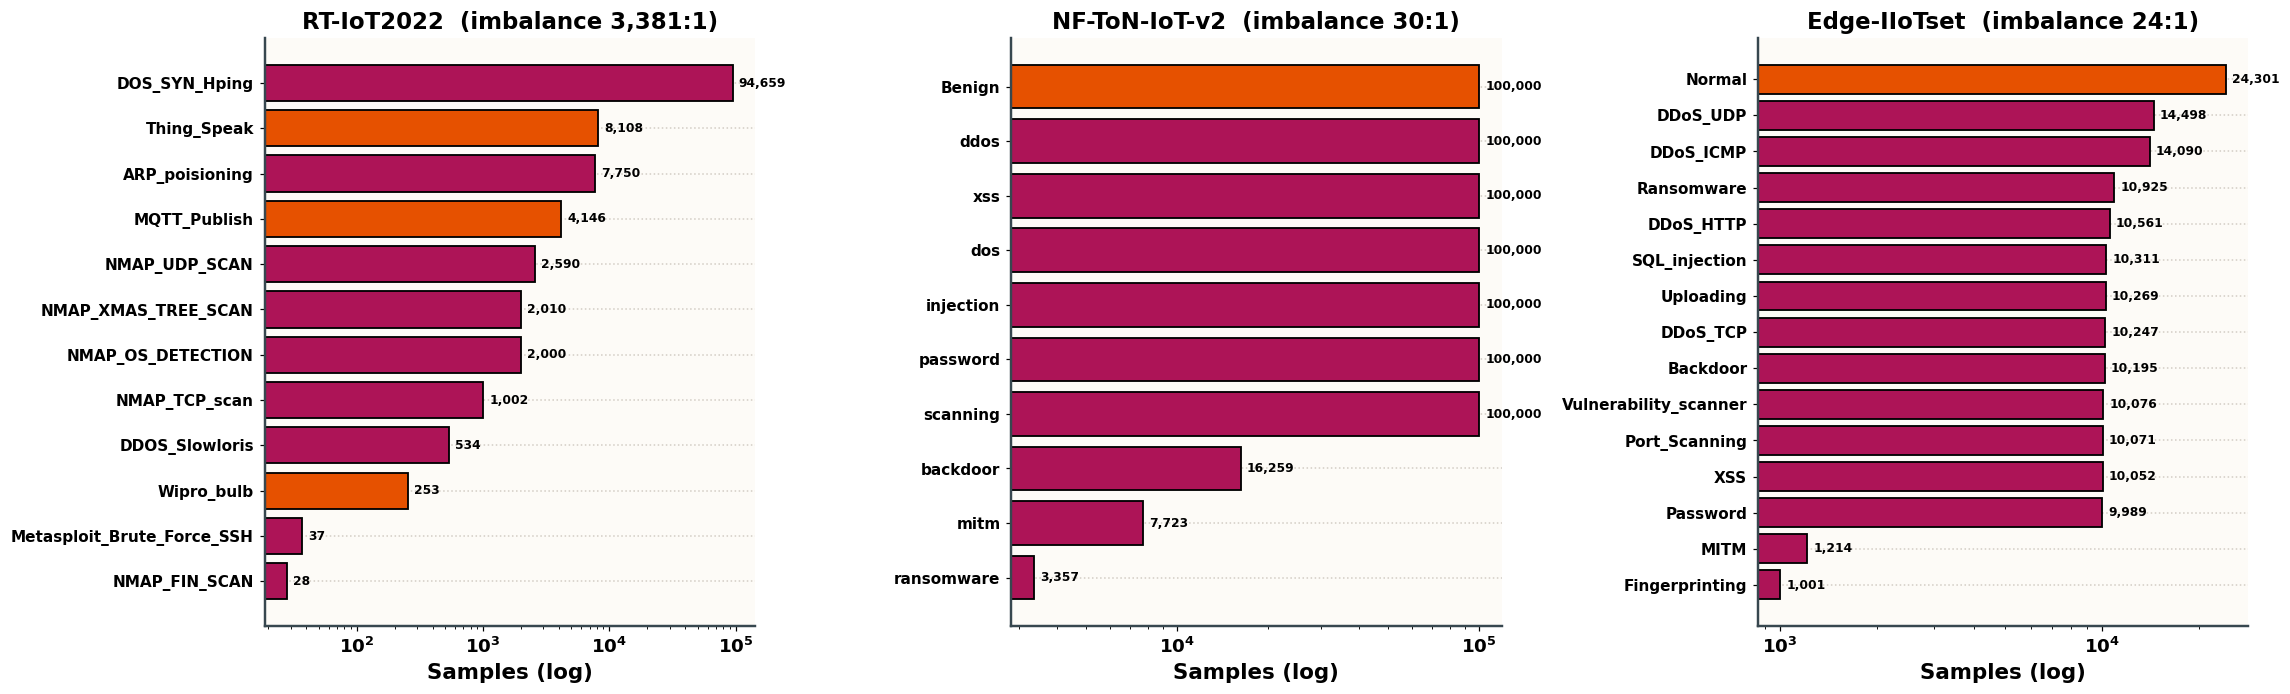

Figure 1. Class distribution across the three OT/ICS/IIoT datasets (log scale; green = benign, red = attack; per-class counts and imbalance ratio annotated).
Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1 is complete


In [5]:
# Cell 3 - Leak-free preprocessing (closed-set + open-set + temporal variants) + Figure 1
#   drop identifiers/IPs -> dedupe -> encode -> scale -> seed-dependent split
#   Edge-IIoTset additionally supports a CHRONOLOGICAL split (frame.time) so flows
#   from one attack session cannot straddle train and test.
# ----------------------------------------------------------------------------------------
print('Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1')
DROP_COLS = {
 "RT-IoT2022": [],
 "NF-ToN-IoT-v2": ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Label"],
 "Edge-IIoTset": ["frame.time","ip.src_host","ip.dst_host","arp.src.proto_ipv4",
     "arp.dst.proto_ipv4","http.file_data","http.request.full_uri","icmp.transmit_timestamp",
     "http.request.uri.query","tcp.options","tcp.payload","tcp.srcport","tcp.dstport",
     "udp.port","mqtt.msg","Attack_label"],
}
MAX_CARD = 16

def _clean(df, label_col, drop_cols):
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    df = df.dropna(subset=[label_col]).drop_duplicates().reset_index(drop=True)
    y_raw = df[label_col].astype(str).values
    X = df.drop(columns=[label_col])
    obj  = X.select_dtypes(include="object").columns
    keep = [c for c in obj if X[c].nunique() <= MAX_CARD]
    X = X.drop(columns=[c for c in obj if c not in keep])
    X = pd.get_dummies(X, columns=keep, dummy_na=False)
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0).astype(np.float32)
    X = X.loc[:, X.std(axis=0) > 0]
    return df, X, y_raw

def _fit_scaler(Xtr, seed):
    return QuantileTransformer(n_quantiles=min(1000, len(Xtr)),
                               output_distribution="normal", subsample=200_000,
                               random_state=seed).fit(Xtr)   # rank-Gaussian: MLP-friendly heavy tails

def preprocess(df, label_col, drop_cols, seed):
    df, X, y_raw = _clean(df, label_col, drop_cols)
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    Xtr, Xte, ytr, yte, rtr, rte = train_test_split(
        X.values, y, np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    sc = _fit_scaler(Xtr, seed)
    return dict(Xtr=sc.transform(Xtr).astype(np.float32), Xte=sc.transform(Xte).astype(np.float32),
                ytr=ytr, yte=yte, classes=le.classes_, feat_names=list(X.columns),
                raw_train=df.iloc[rtr], raw_test=df.iloc[rte])

def preprocess_temporal(df, label_col, drop_cols, seed, time_col="frame.time", min_train=10):
    # per-class chronological 80/20 split: within EACH class, the first 80% of
    # flows (by capture time) -> train, the last 20% -> test. Edge-IIoTset is
    # composed of per-attack capture sessions (each class is a contiguous time
    # block), so a GLOBAL time cut strands most classes entirely on one side;
    # the within-class cut keeps every class while still preventing flows from
    # one capture session straddling train and test (except the single session
    # at each class's boundary). Falls back to the random split when the time
    # column is unavailable.
    if time_col not in df.columns:
        print(f"   temporal split requested but '{time_col}' missing - falling back to random split")
        return preprocess(df, label_col, drop_cols, seed)
    ts = pd.to_datetime(df[time_col], errors="coerce")
    df = df.iloc[np.argsort(ts.fillna(ts.max()).values, kind="stable")].reset_index(drop=True)
    df, X, y_raw = _clean(df, label_col, drop_cols)          # order-preserving; drops time_col
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    tr_list, te_list, dropped = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]                            # already time-ordered
        cut = int(0.8 * len(idx))
        if cut < min_train or len(idx) - cut < 1:
            dropped.append(str(le.classes_[c])); continue
        tr_list.append(idx[:cut]); te_list.append(idx[cut:])
    tr = np.sort(np.concatenate(tr_list)); te = np.sort(np.concatenate(te_list))
    keep = np.unique(y[tr])
    remap = np.full(int(y.max()) + 1, -1, dtype=np.int64)    # integer lookup, never object dtype
    remap[keep] = np.arange(len(keep))
    if dropped:
        print(f"   temporal split: dropped classes with <{min_train} train rows: {dropped}")
    sc = _fit_scaler(X.values[tr], seed)
    return dict(Xtr=sc.transform(X.values[tr]).astype(np.float32),
                Xte=sc.transform(X.values[te]).astype(np.float32),
                ytr=remap[y[tr]], yte=remap[y[te]], classes=le.classes_[keep],
                feat_names=list(X.columns),
                raw_train=df.iloc[tr], raw_test=df.iloc[te])

def preprocess_openset(df, label_col, drop_cols, seed, holdout, cap=20_000):
    # withhold an entire attack family from training; it appears only at test time
    df, X, y_raw = _clean(df, label_col, drop_cols)
    hold_idx  = np.where(y_raw == holdout)[0]
    known_idx = np.where(y_raw != holdout)[0]
    le = LabelEncoder(); y_known = le.fit_transform(y_raw[known_idx])
    tr_i, te_i = train_test_split(np.arange(len(known_idx)), test_size=0.2,
                                  stratify=y_known, random_state=seed)
    rng = np.random.RandomState(seed)
    hold_idx = rng.choice(hold_idx, min(len(hold_idx), cap), replace=False)
    tr_g, te_g = known_idx[tr_i], known_idx[te_i]
    sc = _fit_scaler(X.values[tr_g], seed)
    return dict(Xtr=sc.transform(X.values[tr_g]).astype(np.float32), ytr=y_known[tr_i],
                Xte=sc.transform(X.values[te_g]).astype(np.float32), yte=y_known[te_i],
                Xhold=sc.transform(X.values[hold_idx]).astype(np.float32),
                classes=le.classes_, raw_train=df.iloc[tr_g], raw_test=df.iloc[te_g],
                raw_hold=df.iloc[hold_idx])

# Figure 1: class distributions (benign=green, attack=red) with imbalance ratio
BENIGN_KEYS = ("benign","normal","mqtt_publish","thing_speak","wipro","alexa")
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (name, df) in zip(axes, DATASETS.items()):
    counts = df[LABEL_COL[name]].astype(str).value_counts()
    colors = ["#E65100" if any(k in l.lower() for k in BENIGN_KEYS) else "#AD1457"
              for l in counts.index]
    ax.barh(range(len(counts)), counts.values, color=colors, edgecolor="black", linewidth=1.2)
    for yi, v in enumerate(counts.values):
        ax.annotate(f"{v:,}", (v, yi), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, fontweight="bold")
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels(counts.index, fontweight="bold", fontsize=10)
    ir = counts.max() / max(counts.min(), 1)
    ax.set_xscale("log"); ax.set_xlabel("Samples (log)")
    ax.set_title(f"{name}  (imbalance {ir:,.0f}:1)")
    ax.invert_yaxis(); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_class_distribution.png"); plt.show()
print("Figure 1. Class distribution across the three OT/ICS/IIoT datasets "
      "(log scale; green = benign, red = attack; per-class counts and imbalance ratio annotated).")
print('Cell 3 - Leak-free preprocessing (closed/open/temporal) + Figure 1 is complete')

In [6]:
# Cell 4 - EviTab-NS architecture
#   CASCADED GREEDY-OBLIVIOUS EVIDENTIAL DECISION TABLES with COVERAGE TABLES and
#   VACUITY-GATED SYMBOLIC EVIDENCE FUSION.
#   * Each table is an OBLIVIOUS tree (one shared (feature, threshold) test per level,
#     CatBoost-style), grown greedily with class-weighted-Gini histogram split search
#     on binned features - no backpropagation, no epochs: CPU-first training.
#   * Leaves hold EVIDENTIAL payloads: occupancy-smoothed Dirichlet class evidence
#     e_leaf[c] = N[leaf, c] / (N[leaf] + KAPPA) - literal training-flow counts, so
#     total evidence answers "how many flows like this did training contain, and how
#     pure were they". alpha = e + 1; vacuity u = C/S is count-backed uncertainty.
#   * A short CONVEX multiplicative refinement (leaf-only, sparse gathers) sharpens
#     decisions without touching the count semantics' non-negativity.
#   * Layer 2 re-runs the same induction with layer-1 class probabilities appended as
#     features (cross-fitted to avoid leakage) - a table-only cascade.
#   * COVERAGE tables: random splits + occupancy-only leaves = an unsupervised density
#     channel in the SAME lookup format; leaf-rarity is a native novelty score that
#     does not depend on class-discriminative splits.
#   * Deployment: every component is already a table - inference is threshold
#     comparisons + lookups + sums, ZERO matrix multiplications, no ML runtime needed.
# -----------------------------------------------------------------------------------
print('Cell 4 - EviTab-NS architecture (cascaded evidential decision tables) + deployment utilities')

# histogram binning
def fit_bin_edges(X, B=None, sub=100_000, seed=0):
    B = B or N_BINS
    rng = np.random.RandomState(seed)
    S = X[rng.choice(len(X), min(len(X), sub), replace=False)]
    return np.quantile(S, np.linspace(0, 1, B + 1)[1:-1], axis=0).T.astype(np.float32)  # (F, B-1)

def bin_codes(X, edges, chunk=200_000):
    out = np.empty(X.shape, dtype=np.uint8)
    for i in range(0, len(X), chunk):
        for f in range(X.shape[1]):
            out[i:i+chunk, f] = np.searchsorted(edges[f], X[i:i+chunk, f], side="left")
    return out

# greedy oblivious growth: one shared split per LEVEL
def grow_oblivious(codes, y, w, F_sub, D, B, C, rng):
    n, F = codes.shape
    fsub = rng.choice(F, F_sub, replace=False)
    leaf = np.zeros(n, dtype=np.int32)
    feats, bins = [], []
    for d in range(D):
        L = 1 << d
        hist = np.zeros(L * F_sub * B * C, dtype=np.float64)
        base = (leaf * F_sub)[:, None] + np.arange(F_sub)[None, :]
        idx = (base * B + codes[:, fsub].astype(np.int32)) * C + y[:, None]
        np.add.at(hist, idx.ravel(), np.repeat(w, F_sub))
        hist = hist.reshape(L, F_sub, B, C)
        cum = hist.cumsum(2)
        tot = cum[:, :, -1:, :]
        left, right = cum, tot - cum
        nl, nr = left.sum(3), right.sum(3)
        gini_l = 1.0 - (left ** 2).sum(3) / np.maximum(nl, 1e-9) ** 2
        gini_r = 1.0 - (right ** 2).sum(3) / np.maximum(nr, 1e-9) ** 2
        parent = 1.0 - (tot ** 2).sum(3) / np.maximum(tot.sum(3), 1e-9) ** 2
        gain = (parent * tot.sum(3) - gini_l * nl - gini_r * nr).sum(0)   # oblivious: shared split
        gain[:, -1] = -np.inf
        f_loc, b_star = np.unravel_index(np.argmax(gain), gain.shape)
        feats.append(fsub[f_loc]); bins.append(b_star)
        leaf = leaf * 2 + (codes[:, fsub[f_loc]] > b_star).astype(np.int32)
    return np.array(feats, dtype=np.int16), np.array(bins), leaf

# evidential table ensemble (one cascade layer)
def table_ids(X, feat, thr, D, chunk=200_000):
    out = np.empty((len(X), feat.shape[0]), dtype=np.int32)
    for i in range(0, len(X), chunk):
        bits = X[i:i+chunk][:, feat] > thr
        v = np.zeros(bits.shape[:2], dtype=np.int32)
        for j in range(D):
            v = v * 2 + bits[:, :, j].astype(np.int32)
        out[i:i+chunk] = v
    return out

def fit_layer(Xtr, ytr, C, T, D, seed, Xva=None, yva=None, track=None, tag=""):
    """Grow T greedy-oblivious tables; leaves = occupancy-smoothed count evidence;
    then convex multiplicative refinement. Optionally records (n_tables, val_acc)."""
    t0 = time.time()
    B, L = N_BINS, 1 << D
    edges = fit_bin_edges(Xtr, B, seed=seed)
    codes = bin_codes(Xtr, edges)
    wc = np.clip(len(ytr) / (C * np.bincount(ytr, minlength=C) + 1e-9), .2, 20)
    w = wc[ytr]
    rng = np.random.RandomState(seed)
    F_sub = max(2, int(round(Xtr.shape[1] * F_FRAC)))
    feat = np.empty((T, D), dtype=np.int16); thr = np.empty((T, D), dtype=np.float32)
    leaf_tab = np.empty((T, L, C), dtype=np.float32)
    all_ids = np.empty((len(ytr), T), dtype=np.int32)
    ids_va = None
    if Xva is not None:
        run_ev_va = np.zeros((len(yva), C), dtype=np.float32)
    for t in range(T):
        sub = rng.choice(len(ytr), min(len(ytr), TREE_SUB), replace=True)
        f_t, b_t, _ = grow_oblivious(codes[sub], ytr[sub], w[sub], F_sub, D, B, C, rng)
        feat[t] = f_t
        thr[t] = edges[f_t, np.minimum(b_t, edges.shape[1] - 1)]
        bits = codes[:, f_t] > b_t
        ids = np.zeros(len(ytr), dtype=np.int32)
        for j in range(D):
            ids = ids * 2 + bits[:, j].astype(np.int32)
        N = np.bincount(ids * C + ytr, minlength=L * C).reshape(L, C).astype(np.float64)
        leaf_tab[t] = (N / (N.sum(1, keepdims=True) + KAPPA)).astype(np.float32)
        all_ids[:, t] = ids
        if Xva is not None:
            ids_v = table_ids(Xva, feat[t:t+1], thr[t:t+1], D)[:, 0]
            run_ev_va += leaf_tab[t][ids_v]
            if (t + 1) % 8 == 0 or t == T - 1:
                track.append((t + 1, float((run_ev_va.argmax(1) == yva).mean())))
    # convex multiplicative leaf refinement (decision sharpening)
    # * DUAL PAYLOAD: the pristine count leaves (leaf0) are kept for the evidential /
    #   novelty channel; refinement only produces the DECISION leaves.
    # * mild sqrt class weights (clamped [0.5, 4]): full inverse-frequency weights tilt
    #   argmax toward rare classes and cost several accuracy points on imbalanced test
    #   sets (high AUC, low accuracy pattern) while adding seed variance.
    # * 10% internal holdout with best-state restore on ACCURACY: refinement can only
    #   help the metric it is judged on.
    leaf0 = leaf_tab.copy()
    if REFINE_EPOCHS:
        if len(ytr) > REFINE_MAX:
            s = rng.choice(len(ytr), REFINE_MAX, replace=False)
            ids_r, y_r = all_ids[s].astype(np.int64), ytr[s]
        else:
            ids_r, y_r = all_ids.astype(np.int64), ytr
        th = torch.zeros(T * L, C, requires_grad=True)
        baset = torch.tensor(leaf_tab.reshape(T * L, C))
        idt = torch.tensor(ids_r) + (torch.arange(T) * L)[None, :]
        yt = torch.tensor(y_r)
        if Xva is not None:               # early-stop on the SAME validation split used
            idh = (torch.tensor(table_ids(Xva, feat, thr, D).astype(np.int64))
                   + (torch.arange(T) * L)[None, :])           # for model selection
            yh = torch.tensor(yva); tr_ = np.arange(len(y_r))
        else:                             # no external val (e.g. zero-day fits):
            n_hold = max(2000, len(y_r) // 10)                 # internal 10% holdout
            idh, yh = idt[:n_hold], yt[:n_hold]
            tr_ = np.arange(len(y_r))[n_hold:]
        w_mild = np.sqrt(len(y_r) / (C * np.bincount(y_r, minlength=C) + 1e-9))
        wct = torch.tensor(np.clip(w_mild, .5, 4.), dtype=torch.float32)
        opt = torch.optim.Adam([th], lr=0.15)
        def hold_acc():
            with torch.no_grad():
                acc, nb = 0, 0
                for i in range(0, len(yh), 20000):
                    flat = idh[i:i+20000].reshape(-1)
                    ev = (baset[flat] * torch.exp(th[flat])).reshape(-1, T, C).sum(1)
                    acc += (ev.argmax(1) == yh[i:i+20000]).sum().item(); nb += len(ev)
            return acc / nb
        best_acc, best_th = hold_acc(), th.detach().clone()   # epoch-0 = unrefined
        for ep in range(REFINE_EPOCHS):
            perm = torch.tensor(np.random.RandomState(seed + ep).permutation(tr_))
            for i in range(0, len(perm), 8192):
                b = perm[i:i+8192]
                flat = idt[b].reshape(-1)
                ev = (baset[flat] * torch.exp(th[flat])).reshape(len(b), T, C).sum(1)
                a = ev + 1.0
                loss = F.nll_loss(torch.log(a / a.sum(1, keepdim=True)), yt[b], weight=wct)
                opt.zero_grad(); loss.backward(); opt.step()
            ha = hold_acc()
            if ha > best_acc:
                best_acc, best_th = ha, th.detach().clone()
        leaf_tab = (leaf_tab * np.exp(best_th.numpy().reshape(T, L, C))).astype(np.float32)
        if Xva is not None:
            ids_v = table_ids(Xva, feat, thr, D)
            ev_v = leaf_tab[np.arange(T)[None, :], ids_v].sum(1)
            track.append((T, float((ev_v.argmax(1) == yva).mean())))   # post-refinement point
    return {"feat": feat, "thr": thr, "leaf": leaf_tab, "leaf0": leaf0, "D": D,
            "t_fit": time.time() - t0}

def layer_evidence(X, tab, chunk=200_000):
    T = tab["feat"].shape[0]
    out = np.empty((len(X), tab["leaf"].shape[2]), dtype=np.float32)
    ar = np.arange(T)[None, :]
    for i in range(0, len(X), chunk):
        ids = table_ids(X[i:i+chunk], tab["feat"], tab["thr"], tab["D"])
        leaf = tab["leaf"]
        if leaf.dtype == np.int8:                                   # INT8-leaf variant
            out[i:i+chunk] = (leaf.astype(np.float32)[ar, ids]
                              * tab["scale"][None, :, None]).sum(1)
        else:
            out[i:i+chunk] = leaf[ar, ids].sum(1)
    return out

def prob_np(ev):
    a = ev + 1.0; return a / a.sum(1, keepdims=True)
def vacuity_np(ev):
    a = ev + 1.0; return ev.shape[1] / a.sum(1)
def dissonance_np(ev, bs=50_000):
    out = np.empty(len(ev))
    for i in range(0, len(ev), bs):
        e = ev[i:i + bs]; S = (e + 1.0).sum(1, keepdims=True)
        b = e / S
        bj, bk = b[:, None, :], b[:, :, None]
        bal = 1.0 - np.abs(bj - bk) / (bj + bk + 1e-12)
        np.einsum('bii->bi', bal)[:] = 0.0
        out[i:i + bs] = (b * (b[:, None, :] * bal).sum(2) /
                         (b.sum(1, keepdims=True) - b + 1e-12)).sum(1)
    return out

# adaptive cascade: levels of cross-fitted table pairs, grown while val improves
class EviTabCascade:
    """Every level trains a PAIR of table ensembles on complementary halves
    (2-fold cross-fitting), so the class-probability features passed to the next
    level are always out-of-fold - no stacking leakage at any depth. Levels are
    added while validation accuracy improves (gcForest-style adaptive depth,
    capped at MAX_LEVELS); inference optionally averages level probabilities if
    that helped on validation (variance reduction chosen by the data)."""
    def __init__(self, C):
        self.C = C
    def _fit_pair(self, X, y, T, D, seed, Xva, yva, tag):
        rs = np.random.RandomState(seed)
        half = rs.rand(len(y)) < 0.5
        ok = all(np.isin(np.arange(self.C), y[h]).all() for h in (half, ~half))
        if not ok:
            half = np.zeros(len(y), bool); half[::2] = True          # deterministic fallback
            ok = all(np.isin(np.arange(self.C), y[h]).all() for h in (half, ~half))
        if ok:
            tA = fit_layer(X[half], y[half], self.C, T // 2, D, seed, Xva, yva,
                           self.track, tag + "a")
            tB = fit_layer(X[~half], y[~half], self.C, T - T // 2, D, seed + 1, Xva, yva,
                           self.track, tag + "b")
            p_tr = np.empty((len(y), self.C), dtype=np.float32)
            p_tr[half]  = prob_np(layer_evidence(X[half],  tB))      # cross-fitted
            p_tr[~half] = prob_np(layer_evidence(X[~half], tA))
        else:                                                        # ultra-rare classes
            tA = fit_layer(X, y, self.C, T // 2, D, seed, Xva, yva, self.track, tag + "a")
            tB = fit_layer(X, y, self.C, T - T // 2, D, seed + 1, Xva, yva, self.track, tag + "b")
            p_tr = prob_np(0.5 * (layer_evidence(X, tA) + layer_evidence(X, tB)))
        return (tA, tB), p_tr
    def fit(self, Xtr, ytr, seed, Xva=None, yva=None):
        self.track, self.levels, self.level_marks = [], [], []
        t0 = time.time()
        specs = [(T1, D1)] + [(T2, D2)] * (MAX_LEVELS - 1)
        X_cur, Xva_cur = Xtr, Xva
        best_acc, best_cfg, wait = -1.0, (1, False), 0
        va_last, va_avg_hist = [], []
        for lv, (T, D) in enumerate(specs):
            self.level_marks.append(len(self.track))
            pair, p_tr = self._fit_pair(X_cur, ytr, T, D, seed + 10 * lv, Xva_cur, yva,
                                        f"L{lv+1}")
            self.levels.append(pair)
            X_cur = np.hstack([Xtr, p_tr]).astype(np.float32)
            if Xva is None:
                if lv + 1 >= 2: break
                Xva_cur = None; continue
            p_va = self._level_prob(Xva, lv)
            va_last.append(float((p_va.argmax(1) == yva).mean()))
            va_avg_hist.append(p_va)
            p_avg = np.mean(va_avg_hist, axis=0)
            acc_avg = float((p_avg.argmax(1) == yva).mean())
            for acc, cfg in [(va_last[-1], (lv + 1, False)), (acc_avg, (lv + 1, True))]:
                if acc > best_acc: best_acc, best_cfg, wait = acc, cfg, -1
            wait += 1
            print(f"      level {lv+1}: val last={va_last[-1]:.4f} avg={acc_avg:.4f} "
                  f"(best={best_acc:.4f} @ {best_cfg})", flush=True)
            if wait >= LEVEL_PATIENCE and lv + 1 >= 2: break
            Xva_cur = np.hstack([Xva, p_va]).astype(np.float32)
        self.n_levels, self.use_avg = best_cfg if Xva is not None else (len(self.levels), False)
        self.grown_levels = list(self.levels)          # every grown level (Cell 15 prefixes)
        self.levels = self.levels[: self.n_levels]
        self.level_marks = self.level_marks[: self.n_levels]
        self.l1_end = self.level_marks[1] if len(self.level_marks) > 1 else len(self.track)
        self.cov = fit_coverage(Xtr, seed + 999)
        self.t_fit = time.time() - t0
        return self
    # per-level helpers
    def _level_prob(self, X, upto):
        # probability of level `upto` (0-based), feeding forward from the raw input
        X_cur = X
        for lv in range(upto + 1):
            tA, tB = self.levels[lv]
            e = layer_evidence(X_cur, tA) + layer_evidence(X_cur, tB)
            p = prob_np(e)
            if lv == upto: return p
            X_cur = np.hstack([X, p]).astype(np.float32)
    def _forward(self, X, leaf_key="leaf"):
        # returns (last-level evidence, list of level probs, summed count evidence)
        def lev_ev(Xq, t):
            if leaf_key == "leaf": return layer_evidence(Xq, t)
            o = {**t, "leaf": t["leaf0"].astype(np.float32)}
            o.pop("scale", None)
            return layer_evidence(Xq, o)
        X_cur, probs, e_cnt, e = X, [], 0.0, None
        for lv, (tA, tB) in enumerate(self.levels):
            e = layer_evidence(X_cur, tA) + layer_evidence(X_cur, tB)
            if leaf_key != "leaf":
                e_cnt = e_cnt + lev_ev(X_cur, tA) + lev_ev(X_cur, tB)
            p = prob_np(e)
            probs.append(p)
            if lv + 1 < len(self.levels):
                X_cur = np.hstack([X, p]).astype(np.float32)
        return e, probs, e_cnt
    def evidence(self, X):
        return self._forward(X)[0]                       # last-level (refined) evidence
    def predict_proba(self, X, fused_last_ev=None):
        e, probs, _ = self._forward(X)
        if fused_last_ev is not None:
            probs[-1] = prob_np(fused_last_ev)
        return np.mean(probs, axis=0) if self.use_avg else probs[-1]
    def base_evidence(self, X):
        # pristine COUNT evidence (leaf0) summed over every table of every level:
        # the evidential channel - refinement rescales decisions, never counts
        return self._forward(X, leaf_key="leaf0")[2]
    def novelty_parts(self, X):
        return vacuity_np(self.base_evidence(X)), coverage_rarity(X, self.cov)
    @property
    def all_tabs(self):
        return [t for pair in self.levels for t in pair]

# coverage tables: random splits, occupancy-only leaves
def fit_coverage(Xtr, seed):
    rng = np.random.RandomState(seed)
    Fn, L = Xtr.shape[1], 1 << COV_D
    feat = rng.randint(0, Fn, size=(COV_T, COV_D)).astype(np.int16)
    sub = Xtr[rng.choice(len(Xtr), min(len(Xtr), 60_000), replace=False)]
    q = rng.uniform(0.02, 0.98, size=(COV_T, COV_D))
    srt = np.sort(sub, axis=0)
    thr = srt[(q * (len(sub) - 1)).astype(int), feat].astype(np.float32)
    cnt = np.zeros((COV_T, L), dtype=np.float64)
    for i in range(0, len(Xtr), 200_000):
        ids = table_ids(Xtr[i:i+200_000], feat, thr, COV_D)
        for t in range(COV_T):
            cnt[t] += np.bincount(ids[:, t], minlength=L)
    logp = np.log((cnt + 1.0) / (cnt.sum(1, keepdims=True) + L)).astype(np.float32)
    return {"feat": feat, "thr": thr, "logp": logp, "D": COV_D}

def coverage_rarity(X, cov, chunk=200_000):
    T = cov["feat"].shape[0]
    out = np.empty(len(X), dtype=np.float32)
    ar = np.arange(T)[None, :]
    for i in range(0, len(X), chunk):
        ids = table_ids(X[i:i+chunk], cov["feat"], cov["thr"], cov["D"])
        out[i:i+chunk] = -cov["logp"][ar, ids].mean(1)
    return out

# deployment: INT8 leaves + sizes
def quantize_leaves_int8(tab):
    # decision leaves -> INT8 (guarded by the <=1pt accuray);
    # count leaves (evidential/novelty payload) -> FP16: they feed vacuity, whose
    # ranking is sensitive to coarse quantization of small summed purities
    out = {"feat": tab["feat"], "thr": tab["thr"], "D": tab["D"]}
    scale = np.maximum(np.abs(tab["leaf"]).max(axis=(1, 2)), 1e-9) / 127.0
    out["leaf"] = np.clip(np.round(tab["leaf"] / scale[:, None, None]), -127, 127).astype(np.int8)
    out["scale"] = scale.astype(np.float32)
    if "leaf0" in tab:
        out["leaf0"] = tab["leaf0"].astype(np.float16)
    return out

def tab_size_kb(tab, with_novelty=True):
    kb = (tab["feat"].nbytes + tab["thr"].nbytes) / 1024
    kb += (tab["leaf"].nbytes if "leaf" in tab else tab["logp"].nbytes) / 1024
    kb += tab["scale"].nbytes / 1024 if "scale" in tab else 0
    if with_novelty and "leaf0" in tab:                 # count-evidence payload
        kb += tab["leaf0"].nbytes / 1024
    return kb

def model_size_kb(model, int8=False, with_novelty=True):
    kb = sum(tab_size_kb(quantize_leaves_int8(t) if int8 else t, with_novelty)
             for t in model.all_tabs)
    return kb + (tab_size_kb(model.cov) if with_novelty else 0)

GROUPS = ["BENIGN","DOS","SCAN","BRUTE","WEB","MALWARE","MITM","OTHER"]
def class_to_group(label):
    l = label.lower()
    if any(k in l for k in ("ddos","dos","slowloris","hping","flood")):            return "DOS"
    if any(k in l for k in ("scan","nmap","recon","fingerprint","xmas","os_detection")): return "SCAN"
    if any(k in l for k in ("brute","password")):                                  return "BRUTE"
    if any(k in l for k in ("xss","injection","sql","upload")):                    return "WEB"
    if any(k in l for k in ("backdoor","ransom","malware")):                       return "MALWARE"
    if any(k in l for k in ("mitm","arp")):                                        return "MITM"
    if any(k in l for k in BENIGN_KEYS):                                           return "BENIGN"
    return "OTHER"

class SymbolicRuleEngine:
    # Fixed, human-auditable rule antecedents -> per-flow activation matrix A (n x n_rules).
    # Thresholds are percentiles of *benign training traffic* (no test/label leakage).
    def __init__(self, name, raw_train, label_col):
        self.name = name
        ben_mask = np.array([class_to_group(s) == "BENIGN" for s in raw_train[label_col].astype(str)])
        ben = raw_train[ben_mask] if ben_mask.any() else raw_train
        g = lambda df, c: np.nan_to_num(df[c].astype(float).values) if c in df.columns else None
        pct = lambda v, q: float(np.nanpercentile(v, q)) if v is not None else np.inf
        self.rules = []
        if name == "RT-IoT2022":
            hi = pct(g(ben, "flow_pkts_per_sec"), 99.5); lo = pct(g(ben, "flow_pkts_per_sec"), 50)
            self.rules = [
             ("flood_rate>p99.5(benign)", "DOS",
              lambda r: (np.nan_to_num(r["flow_pkts_per_sec"].astype(float).values) > hi).astype(float)),
             ("SYN&slow_rate (probe)",    "SCAN",
              lambda r: ((np.nan_to_num(r["flow_SYN_flag_count"].astype(float).values) > 0) &
                         (np.nan_to_num(r["flow_pkts_per_sec"].astype(float).values) < lo)).astype(float)),
             ("dst_port in {22,23}",      "BRUTE",
              lambda r: np.isin(np.nan_to_num(r["id.resp_p"].astype(float).values), [22, 23]).astype(float)),
            ]
        elif name == "NF-ToN-IoT-v2":
            rate = (g(ben, "IN_PKTS") / (g(ben, "FLOW_DURATION_MILLISECONDS") / 1000 + 1e-3)
                    if g(ben, "IN_PKTS") is not None else None)
            hi = pct(rate, 99.5)
            self.rules = [
             ("flood_rate>p99.5(benign)", "DOS",
              lambda r: (np.nan_to_num(r["IN_PKTS"].astype(float).values) /
                         (np.nan_to_num(r["FLOW_DURATION_MILLISECONDS"].astype(float).values)/1000 + 1e-3)
                         > hi).astype(float)),
             ("pure_SYN flags==2",        "SCAN",
              lambda r: (np.nan_to_num(r["TCP_FLAGS"].astype(float).values) == 2).astype(float)),
             ("dst_port in {22,23,3389}", "BRUTE",
              lambda r: np.isin(np.nan_to_num(r["L4_DST_PORT"].astype(float).values),
                                [22, 23, 3389]).astype(float)),
             ("dst_port in {80,443,8080}","WEB",
              lambda r: np.isin(np.nan_to_num(r["L4_DST_PORT"].astype(float).values),
                                [80, 443, 8080]).astype(float)),
            ]
        else:  # Edge-IIoTset
            self.rules = [
             ("SYN w/o SYNACK (half-open)", "SCAN",
              lambda r: ((np.nan_to_num(r["tcp.connection.syn"].astype(float).values) > 0) &
                         (np.nan_to_num(r["tcp.connection.synack"].astype(float).values) == 0)
                         ).astype(float)),
             ("tcp.connection.rst>0",       "DOS",
              lambda r: (np.nan_to_num(r["tcp.connection.rst"].astype(float).values) > 0).astype(float)),
             ("icmp.seq_le>0 (ICMP)",       "DOS",
              lambda r: (np.nan_to_num(r["icmp.seq_le"].astype(float).values) > 0).astype(float)),
            ]
        self.rule_names  = [r[0] for r in self.rules]
        self.rule_groups = [r[1] for r in self.rules]
    def activations(self, raw):
        cols = []
        for _, _, fn in self.rules:
            try:    cols.append(fn(raw))
            except KeyError: cols.append(np.zeros(len(raw)))
        return np.stack(cols, axis=1).astype(np.float32)

class VacuityGatedFusion(nn.Module):
    # e_fused = clip( e + u(e) * (A * w) @ M , 0 ):  auditable rules inject EVIDENCE for
    # their attack group, gated by count-backed vacuity u = C/S - rules are heard exactly
    # on flows that few training examples support, ignored where counts are decisive.
    # w init 0 => exact neural baseline; negative learned weights subtract evidence
    # (the clip keeps alpha = e + 1 a valid Dirichlet).
    def __init__(self, rule_groups, class_groups):
        super().__init__()
        M = torch.tensor([[1.0 if cg == rg else 0.0 for cg in class_groups] for rg in rule_groups])
        self.register_buffer("M", M)
        self.w = nn.Parameter(torch.zeros(len(rule_groups)))
    def forward(self, ev, A):
        a = ev + 1.0
        u = (ev.shape[1] / a.sum(1)).unsqueeze(1)
        return (ev + u * ((A * self.w) @ self.M)).clamp_min(0.0)

def train_fusion(model, d, eng, seed, steps=FUSION_STEPS):
    from sklearn.metrics import f1_score as _f1
    n = len(d["ytr"]); m = min(n, 20_000, max(2_000, n // 10))
    sel = np.random.RandomState(seed).choice(n, size=m, replace=False)
    fit_i, gate_i = sel[: m // 2], sel[m // 2:]
    def parts(idx):
        ev = torch.tensor(model.evidence(d["Xtr"][idx]))
        return ev, torch.tensor(eng.activations(d["raw_train"].iloc[idx])), torch.tensor(d["ytr"][idx])
    ev_f, A_f, y_f = parts(fit_i)
    ev_g, A_g, y_g = parts(gate_i)
    class_groups = [class_to_group(c) for c in d["classes"]]
    fus = VacuityGatedFusion(eng.rule_groups, class_groups)
    n_out = len(d["classes"])
    wts = len(y_f) / (n_out * np.bincount(y_f, minlength=n_out) + 1e-9)
    crit = nn.NLLLoss(weight=torch.tensor(np.clip(wts, .2, 20), dtype=torch.float32))
    opt = torch.optim.Adam(fus.parameters(), lr=0.05, weight_decay=1e-4)
    for _ in range(steps):
        opt.zero_grad()
        a = fus(ev_f, A_f) + 1.0
        loss = crit(torch.log(a / a.sum(1, keepdim=True) + 1e-12), y_f)
        loss.backward(); opt.step()
    fus.eval()
    with torch.no_grad():
        f1_plain = _f1(y_g, ev_g.argmax(1), average="macro", zero_division=0)
        f1_fused = _f1(y_g, fus(ev_g, A_g).argmax(1), average="macro", zero_division=0)
        if f1_fused < f1_plain:
            fus.w.zero_()          # do-no-harm gate: revert to exact neural baseline
    return fus

def apply_fusion(fus, ev_np, A_np):
    with torch.no_grad():
        return fus(torch.tensor(ev_np), torch.tensor(A_np)).numpy()

_l = (T1 * (2 ** D1) + T2 * (2 ** D2)) * 12 * 4 / 1024
print(f"EviTabCascade + coverage tables + SymbolicRuleEngine + VacuityGatedFusion defined | "
      f"example deployment at C=12: ~{_l:.0f} KB FP32 leaf tables (~{_l/4:.0f} KB INT8) "
      f"+ {COV_T * (2**COV_D) * 4 / 1024:.0f} KB coverage")
print('Cell 4 - EviTab-NS architecture is complete')

Cell 4 - EviTab-NS architecture (cascaded evidential decision tables) + deployment utilities
EviTabCascade + coverage tables + SymbolicRuleEngine + VacuityGatedFusion defined | example deployment at C=12: ~16896 KB FP32 leaf tables (~4224 KB INT8) + 128 KB coverage
Cell 4 - EviTab-NS architecture is complete


In [7]:
# Cell 5 - Fixed-seed reference run (reproducible baseline, seed = REP_SEED)
#   EviTab-NS training is COUNTING, not backpropagation: histogram binning, greedy
#   per-level split search, one evidence-counting pass per table, and a short convex
#   leaf refinement on a single CPU core (fit times are printed). A 10% validation split tracks
#   accuracy as tables are added and feeds the fusion do-no-harm gate.
#   The evaluated model IS the deployable artifact: lookup tables, no runtime.
# ---------------------------------------------------------------------------
print('Cell 5 - single-seed reference run')

def softmax_np(lg):
    e = np.exp(lg - lg.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def make_split(name, df, seed):
    if name == "Edge-IIoTset" and TEMPORAL_SPLIT_EDGE:
        return preprocess_temporal(df, LABEL_COL[name], DROP_COLS[name], seed)
    return preprocess(df, LABEL_COL[name], DROP_COLS[name], seed)

def split_train_val(d, name, seed):
    if name == "Edge-IIoTset" and TEMPORAL_SPLIT_EDGE:
        # drift-aware validation: per-class CHRONOLOGICAL tail 10% of train, so both
        # model selection and refinement early stopping face the same forward-in-time
        # condition as the temporal test split (Xtr rows are time-ordered per class)
        idx_tr, idx_va = [], []
        for c in np.unique(d["ytr"]):
            idx = np.where(d["ytr"] == c)[0]
            cut = min(max(1, int(0.9 * len(idx))), len(idx) - 1)
            idx_tr.append(idx[:cut]); idx_va.append(idx[cut:])
        idx_tr, idx_va = np.concatenate(idx_tr), np.concatenate(idx_va)
        return d["Xtr"][idx_tr], d["Xtr"][idx_va], d["ytr"][idx_tr], d["ytr"][idx_va]
    return train_test_split(d["Xtr"], d["ytr"], test_size=0.1,
                            stratify=d["ytr"], random_state=seed)

def fit_model(d, name, seed):
    np.random.seed(seed); torch.manual_seed(seed)
    Xtr, Xva, ytr, yva = split_train_val(d, name, seed)
    model = EviTabCascade(len(d["classes"])).fit(Xtr, ytr, seed, Xva=Xva, yva=yva)
    va = float((model.predict_proba(Xva).argmax(1) == yva).mean())
    lv_s = " + ".join(f"L{i+1} {tA['t_fit']+tB['t_fit']:.0f}s"
                      for i, (tA, tB) in enumerate(model.levels))
    print(f"   {name} | seed {seed} | {lv_s} = {model.t_fit:.0f}s total | "
          f"levels={model.n_levels} avg-infer={model.use_avg} | final val-acc={va:.4f}",
          flush=True)
    return model, model.track, va, model.t_fit

def metric_pack(y, ev, classes, proba=None):
    # ev: evidence/logits for argmax fallback; pass 'proba' directly when the model
    # supplies calibrated probabilities (e.g. validated level-averaged cascade output)
    if proba is None:
        proba = prob_np(ev) if (ev >= 0).all() else softmax_np(ev)
    pred = proba.argmax(1)
    pm, rm, f1m, _ = precision_recall_fscore_support(y, pred, average="macro",    zero_division=0)
    pw, rw, f1w, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    try:   auc = roc_auc_score(y, proba, multi_class="ovr", average="macro")
    except ValueError: auc = np.nan
    try:
        Y1 = np.eye(len(classes))[y]
        pr_auc = average_precision_score(Y1, proba, average="macro")
    except ValueError:
        pr_auc = np.nan
    ben = np.array([class_to_group(c) == "BENIGN" for c in classes])
    if ben.any() and (~ben).any():
        y_att, p_att = ~ben[y], ~ben[pred]
        TP = int(( y_att &  p_att).sum()); TN = int((~y_att & ~p_att).sum())
        FP = int((~y_att &  p_att).sum()); FN = int(( y_att & ~p_att).sum())
        tpr, tnr = TP / max(TP + FN, 1), TN / max(TN + FP, 1)
        det = dict(det_tpr=tpr, det_tnr=tnr, det_fpr=FP/max(TN+FP,1),
                   det_fnr=FN/max(TP+FN,1), gmean=float(np.sqrt(tpr * tnr)),
                   TP=TP, TN=TN, FP=FP, FN=FN)
    else:
        det = dict(det_tpr=np.nan, det_tnr=np.nan, det_fpr=np.nan, det_fnr=np.nan,
                   gmean=np.nan, TP=0, TN=0, FP=0, FN=0)
    return dict(acc=accuracy_score(y, pred), prec_m=pm, rec_m=rm, f1_m=f1m,
                prec_w=pw, rec_w=rw, f1_w=f1w, mcc=matthews_corrcoef(y, pred),
                kappa=cohen_kappa_score(y, pred), bal_acc=balanced_accuracy_score(y, pred),
                auc=auc, pr_auc=pr_auc, pred=pred, **det)

def evaluate(name, d, model, eng, fus):
    ev = model.evidence(d["Xte"])
    A_te = eng.activations(d["raw_test"])
    ev_f = apply_fusion(fus, ev, A_te)
    return {"Neural":        metric_pack(d["yte"], ev,
                                         d["classes"], proba=model.predict_proba(d["Xte"])),
            "Neurosymbolic": metric_pack(d["yte"], ev_f, d["classes"],
                                         proba=model.predict_proba(d["Xte"], fused_last_ev=ev_f))}

def run_experiment(name, df, seed, keep_artifacts=False):
    tag = f"exp_{name}_{seed}"
    ck = ckpt_load(tag)
    if ck is not None and (not keep_artifacts or "model" in ck):
        EXP[name].append(ck["rec"])
        print(f"{name:15s} seed={seed}  loaded from {CKPT_DIR / tag}.pkl (no refit) | "
              f"test acc={ck['rec']['res']['Neurosymbolic']['acc']*100:6.2f}%", flush=True)
        if keep_artifacts:        # split + rule engine are deterministic: rebuild, don't store
            d = make_split(name, df, seed)
            eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
            fus = VacuityGatedFusion(eng.rule_groups, [class_to_group(c) for c in d["classes"]])
            with torch.no_grad():
                fus.w.copy_(torch.tensor(ck["w_full"]))
            fus.eval()
            DATA[name], MODELS[name] = d, ck["model"]
            ENGINES[name], FUSIONS[name], RESULTS_REP[name] = eng, fus, ck["res"]
        return
    d = make_split(name, df, seed)
    model, track, best_va, t_s = fit_model(d, name, seed)
    eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
    fus = train_fusion(model, d, eng, seed)
    res = evaluate(name, d, model, eng, fus)
    EXP[name].append({"seed": seed, "track": track, "l1_end": model.l1_end,
                      "marks": model.level_marks, "train_s": t_s,
                      "w": fus.w.detach().numpy().round(4).tolist(),
                      "res": {tag: {k: v for k, v in r.items() if k != "pred"}
                              for tag, r in res.items()}})
    rs = res["Neurosymbolic"]
    print(f"{name:15s} seed={seed}  val-acc={best_va:.4f}  fit={t_s:6.1f}s | "
          f"test acc={rs['acc']*100:6.2f}%  F1m={rs['f1_m']:.4f}  "
          f"learned w={EXP[name][-1]['w']}", flush=True)
    ck = {"rec": EXP[name][-1], "w_full": fus.w.detach().numpy().copy()}
    if keep_artifacts:
        ck.update(model=model, res=res)
    ckpt_save(tag, ck)
    if keep_artifacts:
        DATA[name], MODELS[name] = d, model
        ENGINES[name], FUSIONS[name], RESULTS_REP[name] = eng, fus, res
    else:
        del d

EXP, DATA, MODELS, ENGINES, FUSIONS, RESULTS_REP = {n: [] for n in DATASETS}, {}, {}, {}, {}, {}
if RUN_MAIN_PROTOCOL:
    for name, df in DATASETS.items():
        run_experiment(name, df, REP_SEED, keep_artifacts=True)
else:
    print("   RUN_MAIN_PROTOCOL = False: functions defined, reference run skipped")
print('Cell 5 - single-seed reference run is complete')

Cell 5 - single-seed reference run
RT-IoT2022      seed=42  loaded from checkpoints/exp_RT-IoT2022_42.pkl (no refit) | test acc= 99.68%
NF-ToN-IoT-v2   seed=42  loaded from checkpoints/exp_NF-ToN-IoT-v2_42.pkl (no refit) | test acc= 91.76%
Edge-IIoTset    seed=42  loaded from checkpoints/exp_Edge-IIoTset_42.pkl (no refit) | test acc= 92.73%
Cell 5 - single-seed reference run is complete


In [8]:
# Cell 6 - Multi-seed robustness protocol (additional seeds, fresh split + init)
# -------------------------------------------------------------------------------
print('Cell 6 - Multi-seed robustness protocol')
if RUN_MAIN_PROTOCOL:
    for name, df in DATASETS.items():
        for seed in SEEDS[1:]:
            run_experiment(name, df, seed, keep_artifacts=False)
    print("Robustness runs recorded: " + ", ".join(f"{n}: {len(EXP[n])} seeds" for n in EXP))
    tt = {n: np.array([r["train_s"] for r in EXP[n]]) for n in EXP}
    for n in EXP:
        print(f"training-time efficiency {n:15s}: {tt[n].mean():7.1f} +/- {tt[n].std():5.1f} s/seed")
else:
    print("   RUN_MAIN_PROTOCOL = False: multi-seed runs skipped")
print('Cell 6 - Multi-seed robustness protocol is complete')

Cell 6 - Multi-seed robustness protocol
RT-IoT2022      seed=43  loaded from checkpoints/exp_RT-IoT2022_43.pkl (no refit) | test acc= 99.59%
RT-IoT2022      seed=44  loaded from checkpoints/exp_RT-IoT2022_44.pkl (no refit) | test acc= 99.56%
RT-IoT2022      seed=45  loaded from checkpoints/exp_RT-IoT2022_45.pkl (no refit) | test acc= 99.68%
RT-IoT2022      seed=46  loaded from checkpoints/exp_RT-IoT2022_46.pkl (no refit) | test acc= 99.70%
RT-IoT2022      seed=47  loaded from checkpoints/exp_RT-IoT2022_47.pkl (no refit) | test acc= 99.70%
RT-IoT2022      seed=48  loaded from checkpoints/exp_RT-IoT2022_48.pkl (no refit) | test acc= 99.63%
RT-IoT2022      seed=49  loaded from checkpoints/exp_RT-IoT2022_49.pkl (no refit) | test acc= 99.61%
RT-IoT2022      seed=50  loaded from checkpoints/exp_RT-IoT2022_50.pkl (no refit) | test acc= 99.61%
RT-IoT2022      seed=51  loaded from checkpoints/exp_RT-IoT2022_51.pkl (no refit) | test acc= 99.59%
NF-ToN-IoT-v2   seed=43  loaded from checkpoints/ex

Cell 7 - Figure 2: table-by-table learning curves


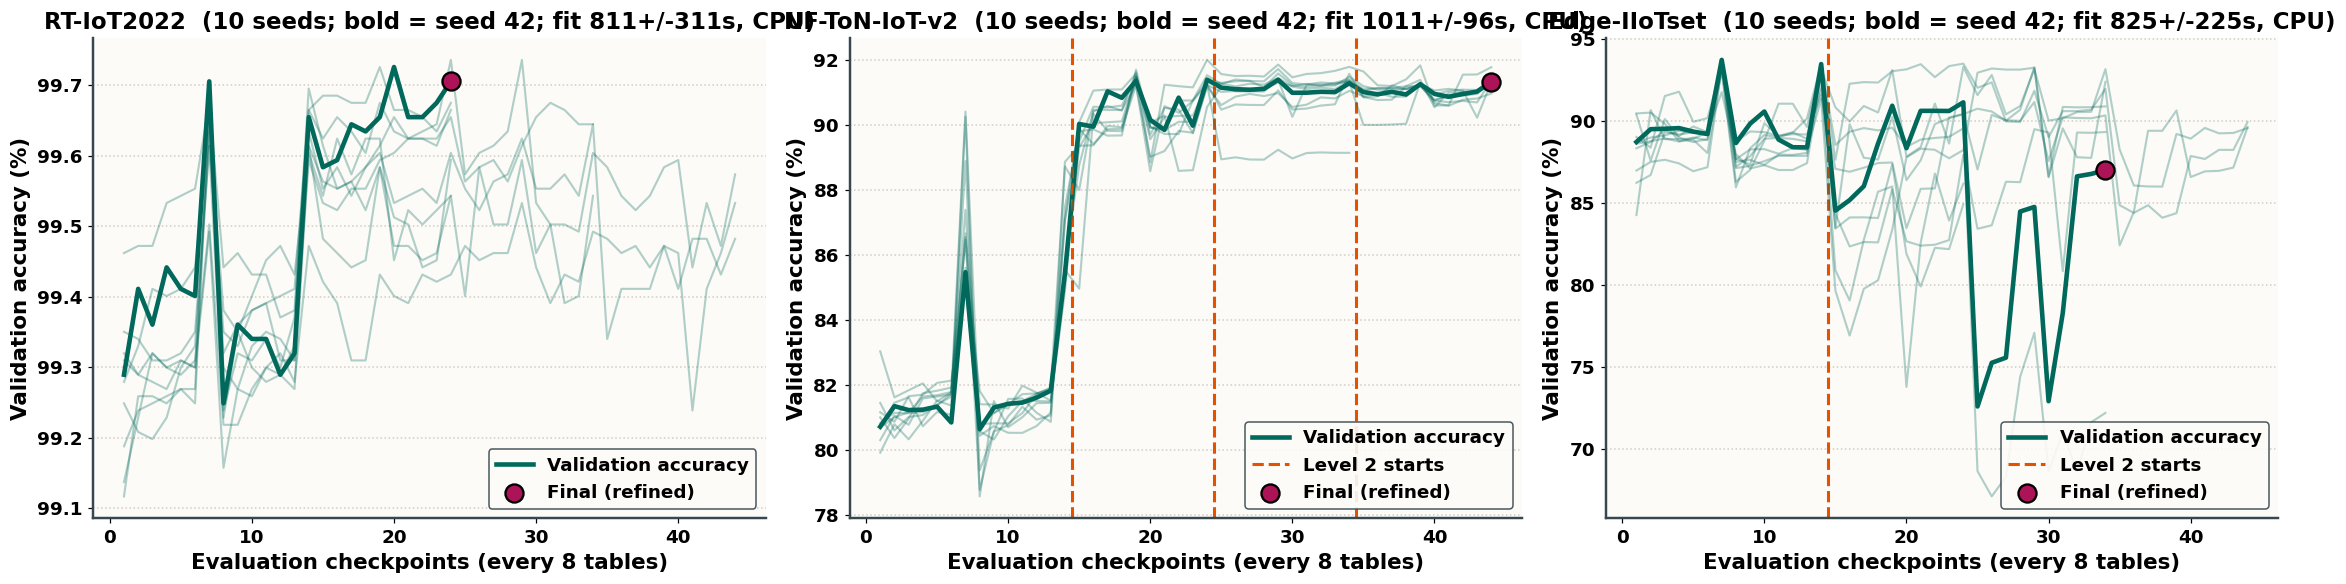

Figure 2. Validation accuracy as decision tables are added (bold = fixed reference seed); dashed lines mark the start of each adaptively-added cascade level and the dot the final convex leaf refinement. Titles report per-seed CPU fit time.
Cell 7 - Figure 2: table-by-table learning curves is complete


In [9]:
# Cell 7 - Figure 2: table-by-table learning curves + fit-time budget across all seeds
#   Validation accuracy is recorded every 8 tables while the cascade grows; dashed
#   lines mark where each new level starts (levels are added adaptively while
#   validation improves). Titles report the per-seed CPU fit time: training is
#   counting + greedy split search, not backpropagation.
# -----------------------------------------------------------------------------
print('Cell 7 - Figure 2: table-by-table learning curves')
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, name in zip(axes, EXP):
    for run in EXP[name]:
        rep = run["seed"] == REP_SEED
        acc = np.array([a for _, a in run["track"]]) * 100
        xs = np.arange(1, len(acc) + 1)
        ax.plot(xs, acc, color="#00695C", alpha=1.0 if rep else 0.30,
                linewidth=3 if rep else 1.4,
                label="Validation accuracy" if rep else None)
        if rep:
            for k, mk in enumerate(run.get("marks", [])[1:], start=2):
                ax.axvline(mk + 0.5, color="#E65100", linestyle="--", linewidth=2.0,
                           label=f"Level {k} starts" if k == 2 else None)
            ax.scatter([xs[-1]], [acc[-1]], s=140, color="#AD1457", zorder=5,
                       edgecolor="black", linewidth=1.5, label="Final (refined)")
    ts = np.array([r["train_s"] for r in EXP[name]])
    ax.set_xlabel("Evaluation checkpoints (every 8 tables)")
    ax.set_ylabel("Validation accuracy (%)")
    ax.set_title(f"{name}  ({len(EXP[name])} seeds; bold = seed {REP_SEED}; "
                 f"fit {ts.mean():.0f}+/-{ts.std():.0f}s, CPU)")
    ax.legend(loc="lower right", framealpha=.9, prop={"weight": "bold"})
    bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_training_curves.png"); plt.show()
print("Figure 2. Validation accuracy as decision tables are added (bold = fixed reference "
      "seed); dashed lines mark the start of each adaptively-added cascade level and the "
      "dot the final convex leaf refinement. Titles report per-seed CPU fit time.")
print('Cell 7 - Figure 2: table-by-table learning curves is complete')

In [10]:
# Cell 8 - Aggregated metrics (mean +/- std), significance tests with bootstrap
#          95% CIs and Cohen's d_z, learned rule-weight interpretability table,
#          per-class report
# -------------------------------------------------------------------------------
print('Cell 8 - Aggregated metrics, significance tests (CIs + effect size), learned rule weights')

def agg(name, tag, key):
    v = np.array([run["res"][tag][key] for run in EXP[name]], dtype=float)
    return v.mean(), v.std()

METRIC_KEYS = [("acc","Accuracy"), ("prec_m","Precision-M"), ("rec_m","Recall-M"),
               ("f1_m","F1-Macro"), ("prec_w","Precision-W"), ("rec_w","Recall-W"),
               ("f1_w","F1-Weighted"), ("mcc","MCC"), ("kappa","Cohen-kappa"),
               ("bal_acc","Balanced-Acc"), ("gmean","G-mean"), ("auc","ROC-AUC"),
               ("pr_auc","PR-AUC")]
SIGNIF = {}
for name in EXP:
    print(f"\n{'-'*18} {name}  (mean +/- std over {len(EXP[name])} seeds) {'-'*18}")
    for tag in ("Neural", "Neurosymbolic"):
        parts = []
        for k, lab in METRIC_KEYS:
            mu, sd = agg(name, tag, k)
            parts.append(f"{lab}={mu*100:.2f}+/-{sd*100:.2f}" if k == "acc"
                         else f"{lab}={mu:.4f}+/-{sd:.4f}")
        print(f"{tag:13s} " + "  ".join(parts[:4]))
        print(f"{'':13s} " + "  ".join(parts[4:9]))
        print(f"{'':13s} " + "  ".join(parts[9:]))
    # paired significance: neural vs neurosymbolic across seeds (macro-F1 headline)
    # p-values are complemented with a paired bootstrap 95% CI on the mean
    # difference and Cohen's d_z, so claims never rest on small-n p-values alone
    SIGNIF[name] = {}
    for k, lab in [("f1_m", "F1-Macro"), ("acc", "Accuracy")]:
        a = np.array([r["res"]["Neural"][k] for r in EXP[name]])
        b = np.array([r["res"]["Neurosymbolic"][k] for r in EXP[name]])
        diff = b - a
        if np.allclose(a, b):
            wp = tp = np.nan
            verdict = "identical (learned weights ~0: symbolic evidence not useful here)"
        else:
            try:    wp = wilcoxon(a, b).pvalue
            except ValueError: wp = np.nan
            tp = ttest_rel(a, b).pvalue
            rng = np.random.RandomState(0)
            boots = np.array([rng.choice(diff, len(diff), replace=True).mean()
                              for _ in range(10_000)])
            lo, hi = np.percentile(boots, [2.5, 97.5])
            dz = diff.mean() / (diff.std(ddof=1) + 1e-12)
            verdict = (f"delta={diff.mean():+.4f} 95%CI[{lo:+.4f},{hi:+.4f}] d_z={dz:+.2f} | "
                       f"Wilcoxon p={wp:.4f}, paired t p={tp:.4f} (n={len(a)})")
        SIGNIF[name][k] = (wp, tp)
        print(f"significance [{lab}] neural vs neurosymbolic: {verdict}")
    print("learned rule evidence weights (per seed):")
    eng = ENGINES[name]
    for run in EXP[name]:
        print(f"  seed {run['seed']}: " + ", ".join(f"{n}[{g}]={w:+.3f}"
              for n, g, w in zip(eng.rule_names, eng.rule_groups, run["w"])))
    # binary attack-vs-benign detection metrics (mean +/- std over seeds)
    parts = []
    for k, lab in [("det_tpr","DR/TPR"), ("det_fpr","FAR/FPR"),
                   ("det_tnr","TNR"), ("det_fnr","FNR")]:
        mu, sd = agg(name, "Neurosymbolic", k)
        parts.append(f"{lab}={mu:.4f}+/-{sd:.4f}")
    print("attack-vs-benign detection: " + "  ".join(parts))
    print(f"\nPer-class report (representative seed {REP_SEED}, neurosymbolic):")
    print(classification_report(DATA[name]["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"],
                                target_names=DATA[name]["classes"], digits=4, zero_division=0))

# per-class one-vs-rest TP/TN/FP/FN + TPR/TNR/FPR/FNR table (rep seed, neurosymbolic)
CONF_ROWS = []
for name, d in DATA.items():
    y, pred, N = d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"], len(d["yte"])
    print(f"\n--- {name}: per-class confusion-derived metrics (seed {REP_SEED}) ---")
    tab = []
    for ci, cls in enumerate(d["classes"]):
        TP = int(((y == ci) & (pred == ci)).sum()); FN = int(((y == ci) & (pred != ci)).sum())
        FP = int(((y != ci) & (pred == ci)).sum()); TN = N - TP - FN - FP
        row = dict(Dataset=name, Class=cls, TP=TP, TN=TN, FP=FP, FN=FN,
                   TPR=round(TP/max(TP+FN,1),4), TNR=round(TN/max(TN+FP,1),4),
                   FPR=round(FP/max(TN+FP,1),4), FNR=round(FN/max(TP+FN,1),4),
                   Precision=round(TP/max(TP+FP,1),4))
        tab.append(row); CONF_ROWS.append(row)
    print(pd.DataFrame(tab).drop(columns="Dataset").to_string(index=False))
pd.DataFrame(CONF_ROWS).to_csv("perclass_confusion_metrics.csv", index=False)
print("\nper-class TP/TN/FP/FN table saved -> perclass_confusion_metrics.csv")
print('Cell 8 - Aggregated metrics, significance tests, learned rule weights is complete')

Cell 8 - Aggregated metrics, significance tests (CIs + effect size), learned rule weights

------------------ RT-IoT2022  (mean +/- std over 10 seeds) ------------------
Neural        Accuracy=99.64+/-0.05  Precision-M=0.9754+/-0.0073  Recall-M=0.9371+/-0.0206  F1-Macro=0.9479+/-0.0143
              Precision-W=0.9965+/-0.0005  Recall-W=0.9964+/-0.0005  F1-Weighted=0.9963+/-0.0005  MCC=0.9909+/-0.0012  Cohen-kappa=0.9909+/-0.0013
              Balanced-Acc=0.9371+/-0.0206  G-mean=0.9928+/-0.0018  ROC-AUC=0.9998+/-0.0001  PR-AUC=0.9681+/-0.0124
Neurosymbolic Accuracy=99.64+/-0.05  Precision-M=0.9754+/-0.0073  Recall-M=0.9371+/-0.0206  F1-Macro=0.9479+/-0.0143
              Precision-W=0.9965+/-0.0005  Recall-W=0.9964+/-0.0005  F1-Weighted=0.9963+/-0.0005  MCC=0.9909+/-0.0012  Cohen-kappa=0.9909+/-0.0013
              Balanced-Acc=0.9371+/-0.0206  G-mean=0.9928+/-0.0018  ROC-AUC=0.9998+/-0.0001  PR-AUC=0.9681+/-0.0124
significance [F1-Macro] neural vs neurosymbolic: identical (learned we

Cell 9 - Figure 3: confusion matrices | Figure 4: per-class precision/recall/F1 heatmap


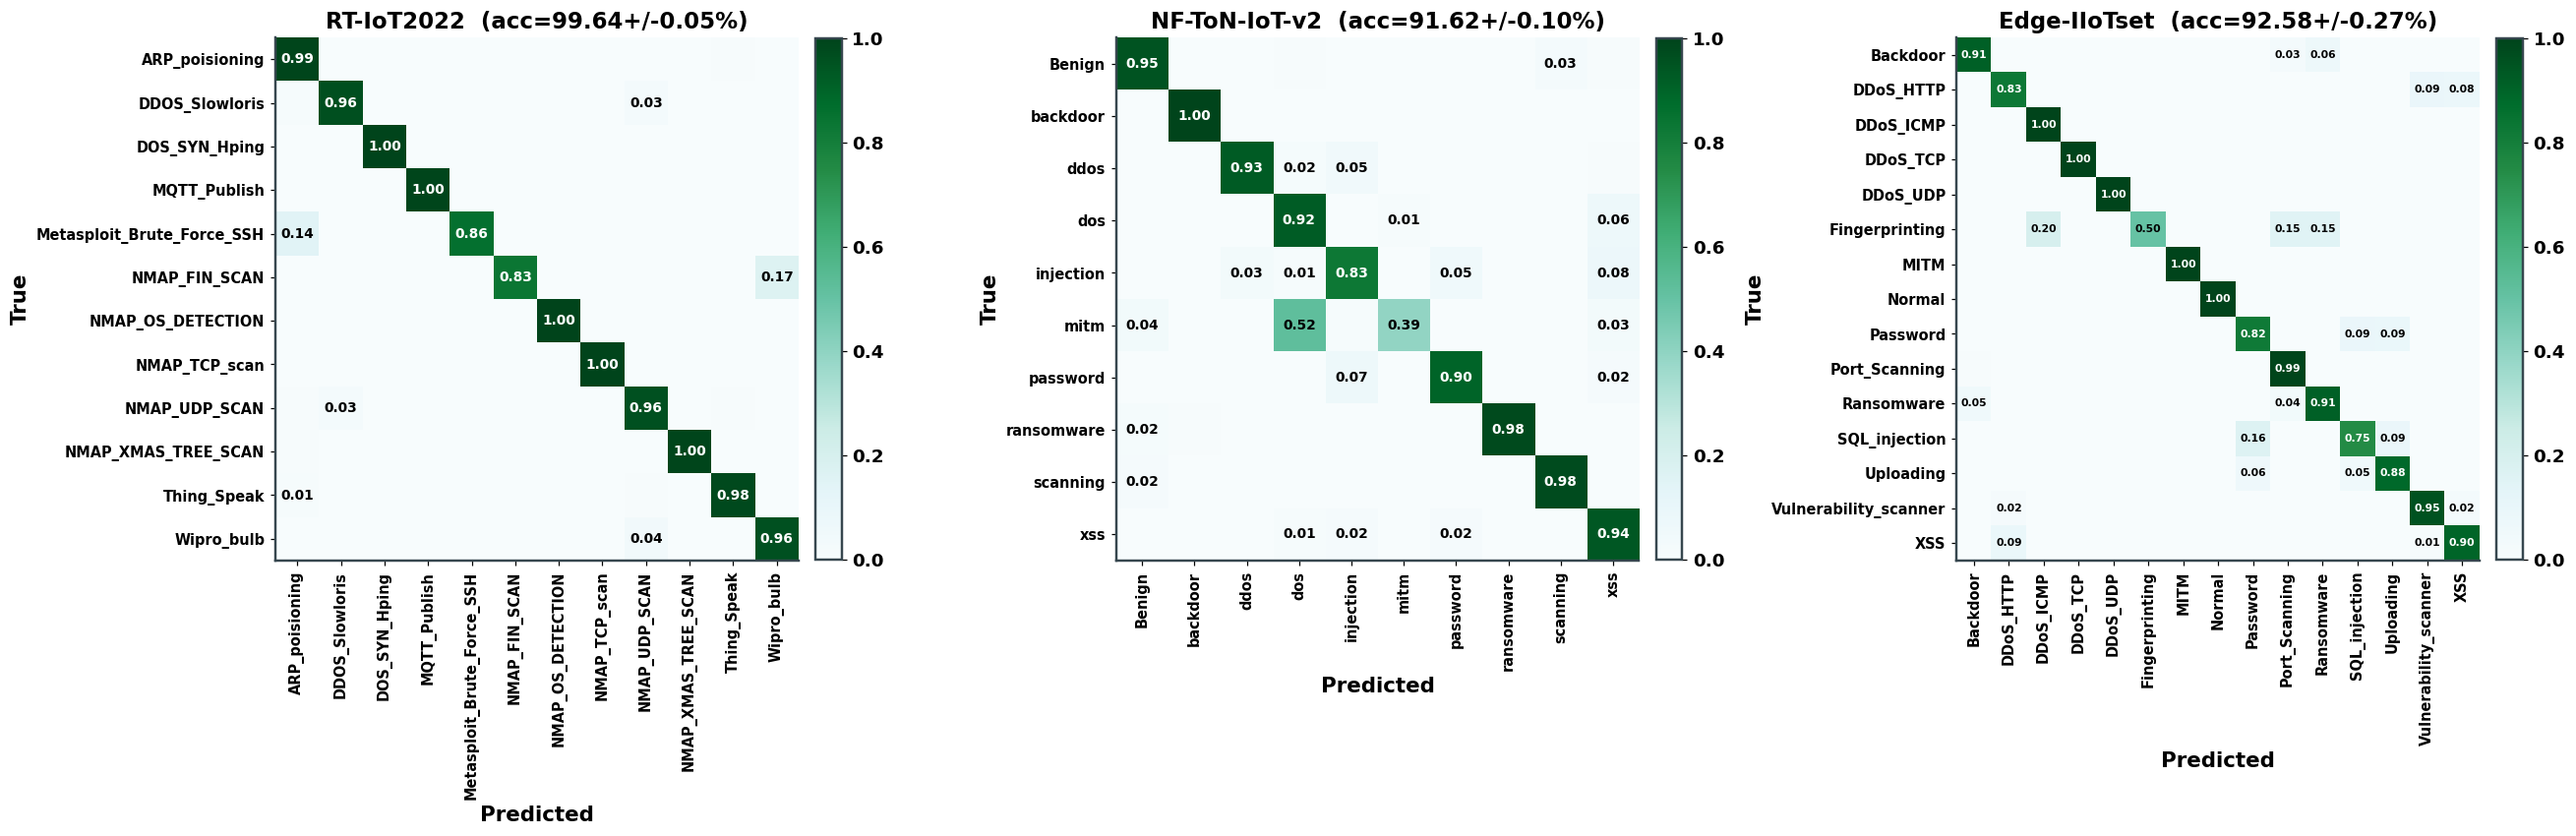

Figure 3. Row-normalized confusion matrices of the deployed EviTab-NS model (fixed reference seed; multi-seed accuracy in each title).


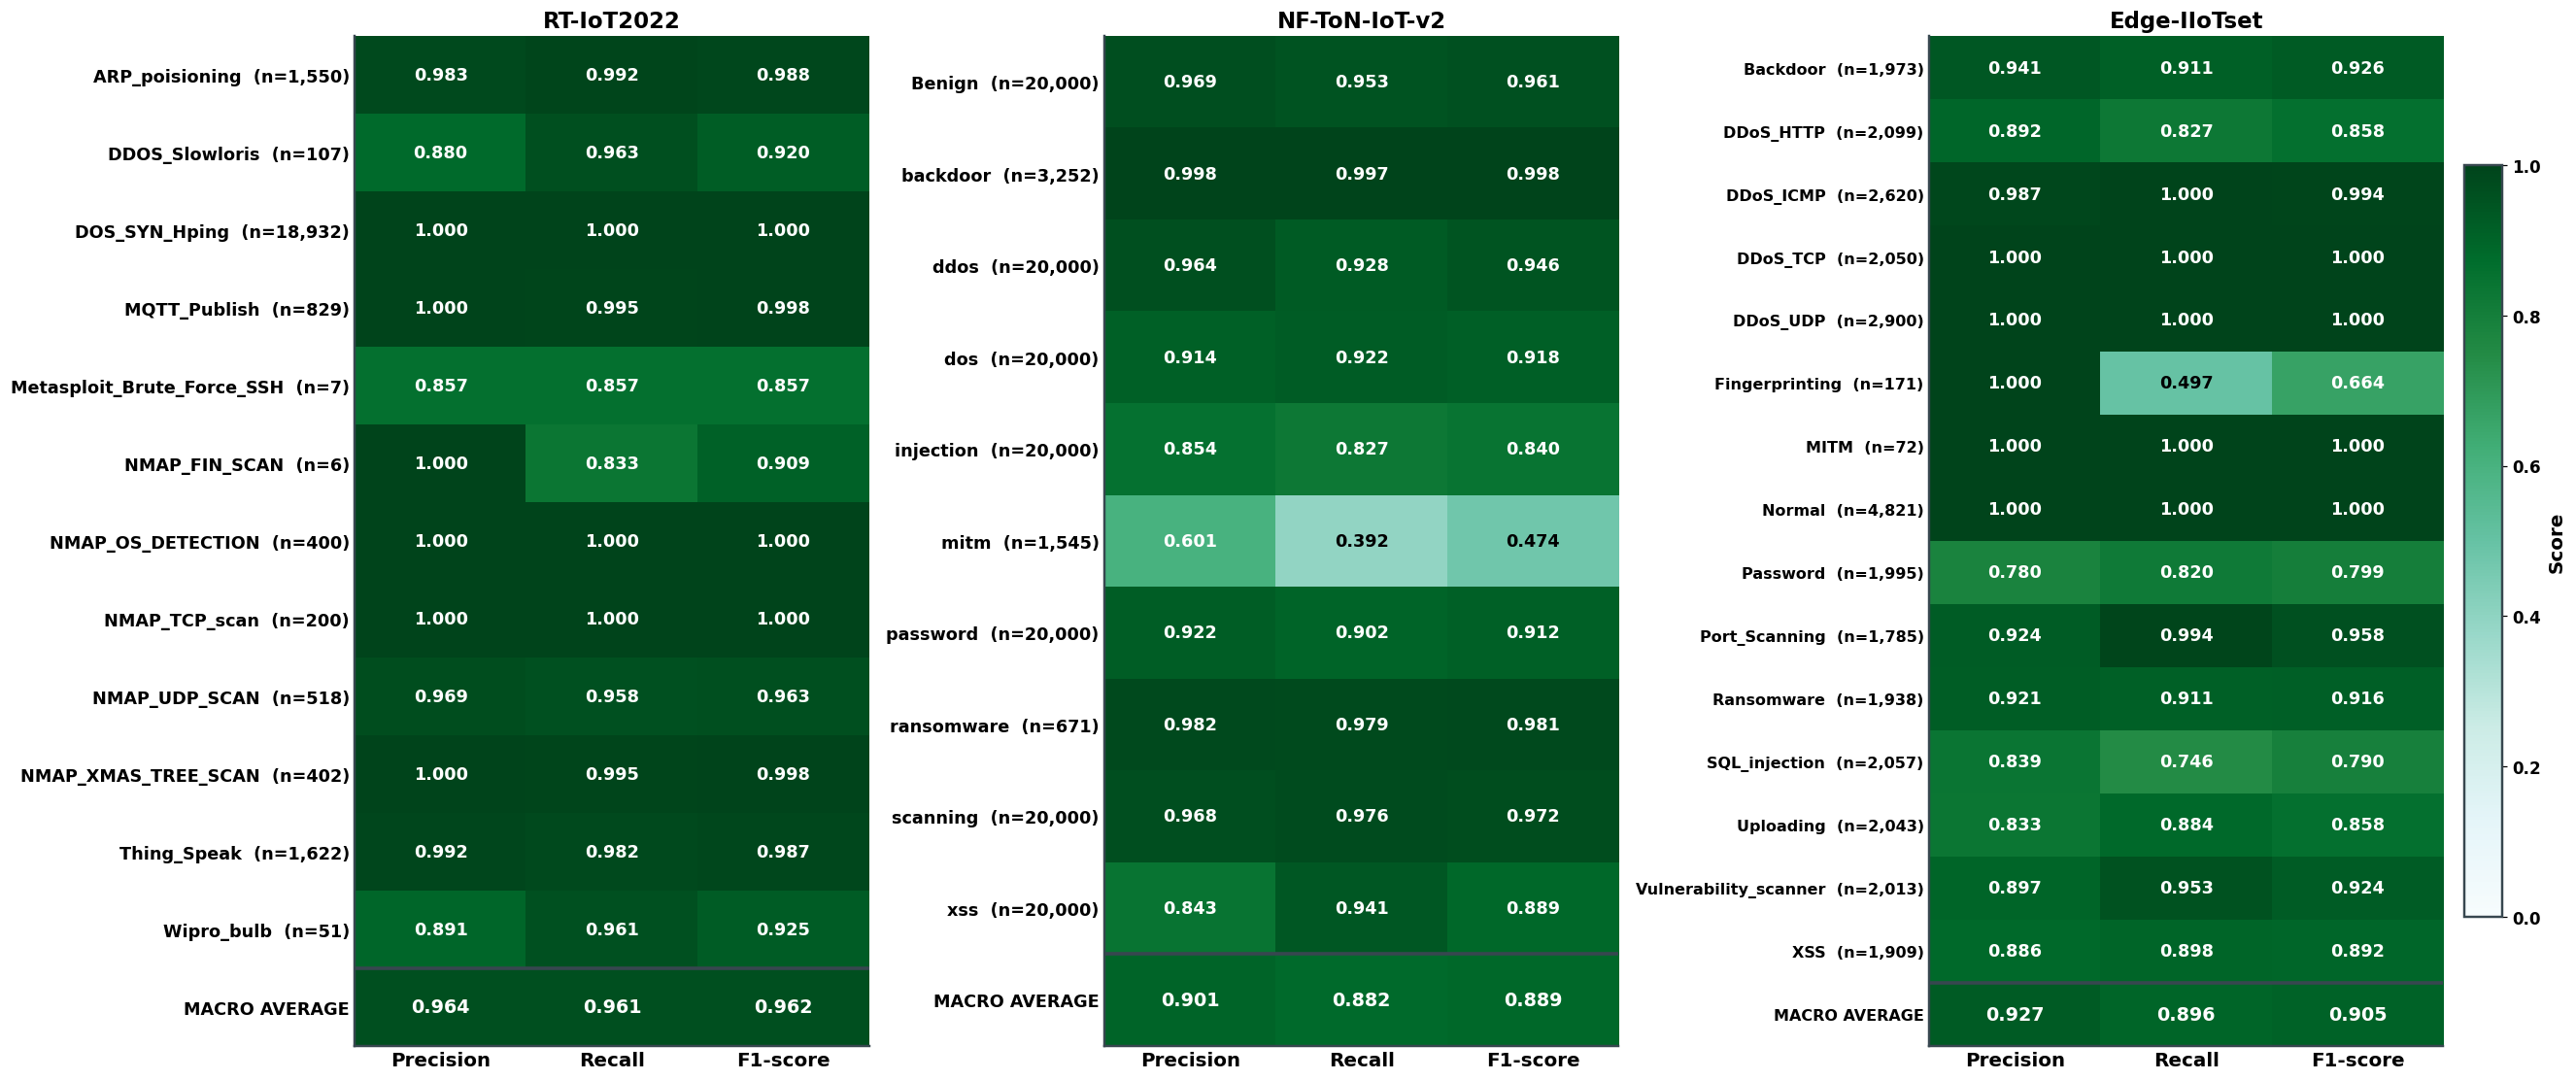

Figure 4. Per-class precision, recall and F1 of the deployed model as an annotated heatmap (fixed reference seed): one row per class with its test support (class order matches Figure 3); macro averages in the separated bottom row.
Cell 9 - Figures 3 and 4 are complete


In [11]:
# Cell 9 - Figure 3: row-normalized confusion matrices (final model, rep seed) |
#          Figure 4: per-class precision / recall / F1 HEATMAP (rep seed)
#   With up to 15 classes x 3 metrics, grouped bars become unreadable; an annotated
#   heatmap (one row per class, macro average appended) shows every value
#   cleanly in a fraction of the ink.
# --------------------------------------------------------------------------------
print('Cell 9 - Figure 3: confusion matrices | Figure 4: per-class precision/recall/F1 heatmap')

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for col, (name, d) in enumerate(DATA.items()):
    y = d["yte"]; n = len(d["classes"]); fs = 9 if n <= 12 else 7
    cm = confusion_matrix(y, RESULTS_REP[name]["Neurosymbolic"]["pred"], labels=range(n))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax = axes[col]
    ax.grid(False)
    im = ax.imshow(cmn, cmap="BuGn", vmin=0, vmax=1)
    for i in range(n):
        for j in range(n):
            if cmn[i, j] >= 0.01:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=fs,
                        fontweight="bold", color="white" if cmn[i, j] > 0.55 else "black")
    mu, sd = agg(name, "Neurosymbolic", "acc")
    ax.set_title(f"{name}  (acc={mu*100:.2f}+/-{sd*100:.2f}%)")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(d["classes"], rotation=90, fontsize=9.5, fontweight="bold")
    ax.set_yticklabels(d["classes"], fontsize=9.5, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    for t in cb.ax.get_yticklabels(): t.set_fontweight("bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_confusion_matrices.png"); plt.show()
print("Figure 3. Row-normalized confusion matrices of the deployed EviTab-NS model "
      "(fixed reference seed; multi-seed accuracy in each title).")

# Figure 4 - per-class precision / recall / F1 annotated heatmap (+ macro row)
fig, axes = plt.subplots(1, 3, figsize=(24, 10), constrained_layout=True)
for ax, (name, d) in zip(axes, DATA.items()):
    pred = RESULTS_REP[name]["Neurosymbolic"]["pred"]
    # NOTE: unpack into prefixed names - single letters like F would shadow
    # torch.nn.functional (imported as F) in the shared notebook namespace
    prec_c, rec_c, f1_c, sup_c = precision_recall_fscore_support(
        d["yte"], pred, labels=range(len(d["classes"])), zero_division=0)
    M = np.stack([prec_c, rec_c, f1_c], axis=1)   #
    M = np.vstack([M, [prec_c.mean(), rec_c.mean(), f1_c.mean()]])   # macro row
    rows = ([f"{cl}  (n={n_c:,})" for cl, n_c in zip(d["classes"], sup_c)]
            + ["MACRO AVERAGE"])
    ax.grid(False)
    im = ax.imshow(M, cmap="BuGn", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center",
                    fontsize=11.5 if i < M.shape[0] - 1 else 12.5, fontweight="bold",
                    color="white" if M[i, j] > 0.55 else "black")
    ax.axhline(M.shape[0] - 1.5, color="#37474F", linewidth=2.4)     # macro separator
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Precision", "Recall", "F1-score"], fontsize=13, fontweight="bold")
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels(rows, fontsize=10.5 if M.shape[0] > 13 else 11.5, fontweight="bold")
    ax.set_title(name)
    ax.tick_params(length=0)
cb = fig.colorbar(im, ax=axes, fraction=0.018, pad=0.01)
cb.set_label("Score", fontweight="bold", fontsize=13)
for t in cb.ax.get_yticklabels():
    t.set_fontweight("bold"); t.set_fontsize(11)
fig.savefig(FIG_DIR / "fig4_perclass_prf.png"); plt.show()
print("Figure 4. Per-class precision, recall and F1 of the deployed model as an annotated "
      "heatmap (fixed reference seed): one row per class with its test support "
      "(class order matches Figure 3); macro averages in the separated bottom row.")
print('Cell 9 - Figures 3 and 4 are complete')

Cell 10 - Figure 5: feature-usage census + evidence profile


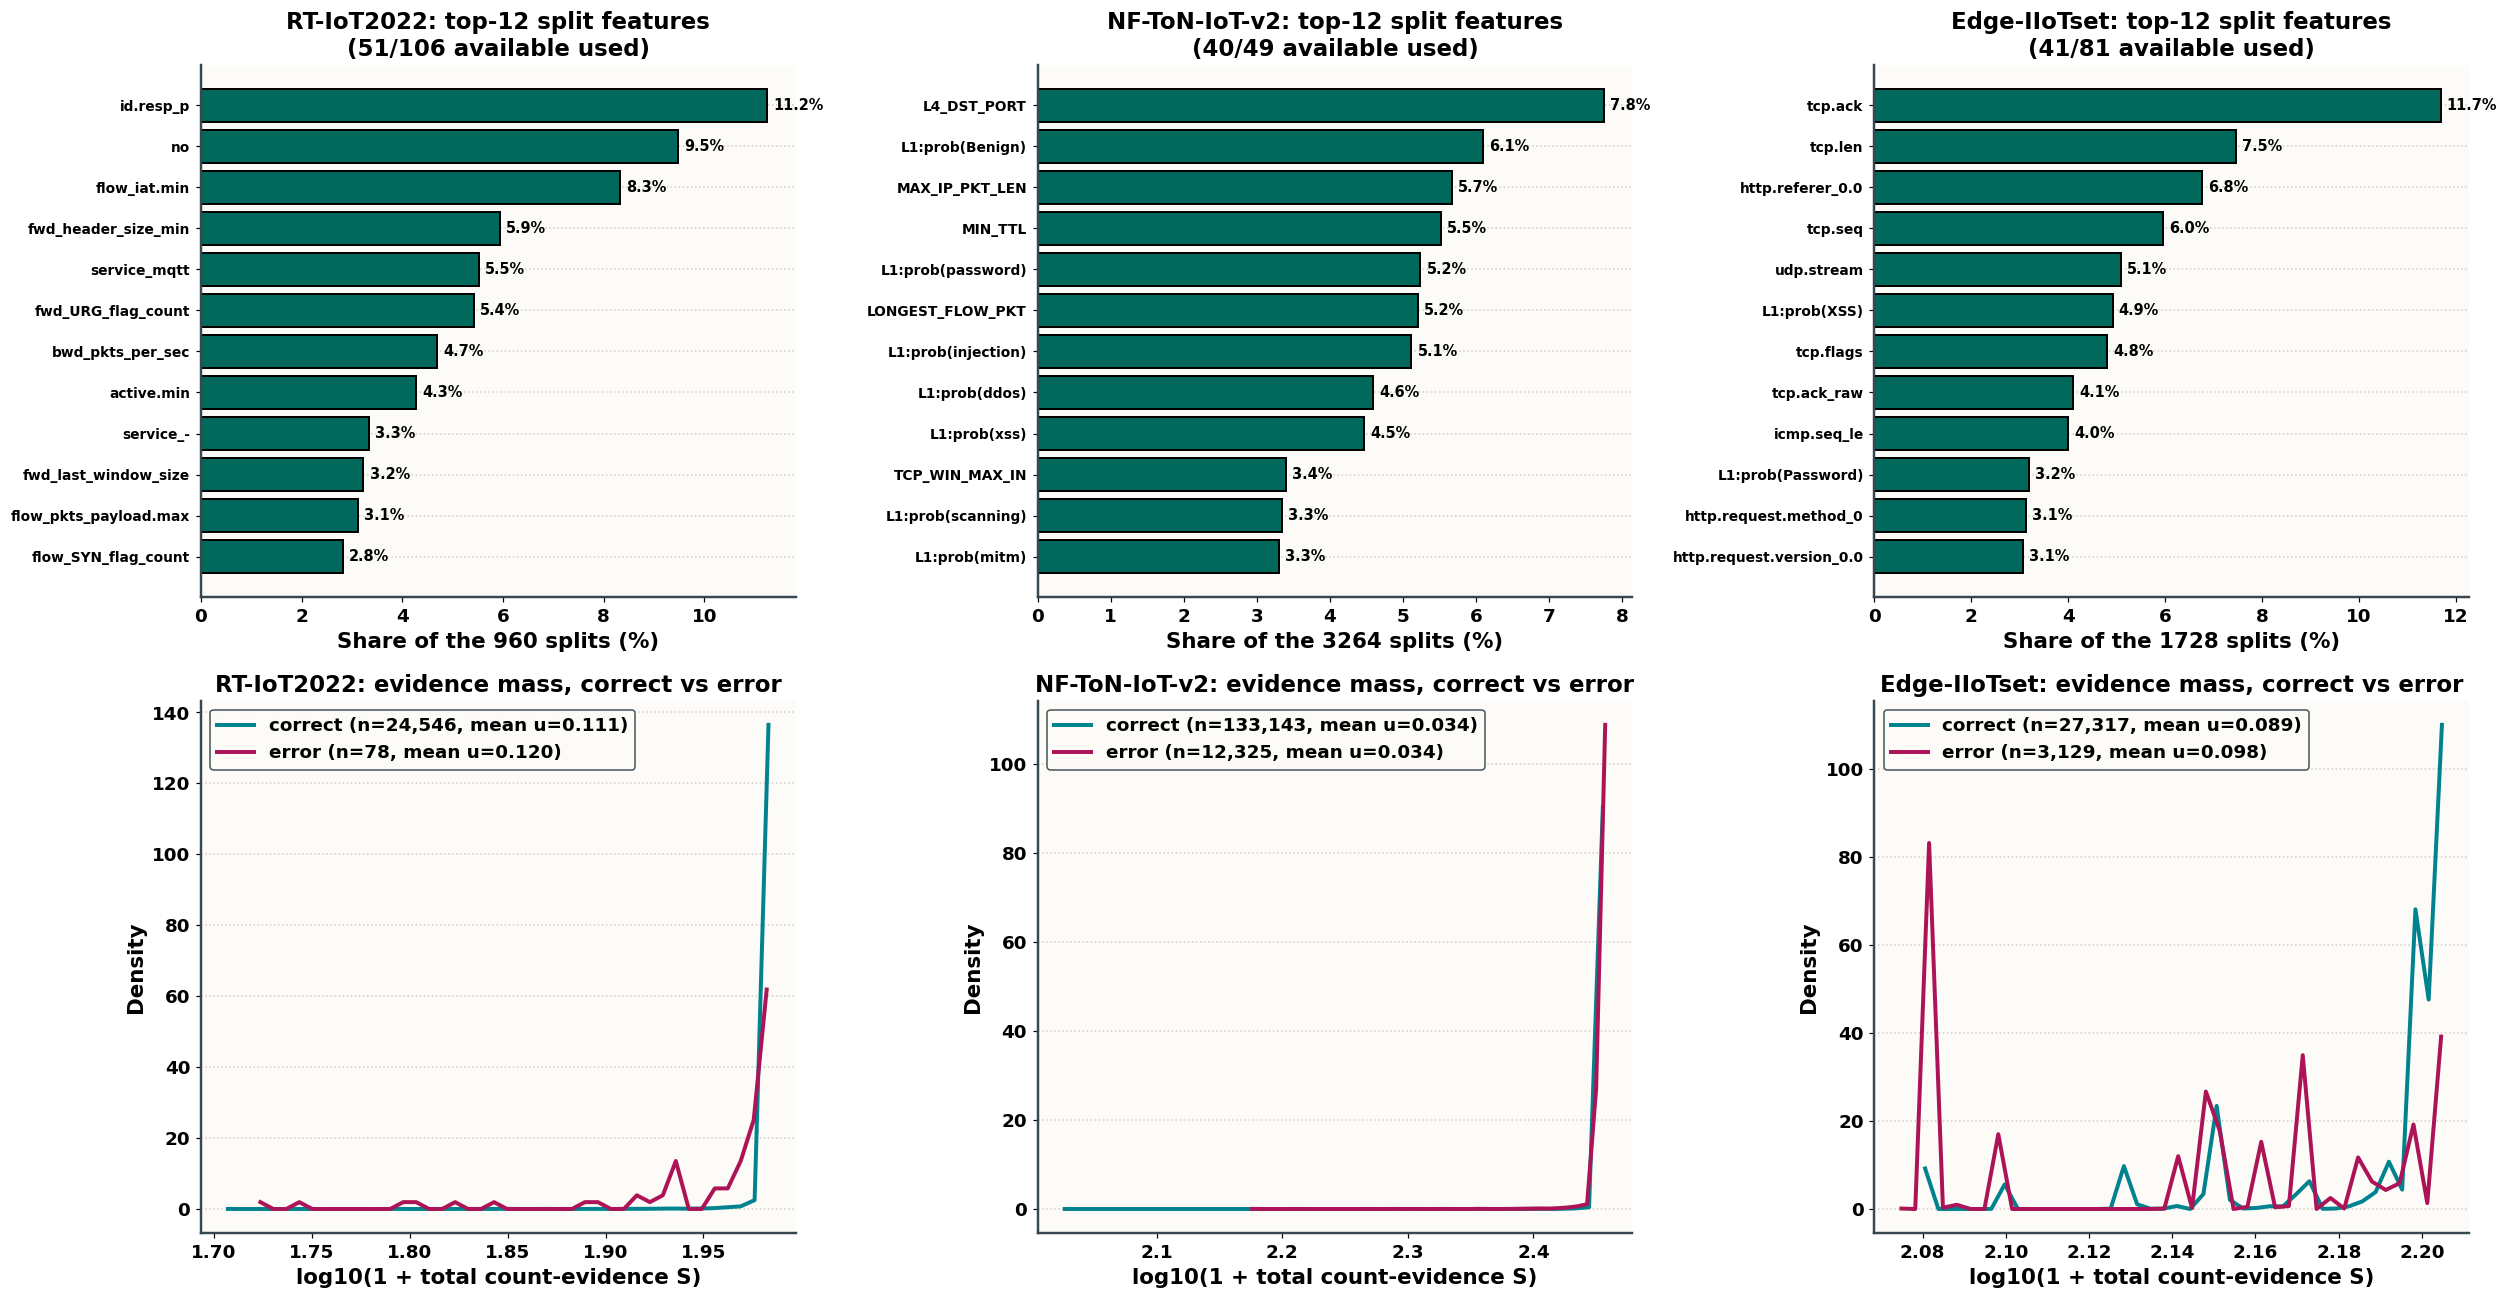

Figure 5. Top: exact census of all split features across both cascade layers (splits on previous-level beliefs appear as L1:prob(class)). Bottom: accumulated count-evidence on test flows; errors concentrate at low evidence / high vacuity - the regime where the vacuity gate admits symbolic rules (Cell 12b) and where zero-day flows land (Cell 12).
Cell 10 - Figure 5: feature-usage census + evidence profile is complete


In [12]:
# Cell 10 - Figure 5: what the decision tables test (exact feature-usage census) and
#           how much count-evidence flows accumulate (correct vs error), rep seed
#   Every split in every table names one concrete feature and threshold, so
#   "what does the detector look at" is an exact census, not a saliency estimate.
#   Layer-2 splits can also select the C layer-1 class-probability features
#   (shown as "L1:prob(<class>)") - the cascade's re-use of its own beliefs is
#   directly visible.
# --------------------------------------------------------------------------------
print('Cell 10 - Figure 5: feature-usage census + evidence profile')
TOPK = 12
fig, axes = plt.subplots(2, 3, figsize=(23, 12))
for col, (name, d) in enumerate(DATA.items()):
    model = MODELS[name]
    fnames = list(d["feat_names"])
    fnames2 = fnames + [f"L1:prob({c})" for c in d["classes"]]
    ax = axes[0, col]
    counts = np.zeros(len(fnames2))
    for lv, (tA, tB) in enumerate(model.levels):
        for tab in (tA, tB):
            ml = len(fnames) if lv == 0 else len(fnames2)
            counts[:ml] += np.bincount(tab["feat"].ravel(), minlength=ml)[:ml]
    order = np.argsort(counts)[::-1][:TOPK]
    share = counts[order] / counts.sum() * 100
    n_splits = sum(t["feat"].size for t in model.all_tabs)
    ax.barh(range(len(order)), share, color="#00695C", edgecolor="black", linewidth=1.3)
    for yi, s in enumerate(share):
        ax.annotate(f"{s:.1f}%", (s, yi), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9.5, fontweight="bold")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([fnames2[i][:34] for i in order], fontsize=9, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlabel(f"Share of the {n_splits} splits (%)")
    n_used = int((counts > 0).sum())
    ax.set_title(f"{name}: top-{TOPK} split features\n({n_used}/{len(counts)} available used)")
    bold_ticks(ax)
    axb = axes[1, col]
    ev = model.evidence(d["Xte"])                      # decisions: refined leaves
    evb = model.base_evidence(d["Xte"])                # counts: evidential channel
    S_tot = evb.sum(1); u = vacuity_np(evb)
    ok = ev.argmax(1) == d["yte"]
    for mask, colr, lab in [(ok, "#00838F", "correct"), (~ok, "#AD1457", "error")]:
        if mask.sum() < 10: continue
        hist, edges = np.histogram(np.log10(S_tot[mask] + 1), bins=40, density=True)
        axb.plot((edges[:-1] + edges[1:]) / 2, hist, color=colr, linewidth=2.6,
                 label=f"{lab} (n={mask.sum():,}, mean u={u[mask].mean():.3f})")
    axb.set_xlabel("log10(1 + total count-evidence S)"); axb.set_ylabel("Density")
    axb.set_title(f"{name}: evidence mass, correct vs error")
    axb.legend(prop={"weight": "bold"}, fontsize=9.5); bold_ticks(axb)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_feature_census_evidence.png"); plt.show()
print("Figure 5. Top: exact census of all split features across both cascade layers "
      "(splits on previous-level beliefs appear as L1:prob(class)). Bottom: "
      "accumulated count-evidence on test flows; errors concentrate at low evidence / high "
      "vacuity - the regime where the vacuity gate admits symbolic rules (Cell 12b) and where "
      "zero-day flows land (Cell 12).")
print('Cell 10 - Figure 5: feature-usage census + evidence profile is complete')

Cell 11 - Classical + deep baselines + deployment profiling (single thread)
RT-IoT2022      OURS  deployed INT8-leaf acc=99.68% (argmax agree vs FP32: 1.0000) | lat p50=0.473 ms p99=0.812 ms | throughput=95,766 flows/s | size=1158 KB classification (+novelty channel: 3596 KB) | zero mat-mul
RT-IoT2022      RandomForest  acc= 99.82%  F1m=0.9542  lat p50=  23.467 p99=  33.864 ms  size=      5009 KB  fit=  11.0s
RT-IoT2022      HistGradBoost acc= 98.90%  F1m=0.7463  lat p50=   2.529 p99=   2.923 ms  size=       566 KB  fit=   8.4s
   RT-IoT2022 TabCNN | stopped at epoch 39/40 (val-acc=0.9928, 1126s)
RT-IoT2022      TabCNN-1D     acc= 99.21%  F1m=0.9294  lat p50=   0.286 p99=   0.492 ms  size=        39 KB  fit=1126.0s
NF-ToN-IoT-v2   OURS  deployed FP32-tables acc=91.76% (argmax agree vs FP32: 1.0000) | lat p50=0.668 ms p99=1.362 ms | throughput=19,369 flows/s | size=34579 KB classification (+novelty channel: 69273 KB) | zero mat-mul
NF-ToN-IoT-v2   RandomForest  acc= 94.69%  F1m=0.9162  

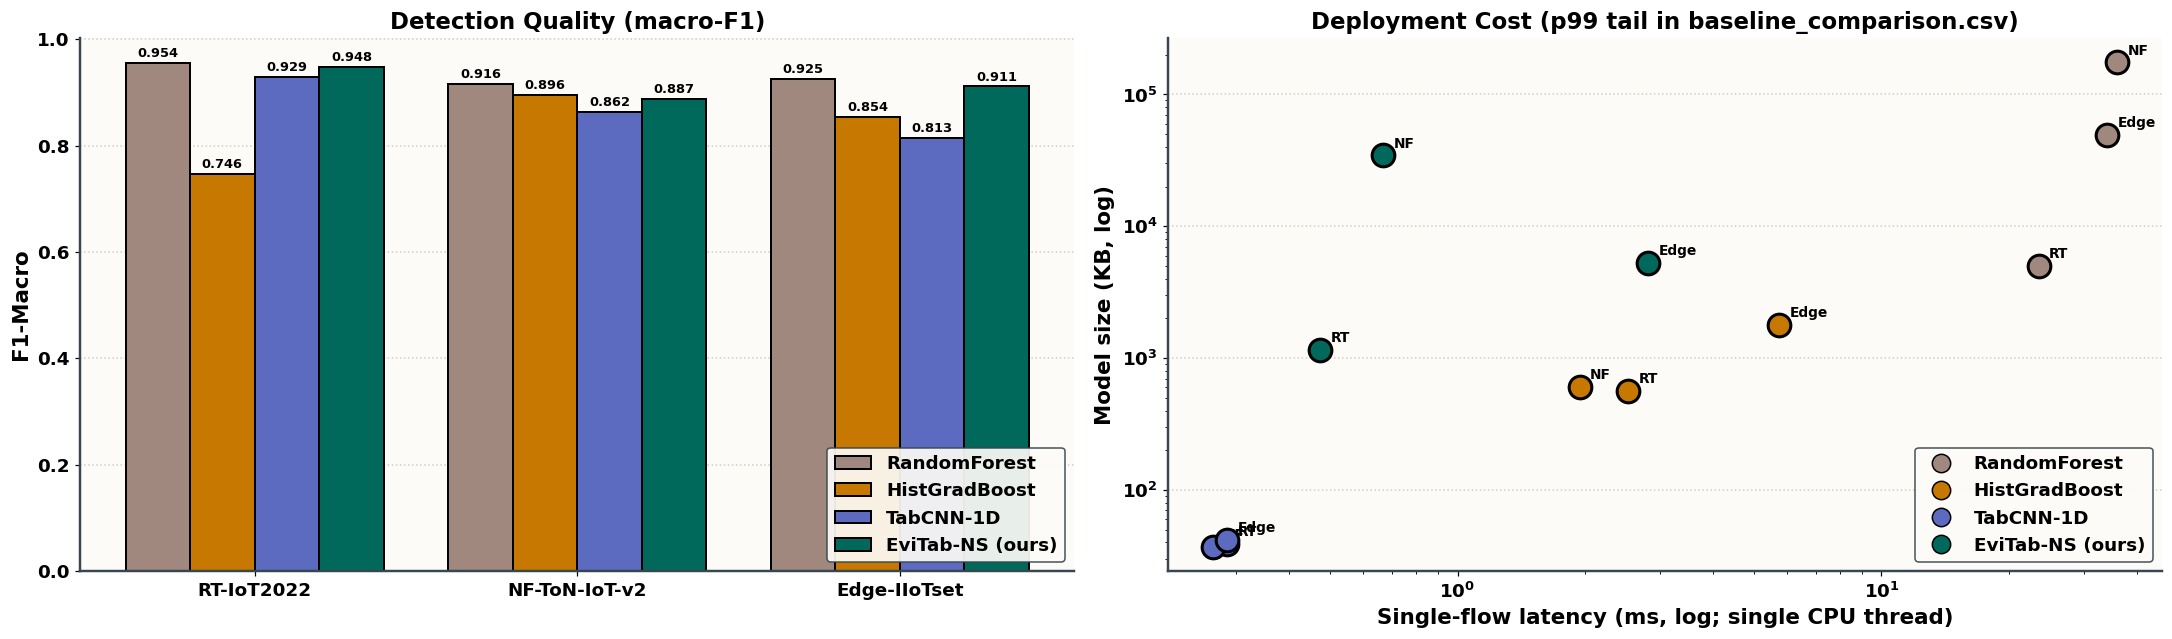

Figure 6. Detection quality (left) and deployment cost (right) on identical splits (latency: x86 CPU, single thread). EviTab-NS deploys as pure lookup tables - comparisons, lookups and sums only - with median AND p99 single-flow latency and throughput reported for delay-sensitive pipelines.
Cell 11 - Classical + deep baselines + deployment profiling is complete


In [13]:
# Cell 11 - Classical + deep baselines + DELAY-SENSITIVE deployment profiling | Figure 6
#   Identical splits; accuracy/F1 vs single-flow latency (median AND p99 tail - the
#   number that matters for delay-sensitive pipelines) vs serialized size and
#   throughput. EviTab-NS IS its deployment artifact: pure lookup tables, inference =
#   threshold comparisons + table lookups + sums, ZERO matrix multiplications and no
#   ML runtime on the device. An INT8-leaf variant (per-table symmetric quantization)
#   is kept when its VALIDATION accuracy cost is <= 1 point. Latency measured single-flow on ONE
#   cpu thread ("x86 CPU, single thread"; re-run on the edge device for board numbers).
# ---------------------------------------------------------------------------------------------
print('Cell 11 - Classical + deep baselines + deployment profiling (single thread)')
if SINGLE_THREAD_LATENCY:
    torch.set_num_threads(1)

class TabCNN(nn.Module):     # compact deep baseline: 1-D conv over the feature vector
    def __init__(self, n_in, n_out, ch=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv1d(1, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.Conv1d(ch, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.ReLU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(),
            nn.Linear(ch * 8, n_out))
    def forward(self, x): return self.body(x.unsqueeze(1))

def train_tabcnn(d, name, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    Xtr, Xva, ytr, yva = train_test_split(d["Xtr"], d["ytr"], test_size=0.1,
                                          stratify=d["ytr"], random_state=seed)
    n_out = len(d["classes"])
    model = TabCNN(Xtr.shape[1], n_out).to(DEVICE)
    w = np.clip(len(ytr) / (n_out * np.bincount(ytr, minlength=n_out) + 1e-9), .2, 20)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR_BASELINE, weight_decay=1e-4)
    Xt, yt = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    Xv, yv = torch.tensor(Xva, device=DEVICE), torch.tensor(yva, device=DEVICE)
    best, wait, best_state, t0 = 0, 0, None, time.time()
    for ep in range(EPOCHS_BASELINE):
        model.train(); perm = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i+BATCH_SIZE]
            if len(idx) < 2: continue
            opt.zero_grad(); crit(model(Xt[idx]), yt[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va, nb = 0.0, 0
            for i in range(0, len(Xv), 65536):
                pr = model(Xv[i:i+65536]).argmax(1)
                va += (pr == yv[i:i+65536]).sum().item(); nb += len(pr)
        va /= nb
        if va > best:
            best, wait = va, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if ep + 1 >= MIN_EPOCHS and wait >= PATIENCE: break
    model.load_state_dict(best_state)
    print(f"   {name} TabCNN | stopped at epoch {ep+1}/{EPOCHS_BASELINE} "
          f"(val-acc={best:.4f}, {time.time()-t0:.0f}s)", flush=True)
    return model, time.time() - t0

def lat_stats(fn, r=300):
    for _ in range(20): fn()
    ts = []
    for _ in range(r):
        t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1e3)
    ts = np.array(ts)
    return float(np.median(ts)), float(np.percentile(ts, 99))

def profile_ours(name, model, d):
    xt = d["Xte"]
    ev_ref = model.predict_proba(xt[:2000])
    acc_fp32 = accuracy_score(d["yte"], model.predict_proba(xt).argmax(1))
    # INT8-leaf variant across all discriminative tables
    import copy
    m8 = copy.copy(model)
    m8.levels = [(quantize_leaves_int8(tA), quantize_leaves_int8(tB))
                 for tA, tB in model.levels]
    acc_int8 = accuracy_score(d["yte"], m8.predict_proba(xt).argmax(1))
    # the <=1 point INT8 guard is judged on the validation split, never on test
    _, Xva, _, yva = split_train_val(d, name, REP_SEED)
    va_fp32 = accuracy_score(yva, model.predict_proba(Xva).argmax(1))
    va_int8 = accuracy_score(yva, m8.predict_proba(Xva).argmax(1))
    x1 = xt[:1]
    lat_f, p99_f = lat_stats(lambda: model.predict_proba(x1))
    lat_q, p99_q = lat_stats(lambda: m8.predict_proba(x1))
    # batch throughput (flows/s) at batch 4096
    xb = xt[:4096] if len(xt) >= 4096 else xt
    tb = lat_stats(lambda: model.predict_proba(xb), r=30)[0] / 1e3
    thru = len(xb) / tb
    cands = [("FP32-tables", acc_fp32, lat_f, p99_f,
              model_size_kb(model, int8=False, with_novelty=False), model)]
    if (va_fp32 - va_int8) <= 0.01:
        cands.append(("INT8-leaf", acc_int8, lat_q, p99_q,
                      model_size_kb(model, int8=True, with_novelty=False), m8))
    # deployment preference: SMALLEST accuracy-safe artifact (resource-constrained
    # first); latency differences between candidates are microseconds either way
    variant, acc_dep, lat, p99, size_kb, dep = min(cands, key=lambda c: c[4])
    # consistency check: deployed variant vs reference evidence on 2000 flows
    agree = float((dep.predict_proba(xt[:2000]).argmax(1) == ev_ref.argmax(1)).mean())
    return dict(acc_fp32=acc_fp32, acc_int8=acc_int8, va_fp32=va_fp32, va_int8=va_int8,
                variant=variant, agree=agree,
                lat=lat, p99=p99, lat_fp32=lat_f, lat_int8=lat_q, thru=thru,
                size_kb=size_kb,
                size_full=model_size_kb(model, int8=(variant == "INT8-leaf"), with_novelty=True),
                size_int8=model_size_kb(model, int8=True, with_novelty=False), deployed=dep)

BASELINES = {
 "RandomForest":   lambda seed: RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                                       n_jobs=-1, random_state=seed),
 "HistGradBoost":  lambda seed: HistGradientBoostingClassifier(random_state=seed),
}
PROF, BASE_RES = {}, []
for name, d in DATA.items():
    PROF[name] = p = profile_ours(name, MODELS[name], d)
    print(f"{name:15s} OURS  deployed {p['variant']} acc={(p['acc_int8'] if p['variant']=='INT8-leaf' else p['acc_fp32'])*100:.2f}% "
          f"(argmax agree vs FP32: {p['agree']:.4f}) | lat p50={p['lat']:.3f} ms p99={p['p99']:.3f} ms | "
          f"throughput={p['thru']:,.0f} flows/s | size={p['size_kb']:.0f} KB classification "
          f"(+novelty channel: {p['size_full']:.0f} KB) | zero mat-mul", flush=True)
    for bname, ctor in BASELINES.items():
        t0 = time.time(); clf = ctor(REP_SEED).fit(d["Xtr"], d["ytr"]); t_fit = time.time() - t0
        pred = clf.predict(d["Xte"])
        x1 = d["Xte"][:1]
        lat, p99 = lat_stats(lambda: clf.predict(x1), 50)
        size_kb = len(pickle.dumps(clf)) / 1024
        row = dict(Dataset=name, Model=bname, acc=accuracy_score(d["yte"], pred),
                   f1_m=f1_score(d["yte"], pred, average="macro", zero_division=0),
                   lat_ms=lat, p99_ms=p99, size_kb=size_kb, fit_s=t_fit)
        BASE_RES.append(row)
        print(f"{name:15s} {bname:13s} acc={row['acc']*100:6.2f}%  F1m={row['f1_m']:.4f}  "
              f"lat p50={lat:8.3f} p99={p99:8.3f} ms  size={size_kb:10.0f} KB  fit={t_fit:6.1f}s", flush=True)
    cnn, t_fit = train_tabcnn(d, name, REP_SEED)
    cnn_cpu = TabCNN(d["Xte"].shape[1], len(d["classes"]))
    cnn_cpu.load_state_dict({k: v.cpu() for k, v in cnn.state_dict().items()}); cnn_cpu.eval()
    xt = torch.tensor(d["Xte"])
    with torch.no_grad():
        preds = []
        for i in range(0, len(xt), 65536):
            preds.append(cnn_cpu(xt[i:i+65536]).argmax(1).numpy())
    pred = np.concatenate(preds)
    buf = io.BytesIO(); torch.save(cnn_cpu.state_dict(), buf)
    x1t = xt[:1]
    def _run1():
        with torch.no_grad(): cnn_cpu(x1t)
    lat, p99 = lat_stats(_run1, 200)
    row = dict(Dataset=name, Model="TabCNN-1D", acc=accuracy_score(d["yte"], pred),
               f1_m=f1_score(d["yte"], pred, average="macro", zero_division=0),
               lat_ms=lat, p99_ms=p99, size_kb=buf.getbuffer().nbytes / 1024, fit_s=t_fit)
    BASE_RES.append(row)
    print(f"{name:15s} {'TabCNN-1D':13s} acc={row['acc']*100:6.2f}%  F1m={row['f1_m']:.4f}  "
          f"lat p50={lat:8.3f} p99={p99:8.3f} ms  size={row['size_kb']:10.0f} KB  fit={t_fit:6.1f}s", flush=True)
    del cnn
    mu_a, _ = agg(name, "Neurosymbolic", "acc"); mu_f, _ = agg(name, "Neurosymbolic", "f1_m")
    tt = np.array([r["train_s"] for r in EXP[name]])
    BASE_RES.append(dict(Dataset=name, Model="EviTab-NS (ours)", acc=mu_a, f1_m=mu_f,
                         lat_ms=p["lat"], p99_ms=p["p99"], size_kb=p["size_kb"], fit_s=tt.mean()))
BASE_DF = pd.DataFrame(BASE_RES)
BASE_DF.to_csv("baseline_comparison.csv", index=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(20, 6))
mcolor = {"RandomForest": "#A1887F", "HistGradBoost": "#C77800",
          "TabCNN-1D": "#5C6BC0", "EviTab-NS (ours)": "#00695C"}
xx = np.arange(len(DATA)); wdt = 0.20
for k, mdl in enumerate(mcolor):
    v = [BASE_DF[(BASE_DF.Dataset == n) & (BASE_DF.Model == mdl)].f1_m.iloc[0] for n in DATA]
    b = a1.bar(xx + (k - 1.5) * wdt, v, wdt, label=mdl, color=mcolor[mdl],
               edgecolor="black", linewidth=1.3)
    a1.bar_label(b, fmt="%.3f", fontweight="bold", fontsize=8.5, padding=2)
a1.set_xticks(xx); a1.set_xticklabels(DATA.keys(), fontweight="bold")
a1.set_ylabel("F1-Macro"); a1.set_title("Detection Quality (macro-F1)")
a1.legend(prop={"weight": "bold"}, loc="lower right"); bold_ticks(a1)
for _, r in BASE_DF.iterrows():
    a2.scatter(r.lat_ms, r.size_kb, s=220, color=mcolor[r.Model],
               edgecolor="black", linewidth=2, zorder=3)
    a2.annotate(r.Dataset.split("-")[0], (r.lat_ms, r.size_kb), xytext=(7, 5),
                textcoords="offset points", fontsize=9, fontweight="bold")
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel("Single-flow latency (ms, log; single CPU thread)"); a2.set_ylabel("Model size (KB, log)")
a2.set_title("Deployment Cost (p99 tail in baseline_comparison.csv)")
handles = [plt.Line2D([0], [0], marker="o", linestyle="", markersize=12, color=c,
                      markeredgecolor="black", label=m) for m, c in mcolor.items()]
a2.legend(handles=handles, prop={"weight": "bold"}); bold_ticks(a2)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig6_baseline_comparison.png"); plt.show()
print("Figure 6. Detection quality (left) and deployment cost (right) on identical splits "
      "(latency: x86 CPU, single thread). EviTab-NS deploys as pure lookup tables - "
      "comparisons, lookups and sums only - with median AND p99 single-flow latency and "
      "throughput reported for delay-sensitive pipelines.")
print('Cell 11 - Classical + deep baselines + deployment profiling is complete')

Cell 12a - Zero-day (open-set) experiment: native novelty + negative controls + OOD baselines
   [RT-IoT2022/NMAP_TCP_scan] holdout rule rates: flood_rate>p99.5(benign)=1.000; SYN&slow_rate (probe)=0.000; dst_port in {22,23}=0.002 | weighted=0.5002 -> rule-covered (measured)
RT-IoT2022      holdout=NMAP_TCP_scan   [rule-covered (measured)] seed=42 fit=594s lamN=2.0 lamM=2.0 v=[flood_rate>p99.5(benign)=+0.997; SYN&slow_rate (probe)=+0.000; dst_port in {22,23}=+1.000]
    MSP: AUROC=0.9440 R@95TNR=0.6906 | Mahalanobis: AUROC=0.9840 R@95TNR=1.0000 | Native novelty (ours): AUROC=0.9777 R@95TNR=1.0000 | Native novelty + symbolic evid.: AUROC=0.9845 R@95TNR=1.0000
   [RT-IoT2022/NMAP_TCP_scan] holdout rule rates: flood_rate>p99.5(benign)=1.000; SYN&slow_rate (probe)=0.000; dst_port in {22,23}=0.002 | weighted=0.5003 -> rule-covered (measured)
RT-IoT2022      holdout=NMAP_TCP_scan   [rule-covered (measured)] seed=43 fit=557s lamN=2.0 lamM=2.0 v=[flood_rate>p99.5(benign)=+0.997; SYN&slow_rate 

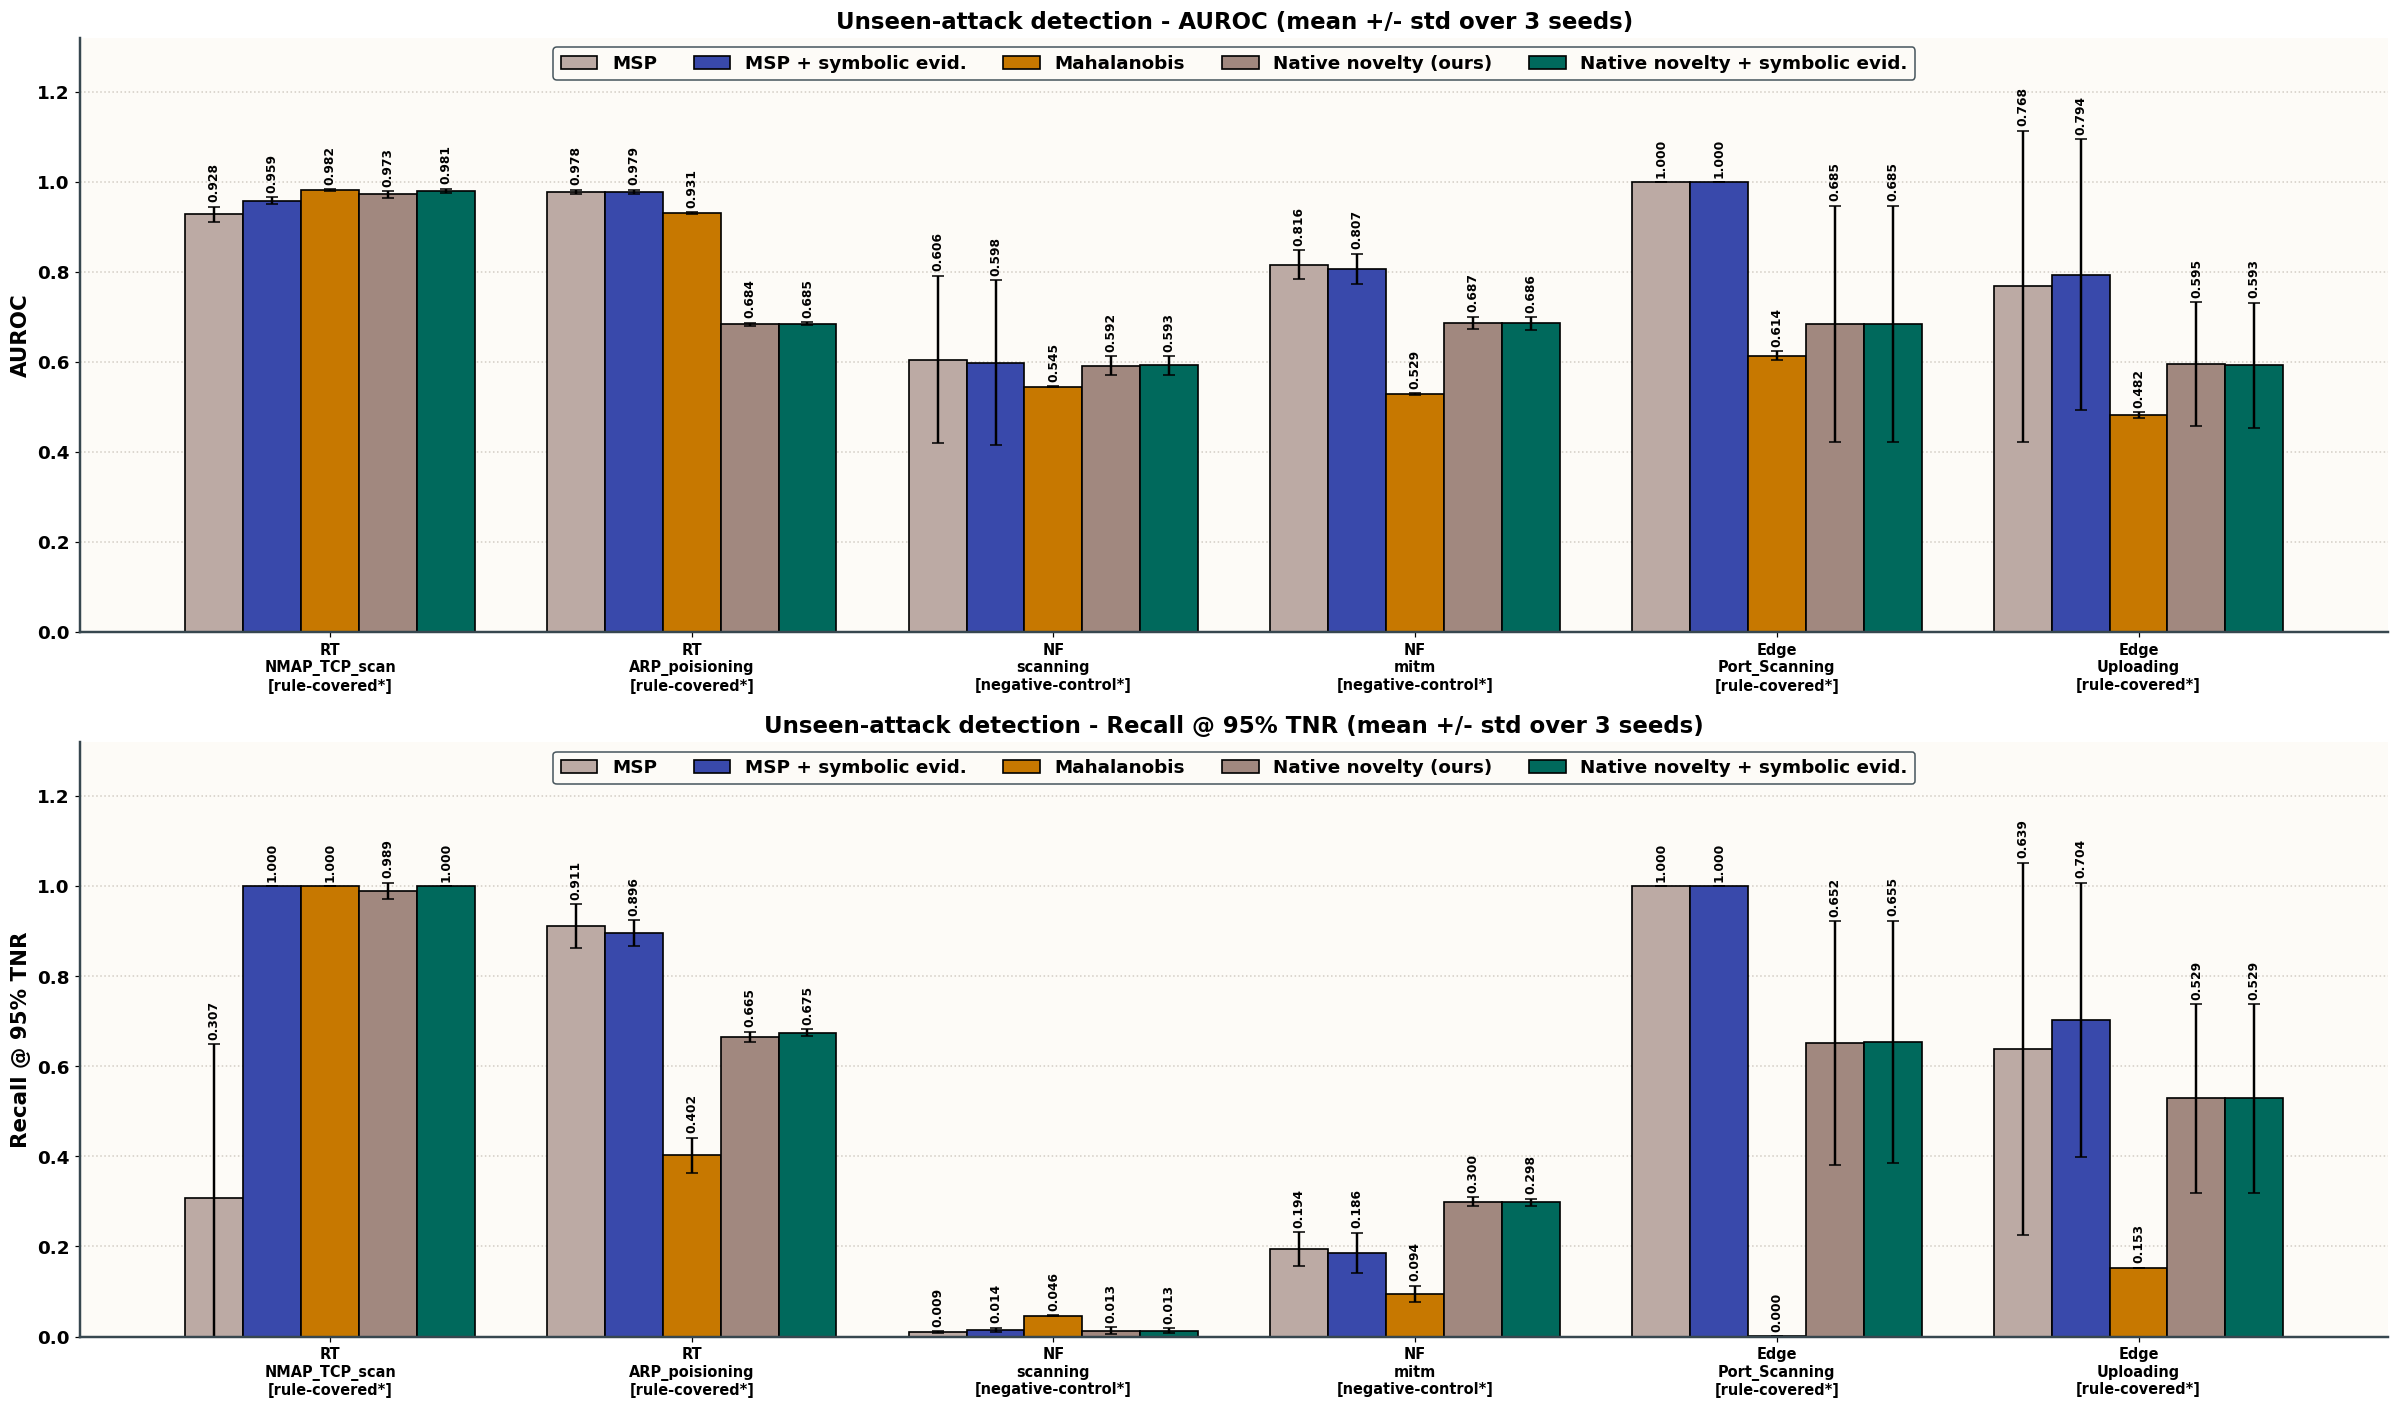

Figure 7. Zero-day detection of withheld attack families (*case designations are MEASURED from weighted rule activation on the holdout, not assumed a priori; the a-priori labels are kept in zero_day_results.csv): the native count-backed novelty score (vacuity + coverage rarity, both living inside the deployed tables; no auxiliary density model) with benign-rarity symbolic evidence as an additive channel, vs MSP(+sym) and Mahalanobis under identical models and splits (bars = mean over seeds; per-seed values and the ODIN / Dissonance / single-channel scores in zero_day_results.csv).
Cell 12a - Zero-day (open-set) experiment is complete


In [15]:
# Cell 12a - Zero-day (open-set) experiment: NATIVE count-backed novelty, negative
#           controls, and OOD baselines | Figure 7
#   EviTab-NS's novelty signal is FREE and COUNT-BACKED, with two complementary
#   channels that ship inside the same lookup tables:
#     * VACUITY u = C/(C + S): S is literally (smoothed) training-flow support for
#       the visited leaves - low support or impure leaves => high vacuity. The SAME
#       quantity gates the symbolic channel (one mechanism, two jobs).
#     * COVERAGE RARITY: mean -log occupancy over random-split coverage tables - an
#       unsupervised density channel whose splits do NOT depend on class labels, so
#       it can react along features the discriminative tables never test.
#     * Native novelty (ours) = z(vacuity) + z(rarity), z-scored on validation benign.
#   Symbolic evidence = PRIOR KNOWLEDGE, deliberately NOT calibrated on known
#   attacks: rule weight v_r = (1 - p_benign_r) if p_benign_r <= 10%, else 0; the
#   bounded term s(x) = (A(x) @ v)/sum(v) in [0,1] is an ADDITIVE channel on any
#   base score; lambda per base is DOUBLE-GUARDED do-no-harm calibrated (validation
#   AUROC AND validation recall at the 95%-TNR operating point must not degrade).
#   Case designations are MEASURED: each holdout is labeled rule-covered or
#   negative-control by its weighted rule activation (threshold 5%), with the
#   a-priori designation kept for reference. Thresholds (R@95TNR) come from
#   VALIDATION benign scores; realized test TNR is recorded as a sanity check.
#   Scope note (disclosed limitation): all partition-based scores extrapolate
#   constantly beyond the outermost thresholds; the input-space Mahalanobis
#   baseline covers that far-OOD regime and is reported side-by-side.
# --------------------------------------------------------------------------------
print('Cell 12a - Zero-day (open-set) experiment: native novelty + negative controls + OOD baselines')
import torch.nn.functional as F      # defensive re-import: heals the namespace if an
#                                      earlier cell ever rebinds the name F
HOLDOUTS = {"RT-IoT2022":   [("NMAP_TCP_scan", "rule-covered"), ("ARP_poisioning", "negative-control")],
            "NF-ToN-IoT-v2":[("scanning",      "rule-covered"), ("mitm",           "negative-control")],
            "Edge-IIoTset": [("Port_Scanning", "rule-covered"), ("Uploading",      "negative-control")]}
HOLDOUTS_ALT = {"RT-IoT2022":    ["Metasploit_Brute_Force_SSH", "DDOS_Slowloris"],
                "NF-ToN-IoT-v2": ["injection", "ransomware", "backdoor", "password"],
                "Edge-IIoTset":  ["SQL_injection", "XSS", "Ransomware", "MITM"]}
LAMBDA_GRID  = [0.0, 0.5, 1.0, 2.0]
LAM_TOL      = 0.002
BEN_RATE_MAX = 0.10
MAHA_FIT_MAX = 100_000

def fit_mahalanobis(feats, y, n_classes):
    mu_all = feats.mean(0)
    means = np.stack([feats[y == c].mean(0) if (y == c).any() else mu_all
                      for c in range(n_classes)])
    Xc = feats - means[y]
    cov = Xc.T @ Xc / len(Xc) + 1e-6 * np.eye(feats.shape[1])
    return means, np.linalg.inv(cov)

def maha_score(feats, means, prec, bs=20_000):
    out = np.empty(len(feats))
    for i in range(0, len(feats), bs):
        f = feats[i:i+bs]
        d = np.stack([np.einsum('ij,jk,ik->i', f - mu, prec, f - mu) for mu in means])
        out[i:i+bs] = d.min(0)
    return out

def _std(x, mu, sd): return (x - mu) / sd

def pick_lam(zb_v, s_v, ben_v):
    y_att = ~ben_v
    base_auc = roc_auc_score(y_att, zb_v)
    base_rec = (zb_v[y_att] > np.percentile(zb_v[ben_v], 95)).mean()
    ok = [0.0]
    for L in LAMBDA_GRID[1:]:
        sc  = zb_v + L * s_v
        rec = (sc[y_att] > np.percentile(sc[ben_v], 95)).mean()
        if (roc_auc_score(y_att, sc) >= base_auc - LAM_TOL
                and rec >= base_rec - LAM_TOL):
            ok.append(L)
    return max(ok)

ZD = []
for name, df in DATASETS.items():
    present = set(df[LABEL_COL[name]].astype(str))
    for hold, kind in HOLDOUTS[name]:
        if hold not in present:
            print(f"{name}: holdout class '{hold}' not found - skipping "
                  f"(alternates: {HOLDOUTS_ALT.get(name, [])})"); continue
        for seed in ZD_SEEDS:
            zd_tag = f"zd_{name}_{hold}_{seed}"
            ck = ckpt_load(zd_tag)
            if ck is not None:
                ZD.append(ck)
                print(f"{name:15s} holdout={hold:15s} seed={seed} loaded from checkpoint (no refit)")
                continue
            d = preprocess_openset(df, LABEL_COL[name], DROP_COLS[name], seed, hold)
            t0 = time.time()
            model = EviTabCascade(len(d["classes"])).fit(d["Xtr"], d["ytr"], seed)
            eng = SymbolicRuleEngine(name, d["raw_train"], LABEL_COL[name])
            groups = np.array([class_to_group(c) for c in d["classes"]])

            n = len(d["ytr"]); m = min(n, 20_000, max(2_000, n // 10))
            sel = np.random.RandomState(seed + 1).choice(n, size=m, replace=False)
            ev_v  = model.evidence(d["Xtr"][sel])
            A_v   = eng.activations(d["raw_train"].iloc[sel])
            ben_v = groups[d["ytr"][sel]] == "BENIGN"
            if ben_v.sum() < 50 or (~ben_v).sum() < 50:
                print(f"   {name}/{hold} seed={seed}: sparse val classes - skipping"); continue

            p_b = A_v[ben_v].mean(0)
            v   = np.where(p_b <= BEN_RATE_MAX, 1.0 - p_b, 0.0)
            vs  = max(v.sum(), 1e-9)
            s_v = (A_v @ v) / vs

            evb_v  = model.base_evidence(d["Xtr"][sel])   # COUNT evidence (evidential channel)
            lg_v   = np.log(ev_v + 1.0)
            vac_v  = vacuity_np(evb_v)
            rar_v  = coverage_rarity(d["Xtr"][sel], model.cov)
            dis_v  = dissonance_np(evb_v)
            msp_v  = 1.0 - softmax_np(lg_v).max(1)
            odin_v = 1.0 - softmax_np(lg_v / 1000.0).max(1)
            fit_i = np.random.RandomState(seed + 2).choice(
                        len(d["Xtr"]), min(len(d["Xtr"]), MAHA_FIT_MAX), replace=False)
            means, prec = fit_mahalanobis(d["Xtr"][fit_i].astype(np.float64),
                                          d["ytr"][fit_i], len(d["classes"]))
            mah_v = maha_score(d["Xtr"][sel].astype(np.float64), means, prec)
            cal = {}
            for bn, bv in [("Vac", vac_v), ("Rar", rar_v), ("Diss", dis_v),
                           ("MSP", msp_v), ("ODIN", odin_v), ("Maha", mah_v)]:
                cal[bn] = (bv[ben_v].mean(), bv[ben_v].std() + 1e-9)
            nov_v = _std(vac_v, *cal["Vac"]) + _std(rar_v, *cal["Rar"])
            cal["Nov"] = (nov_v[ben_v].mean(), nov_v[ben_v].std() + 1e-9)
            zn_v, zm_v = _std(nov_v, *cal["Nov"]), _std(msp_v, *cal["MSP"])
            lam_n = pick_lam(zn_v, s_v, ben_v)
            lam_m = pick_lam(zm_v, s_v, ben_v)

            ev_te, ev_h = model.evidence(d["Xte"]), model.evidence(d["Xhold"])
            evb_te, evb_h = model.base_evidence(d["Xte"]), model.base_evidence(d["Xhold"])
            ben_te = groups[d["yte"]] == "BENIGN"
            if ben_te.sum() < 50:
                print(f"{name}/{hold}: too few benign test flows - skipping"); break
            A_te, A_h = eng.activations(d["raw_test"]), eng.activations(d["raw_hold"])
            s_te, s_h = (A_te @ v) / vs, (A_h @ v) / vs

            act_h = A_h.mean(0); wact = float(s_h.mean())
            diag  = "; ".join(f"{rn}={a:.3f}" for rn, a in zip(eng.rule_names, act_h))
            # coverage is a MEASURED property, not an assumption: relabel each case by
            # its weighted rule activation so the analysis, figure and CSV reflect what
            # the rules actually see (a-priori designations are kept for reference)
            kind_meas = ("rule-covered (measured)" if wact >= CONTROL_ACT_MAX
                         else "negative-control (measured)")
            mismatch = (("covered" in kind_meas) != (kind == "rule-covered"))
            print(f"   [{name}/{hold}] holdout rule rates: {diag} | weighted={wact:.4f} "
                  f"-> {kind_meas}"
                  + (f"  (note: a-priori designation '{kind}' corrected by measurement)"
                     if mismatch else ""))

            lg_te, lg_h = np.log(ev_te + 1.0), np.log(ev_h + 1.0)
            def nov(Xq, evb_q):
                return (_std(vacuity_np(evb_q), *cal["Vac"])
                        + _std(coverage_rarity(Xq, model.cov), *cal["Rar"]))
            n_te = _std(nov(d["Xte"], evb_te), *cal["Nov"])
            n_h  = _std(nov(d["Xhold"], evb_h), *cal["Nov"])
            m_te = _std(1 - softmax_np(lg_te).max(1), *cal["MSP"])
            m_h  = _std(1 - softmax_np(lg_h ).max(1), *cal["MSP"])
            methods = {
                "MSP":                      (m_te, m_h, zm_v),
                "MSP + symbolic evid.":     (m_te + lam_m * s_te, m_h + lam_m * s_h,
                                             zm_v + lam_m * s_v),
                "ODIN (T=1000)":            (_std(1 - softmax_np(lg_te/1000.).max(1), *cal["ODIN"]),
                                             _std(1 - softmax_np(lg_h /1000.).max(1), *cal["ODIN"]),
                                             _std(odin_v, *cal["ODIN"])),
                "Mahalanobis":              (_std(maha_score(d["Xte"].astype(np.float64), means, prec),
                                                  *cal["Maha"]),
                                             _std(maha_score(d["Xhold"].astype(np.float64), means, prec),
                                                  *cal["Maha"]),
                                             _std(mah_v, *cal["Maha"])),
                "Dissonance":               (_std(dissonance_np(evb_te), *cal["Diss"]),
                                             _std(dissonance_np(evb_h),  *cal["Diss"]),
                                             _std(dis_v, *cal["Diss"])),
                "Vacuity":                  (_std(vacuity_np(evb_te), *cal["Vac"]),
                                             _std(vacuity_np(evb_h),  *cal["Vac"]),
                                             _std(vac_v, *cal["Vac"])),
                "Coverage rarity":          (_std(coverage_rarity(d["Xte"], model.cov), *cal["Rar"]),
                                             _std(coverage_rarity(d["Xhold"], model.cov), *cal["Rar"]),
                                             _std(rar_v, *cal["Rar"])),
                "Native novelty (ours)":    (n_te, n_h, zn_v),
                "Native novelty + symbolic evid.": (n_te + lam_n * s_te, n_h + lam_n * s_h,
                                             zn_v + lam_n * s_v),
            }
            rec = {}
            for tag, (sc_te, sc_h, sc_val) in methods.items():
                sc_b  = sc_te[ben_te]
                y_bin = np.r_[np.zeros(len(sc_b)), np.ones(len(sc_h))]
                thr   = np.percentile(sc_val[ben_v], 95)
                rec[tag] = dict(auroc=roc_auc_score(y_bin, np.r_[sc_b, sc_h]),
                                rec95=float((sc_h > thr).mean()),
                                tnr=float((sc_b <= thr).mean()))
            ev_str = "; ".join(f"{rn}={vv:+.3f}" for rn, vv in zip(eng.rule_names, v))
            ZD.append(dict(Dataset=name, Holdout=hold, KindApriori=kind,
                           Kind=kind_meas, Seed=seed,
                           LambdaN=lam_n, LambdaM=lam_m, EvidenceWeights=ev_str,
                           WeightedActivation=wact,
                           FitSeconds=round(time.time() - t0, 1),
                           **{f"{t} AUROC":   rec[t]["auroc"] for t in rec},
                           **{f"{t} R@95TNR": rec[t]["rec95"] for t in rec},
                           **{f"{t} realTNR": rec[t]["tnr"]   for t in rec}))
            print(f"{name:15s} holdout={hold:15s} [{kind_meas}] seed={seed} fit={time.time()-t0:.0f}s "
                  f"lamN={lam_n:.1f} lamM={lam_m:.1f} v=[{ev_str}]\n    "
                  + " | ".join(f"{t}: AUROC={rec[t]['auroc']:.4f} R@95TNR={rec[t]['rec95']:.4f}"
                               for t in ["MSP", "Mahalanobis", "Native novelty (ours)",
                                          "Native novelty + symbolic evid."]), flush=True)
            ckpt_save(zd_tag, ZD[-1])
            del d, model

ZD_DF = pd.DataFrame(ZD)
ZD_DF.to_csv("zero_day_results.csv", index=False)
TAGS = ["MSP", "MSP + symbolic evid.", "Mahalanobis", "Native novelty (ours)",
        "Native novelty + symbolic evid."]
TCOL = {"MSP": "#BCAAA4", "MSP + symbolic evid.": "#3949AB", "Mahalanobis": "#C77800",
        "Native novelty (ours)": "#A1887F", "Native novelty + symbolic evid.": "#00695C"}
if len(ZD_DF):
    cases = ZD_DF[["Dataset", "Holdout", "Kind"]].drop_duplicates().values.tolist()
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(22, 13))
    xx = np.arange(len(cases)); wdt = 0.16
    for ax, key, lab in [(a1, "AUROC", "AUROC"), (a2, "R@95TNR", "Recall @ 95% TNR")]:
        for k, tag in enumerate(TAGS):
            col = f"{tag} {key}"
            mu = np.array([ZD_DF[(ZD_DF.Dataset == ds) & (ZD_DF.Holdout == h)][col].mean()
                           for ds, h, _ in cases])
            sd = np.array([ZD_DF[(ZD_DF.Dataset == ds) & (ZD_DF.Holdout == h)][col].std()
                           for ds, h, _ in cases])
            b = ax.bar(xx + (k - 2) * wdt, mu, wdt, yerr=np.nan_to_num(sd), capsize=4,
                       label=tag, color=TCOL[tag], edgecolor="black", linewidth=1.1,
                       error_kw=dict(elinewidth=1.6))
            ax.bar_label(b, fmt="%.3f", fontweight="bold", fontsize=8, rotation=90,
                         padding=3)
        ax.set_xticks(xx)
        ax.set_xticklabels([f"{ds.split('-')[0]}\n{h}\n[{kd.replace(' (measured)', '')}*]"
                            for ds, h, kd in cases], fontweight="bold", fontsize=9.5)
        ax.set_ylabel(lab); ax.set_title(f"Unseen-attack detection - {lab} "
                                         f"(mean +/- std over {len(ZD_SEEDS)} seeds)")
        ax.set_ylim(0, 1.32); ax.legend(prop={"weight": "bold"}, ncols=5, loc="upper center")
        bold_ticks(ax)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig7_zero_day.png"); plt.show()
print("Figure 7. Zero-day detection of withheld attack families (*case designations are "
      "MEASURED from weighted rule activation on the holdout, not assumed a priori; the "
      "a-priori labels are kept in zero_day_results.csv): the native count-backed novelty "
      "score (vacuity + coverage rarity, both living inside the deployed tables; no auxiliary "
      "density model) with benign-rarity symbolic evidence as an additive channel, vs MSP(+sym) "
      "and Mahalanobis under identical models and splits (bars = mean over seeds; per-seed values "
      "and the ODIN / Dissonance / single-channel scores in zero_day_results.csv).")
print('Cell 12a - Zero-day (open-set) experiment is complete')

Cell 12b - Figure 8: coverage dose-response + vacuity-gate diagnostics


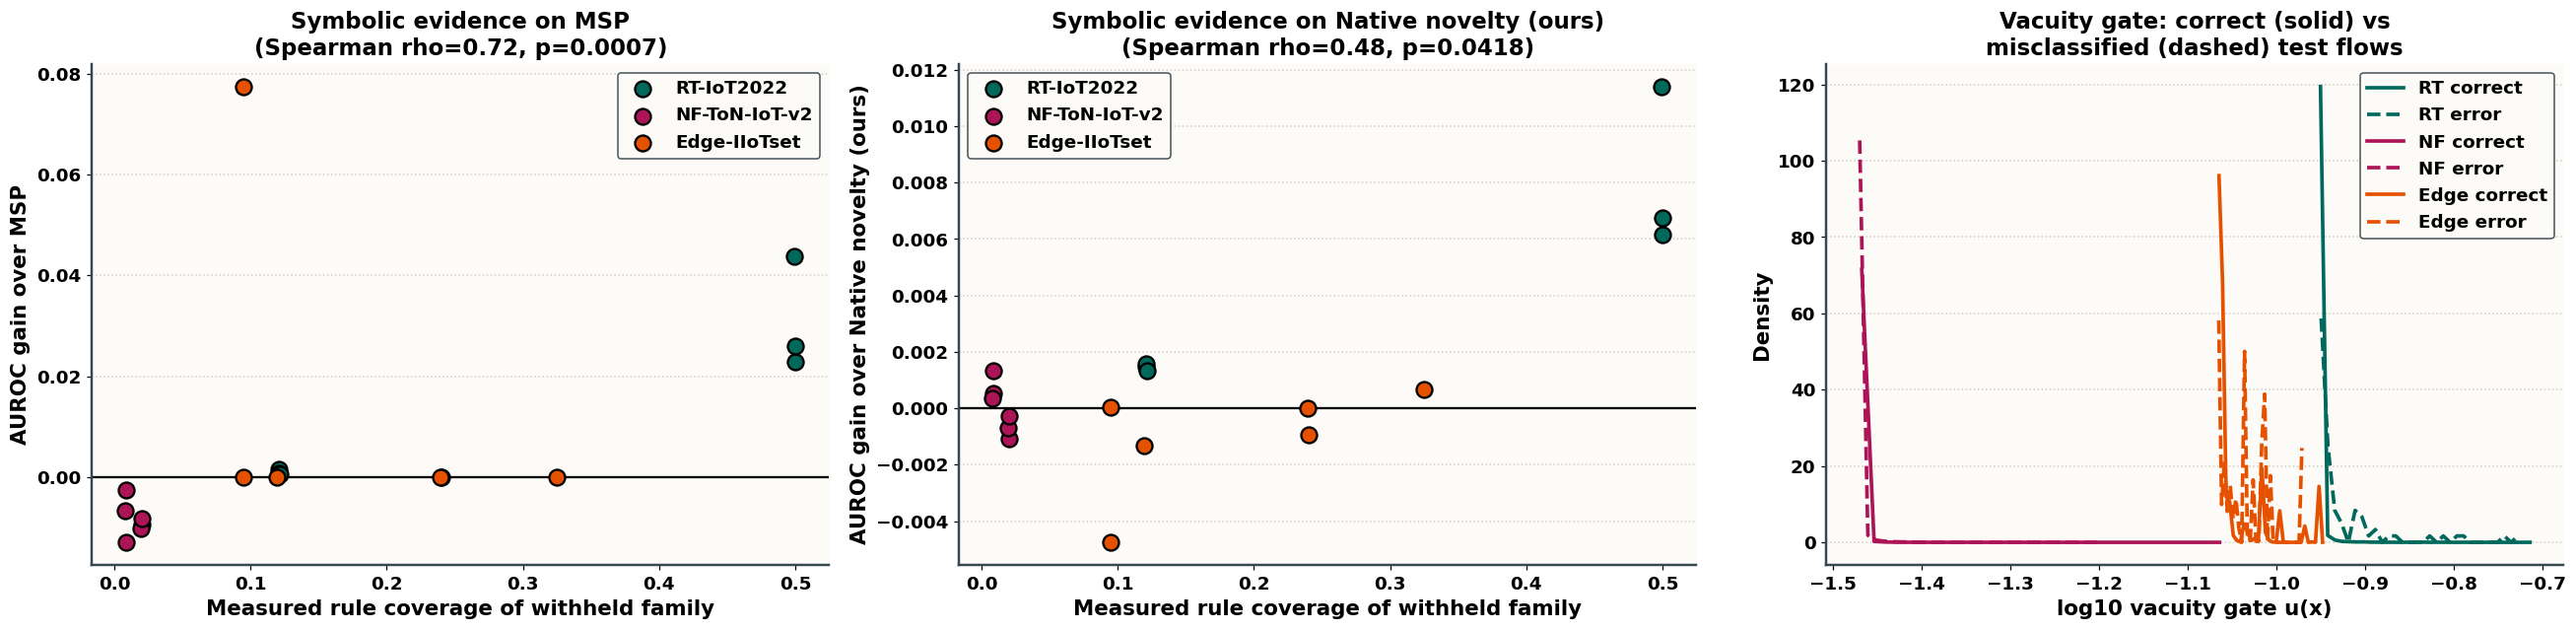

Figure 8. Left/centre: AUROC gain from the symbolic evidence channel versus measured rule coverage of the withheld attack family (gain emerges with coverage, stays near zero without it - the do-no-harm property). Right: vacuity-gate distributions; correctly classified flows concentrate at low vacuity (never perturbed), misclassified flows at high vacuity (where rules are allowed to act).
Cell 12b - Figure 8 is complete


In [16]:
# Cell 12b - Figure 8: coverage dose-response + vacuity-gate diagnostics
#   Left/centre: each point = one (dataset, holdout, seed) run. x = measured
#   weighted rule coverage of the withheld family; y = AUROC gain from adding
#   symbolic evidence to the base score. The a-priori covered/control dichotomy
#   is replaced by measured coverage: benefit appears when and only when the
#   unseen family exhibits the rule-encoded behaviors (do-no-harm property).
#   Right: distribution of the count-backed vacuity gate u(x) on correctly vs incorrectly
#   classified test flows (rep seed) - correct flows should concentrate at low
#   vacuity (rules essentially never perturb them) and errors spread toward
#   high vacuity (exactly where symbolic evidence is allowed to act). Because
#   the SAME u(x) is the zero-day score of Cell 12, this one panel validates
#   both the closed-set gate and the open-set detector.
# --------------------------------------------------------------------------------
print('Cell 12b - Figure 8: coverage dose-response + vacuity-gate diagnostics')
from scipy.stats import spearmanr
DCOL = {"RT-IoT2022": "#00695C", "NF-ToN-IoT-v2": "#AD1457", "Edge-IIoTset": "#E65100"}
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, base, tag in [(axes[0], "MSP", "MSP + symbolic evid."),
                      (axes[1], "Native novelty (ours)", "Native novelty + symbolic evid.")]:
    if not len(ZD_DF):
        continue
    cov  = ZD_DF["WeightedActivation"].values
    gain = (ZD_DF[f"{tag} AUROC"] - ZD_DF[f"{base} AUROC"]).values
    for ds in DCOL:
        m = (ZD_DF.Dataset == ds).values
        ax.scatter(cov[m], gain[m], s=110, color=DCOL[ds], edgecolor="black",
                   linewidth=1.5, label=ds, zorder=3)
    rho, p = spearmanr(cov, gain)
    ax.axhline(0, color="black", linewidth=1.5)
    ax.set_xlabel("Measured rule coverage of withheld family")
    ax.set_ylabel(f"AUROC gain over {base}")
    ax.set_title(f"Symbolic evidence on {base}\n(Spearman rho={rho:.2f}, p={p:.4f})")
    ax.legend(prop={"weight": "bold"}); bold_ticks(ax)
# vacuity-gate diagnostics on the closed-set representative models
ax = axes[2]
for name, d in DATA.items():
    u = vacuity_np(MODELS[name].base_evidence(d["Xte"]))
    pred = RESULTS_REP[name]["Neural"]["pred"]
    ok = pred == d["yte"]
    for mask, ls, lab in [(ok, "-", "correct"), (~ok, "--", "error")]:
        if mask.sum() < 10: continue
        hist, edges = np.histogram(np.log10(u[mask] + 1e-6), bins=30, density=True)
        ax.plot((edges[:-1] + edges[1:]) / 2, hist, ls, color=DCOL[name],
                linewidth=2.4, label=f"{name.split('-')[0]} {lab}")
ax.set_xlabel("log10 vacuity gate u(x)"); ax.set_ylabel("Density")
ax.set_title("Vacuity gate: correct (solid) vs\nmisclassified (dashed) test flows")
ax.legend(prop={"weight": "bold"}, fontsize=9); bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig8_dose_response_and_gate.png"); plt.show()
print("Figure 8. Left/centre: AUROC gain from the symbolic evidence channel versus measured "
      "rule coverage of the withheld attack family (gain emerges with coverage, stays near "
      "zero without it - the do-no-harm property). Right: vacuity-gate distributions; "
      "correctly classified flows concentrate at low vacuity (never perturbed), "
      "misclassified flows at high vacuity (where rules are allowed to act).")
print('Cell 12b - Figure 8 is complete')

Cell 13 - Rule-weight figure, seed stability + radar, summary + export


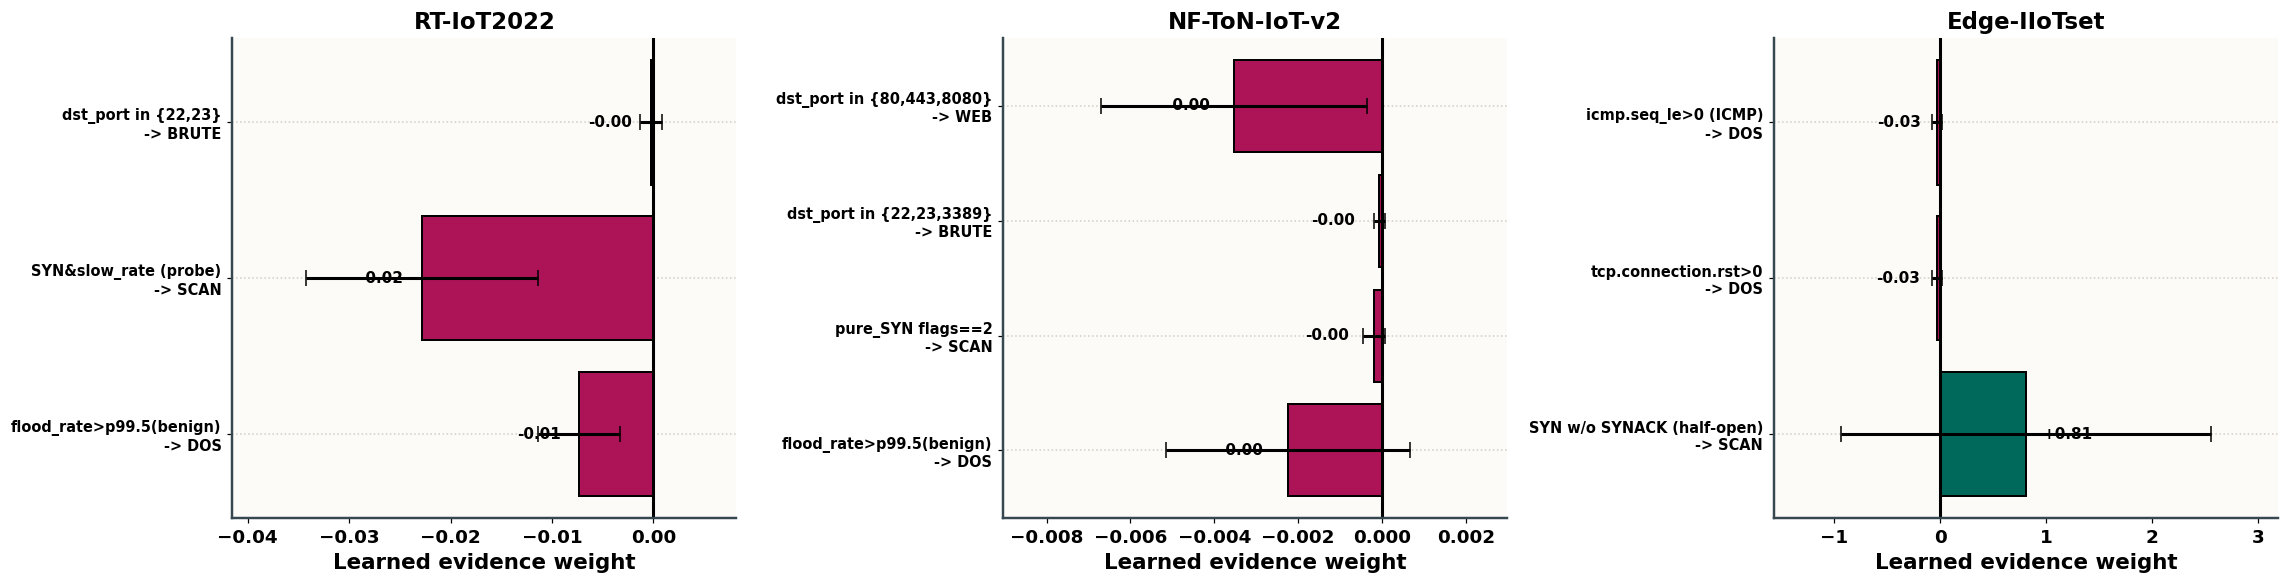

Figure 9. Learned symbolic evidence weights (mean +/- std across seeds). Zero-gated panels indicate the validation gate found no closed-set benefit; negative weights mean the rule fires predominantly outside its target group.


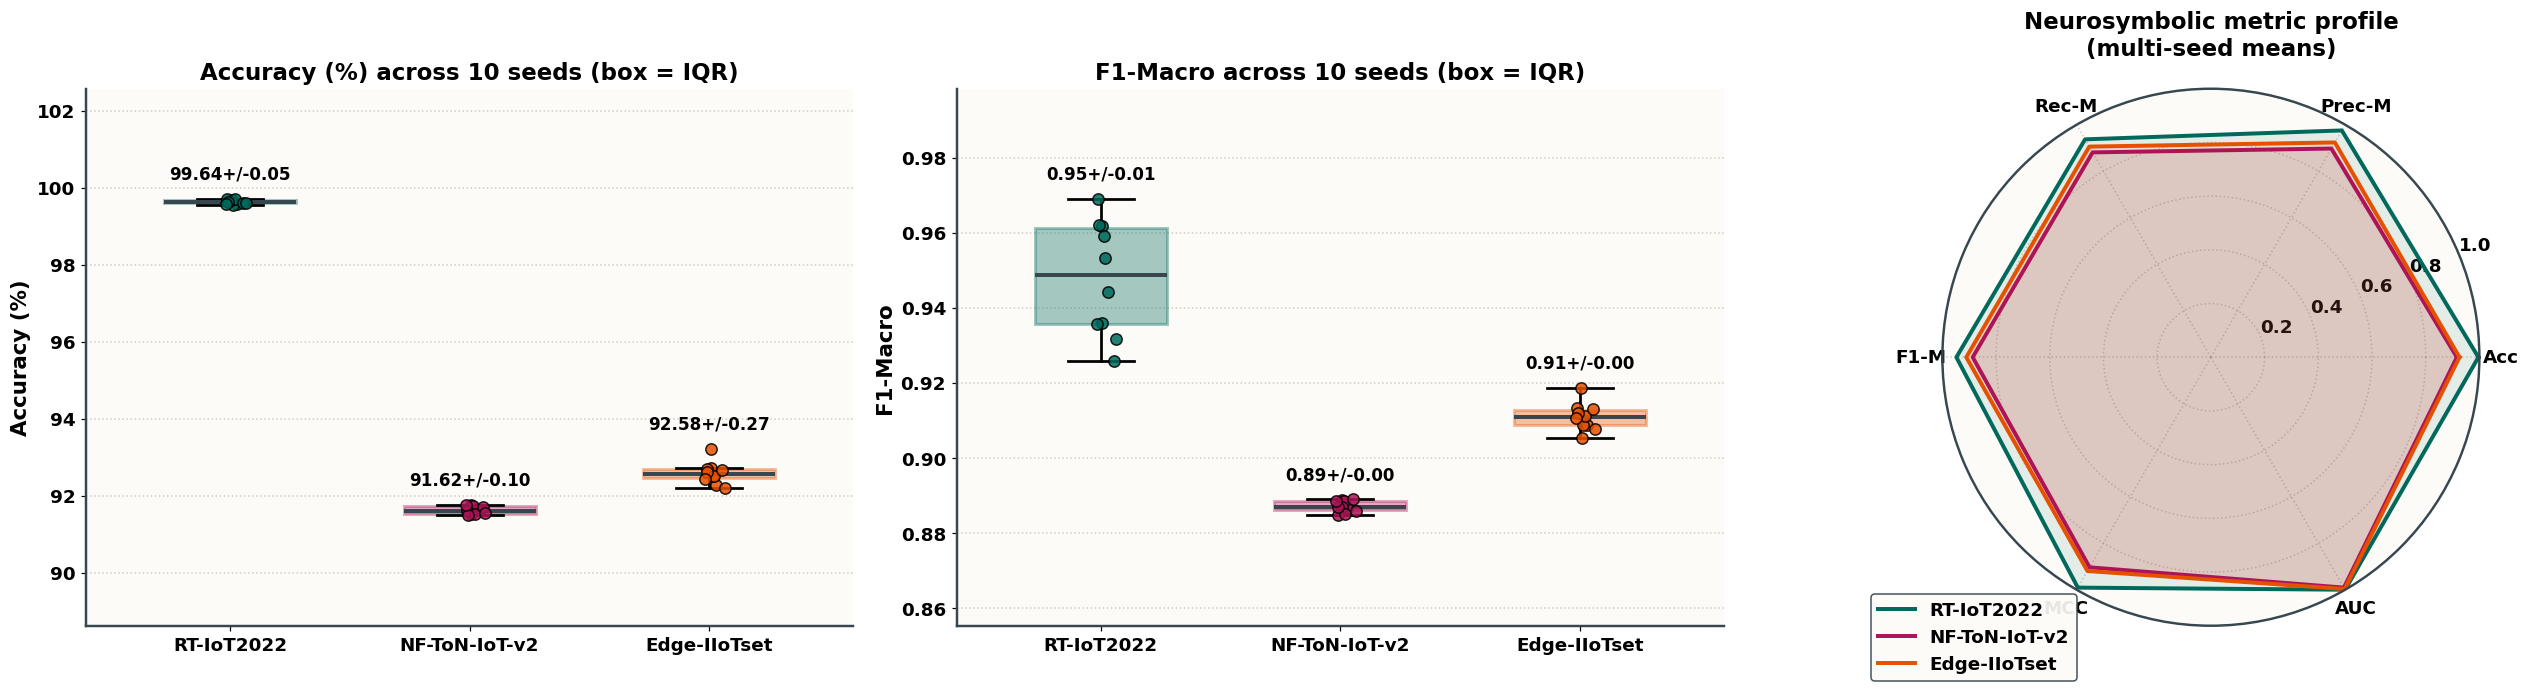

Figure 10. Seed stability of accuracy and macro-F1 (diamond = mean +/- std; small points = individual seeds) and radar profile of six headline metrics per dataset.
               Classes  Seeds  Accuracy mean  Accuracy std  Precision-M mean  Precision-M std  Recall-M mean  Recall-M std  F1-Macro mean  F1-Macro std  Precision-W mean  Precision-W std  Recall-W mean  Recall-W std  F1-Weighted mean  F1-Weighted std  MCC mean  MCC std  Cohen-kappa mean  Cohen-kappa std  Balanced-Acc mean  Balanced-Acc std  G-mean mean  G-mean std  ROC-AUC mean  ROC-AUC std  PR-AUC mean  PR-AUC std  DR/TPR mean  DR/TPR std  FAR/FPR mean  FAR/FPR std  Sym. dF1m Wilcoxon p (F1m) ZD dAUROC covered ZD dAUROC control ZD margin vs best OOD (covered)  Train time (s/seed) Deploy variant  Latency (ms/flow)  Leaf entries  Cascade levels  Deploy size (KB)  p99 latency (ms)
Dataset                                                                                                                                             

In [17]:
# Cell 13 - Figure 9: learned rule weights | Figure 10: seed stability + metric radar |
#            summary tables + artifact export
# --------------------------------------------------------------------------------------
print('Cell 13 - Rule-weight figure, seed stability + radar, summary + export')

# Figure 9: learned rule evidence weights (mean +/- std across seeds)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, name in zip(axes, EXP):
    eng = ENGINES[name]
    W = np.array([run["w"] for run in EXP[name]], dtype=float)   # (seeds, rules)
    mu, sd = W.mean(0), W.std(0)
    ax.set_yticks(range(len(mu)))
    ax.set_yticklabels([f"{n}\n-> {g}" for n, g in zip(eng.rule_names, eng.rule_groups)],
                       fontsize=9.5, fontweight="bold")
    ax.axvline(0, color="black", linewidth=2)
    ax.set_xlabel("Learned evidence weight"); ax.set_title(name); bold_ticks(ax)
    if np.all(np.abs(mu) + sd < 1e-6):                    # all weights gated to zero
        ax.set_xlim(-1, 1)
        ax.text(0, (len(mu) - 1) / 2, "all rule weights gated to 0\n(no closed-set contribution)",
                ha="center", va="center", fontsize=12, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#EFEBE9",
                          edgecolor="black", linewidth=1.5))
        continue
    colors = ["#00695C" if m >= 0 else "#AD1457" for m in mu]
    ax.barh(range(len(mu)), mu, xerr=sd, color=colors, edgecolor="black",
            linewidth=1.3, capsize=5, error_kw=dict(lw=2, ecolor="black"))
    lo = min(0.0, float((mu - sd).min())); hi = max(0.0, float((mu + sd).max()))
    pad = (hi - lo) * 0.18 + 1e-3
    ax.set_xlim(lo - pad, hi + pad)
    for yi, (m, s_) in enumerate(zip(mu, sd)):
        if abs(m) + s_ < 1e-6: continue
        ax.annotate(f"{m:+.2f}", (m + (pad * .25 if m >= 0 else -pad * .25), yi),
                    va="center", ha="left" if m >= 0 else "right",
                    fontweight="bold", fontsize=10, clip_on=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig9_learned_rule_weights.png"); plt.show()
print("Figure 9. Learned symbolic evidence weights (mean +/- std across seeds). "
      "Zero-gated panels indicate the validation gate found no closed-set benefit; "
      "negative weights mean the rule fires predominantly outside its target group.")

# Figure 10: seed stability (left two panels) + metric radar (right panel)
cmap = {"RT-IoT2022": "#00695C", "NF-ToN-IoT-v2": "#AD1457", "Edge-IIoTset": "#E65100"}
fig = plt.figure(figsize=(24, 6.5))
a1 = fig.add_subplot(1, 3, 1); a2 = fig.add_subplot(1, 3, 2)
ar = fig.add_subplot(1, 3, 3, projection="polar")
for ax, key, lab in [(a1, "acc", "Accuracy (%)"), (a2, "f1_m", "F1-Macro")]:
    data, names = [], list(EXP.keys())
    for name in names:
        v = np.array([run["res"]["Neurosymbolic"][key] for run in EXP[name]], dtype=float)
        data.append(v * 100 if key == "acc" else v)
    bp = ax.boxplot(data, positions=range(len(names)), widths=0.55, patch_artist=True,
                    medianprops=dict(color="#37474F", linewidth=2.6),
                    whiskerprops=dict(linewidth=1.8), capprops=dict(linewidth=1.8),
                    flierprops=dict(marker="none"))
    for patch, name in zip(bp["boxes"], names):
        patch.set_facecolor(cmap[name]); patch.set_alpha(0.35)
        patch.set_edgecolor(cmap[name]); patch.set_linewidth(2)
    for xi, (name, v) in enumerate(zip(names, data)):
        jit = (np.random.RandomState(0).rand(len(v)) - .5) * 0.14
        ax.scatter(np.full(len(v), xi) + jit, v, s=55, color=cmap[name], alpha=.85,
                   edgecolor="black", linewidth=1.0, zorder=3)
        ax.annotate(f"{v.mean():.2f}+/-{v.std():.2f}", (xi, np.max(v)),
                    xytext=(0, 13), textcoords="offset points", ha="center",
                    fontweight="bold", fontsize=11, clip_on=False)
    ax.set_xticks(range(len(EXP))); ax.set_xticklabels(EXP.keys(), fontweight="bold")
    ax.set_xlim(-0.6, len(EXP) - 0.4)
    lo = min(v.min() for v in data); hi = max(v.max() for v in data)
    pad = max((hi - lo) * 0.35, (2.0 if key == "acc" else 0.02))
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_ylabel(lab); ax.set_title(f"{lab} across {N_SEEDS} seeds (box = IQR)"); bold_ticks(ax)
# metric radar: multi-seed means of six headline metrics per dataset
RADAR_KEYS = [("acc","Acc"), ("prec_m","Prec-M"), ("rec_m","Rec-M"),
              ("f1_m","F1-M"), ("mcc","MCC"), ("auc","AUC")]
ang = np.linspace(0, 2 * np.pi, len(RADAR_KEYS), endpoint=False).tolist()
ang += ang[:1]
for name in EXP:
    vals = [agg(name, "Neurosymbolic", k)[0] for k, _ in RADAR_KEYS]
    vals += vals[:1]
    ar.plot(ang, vals, color=cmap[name], linewidth=2.6, label=name)
    ar.fill(ang, vals, color=cmap[name], alpha=0.10)
ar.set_xticks(ang[:-1]); ar.set_xticklabels([l for _, l in RADAR_KEYS], fontweight="bold")
ar.set_ylim(0, 1.0); ar.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ar.set_title("Neurosymbolic metric profile\n(multi-seed means)", pad=22)
ar.legend(loc="lower left", bbox_to_anchor=(-0.15, -0.12), prop={"weight": "bold"}, fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig10_seed_stability_radar.png"); plt.show()
print("Figure 10. Seed stability of accuracy and macro-F1 (diamond = mean +/- std; small "
      "points = individual seeds) and radar profile of six headline metrics per dataset.")

# publication summary tables + artifact export
OOD_TAGS = ["MSP", "ODIN (T=1000)", "Mahalanobis", "Vacuity", "Coverage rarity", "Native novelty (ours)"]
rows = []
for name in EXP:
    p = PROF[name]
    tt = np.array([r["train_s"] for r in EXP[name]])
    row = {"Dataset": name, "Classes": len(DATA[name]["classes"]), "Seeds": len(EXP[name])}
    for k, lab in METRIC_KEYS:
        mu, sd = agg(name, "Neurosymbolic", k)
        row[f"{lab} mean"], row[f"{lab} std"] = round(mu, 4), round(sd, 4)
    for k, lab in [("det_tpr", "DR/TPR"), ("det_fpr", "FAR/FPR")]:
        mu, sd = agg(name, "Neurosymbolic", k)
        row[f"{lab} mean"], row[f"{lab} std"] = round(mu, 4), round(sd, 4)
    mu_n, _ = agg(name, "Neural", "f1_m"); mu_s, _ = agg(name, "Neurosymbolic", "f1_m")
    def zd_gain(kind):
        if not len(ZD_DF): return np.nan
        sub = ZD_DF[(ZD_DF.Dataset == name) & (ZD_DF.Kind == kind)]
        if not len(sub): return np.nan
        return (sub["Native novelty + symbolic evid. AUROC"].mean()
                - sub["Native novelty (ours) AUROC"].mean())
    def zd_vs_best_ood(kind):
        # margin of ours over the STRONGEST OOD baseline on the same holdouts
        if not len(ZD_DF): return np.nan
        sub = ZD_DF[(ZD_DF.Dataset == name) & (ZD_DF.Kind == kind)]
        if not len(sub): return np.nan
        best = max(sub[f"{t} AUROC"].mean() for t in OOD_TAGS)
        return sub["Native novelty + symbolic evid. AUROC"].mean() - best
    zg_cov, zg_ctl = zd_gain("rule-covered"), zd_gain("negative-control")
    zb_cov = zd_vs_best_ood("rule-covered")
    row.update({"Sym. dF1m": round(mu_s - mu_n, 4),
                "Wilcoxon p (F1m)": (round(SIGNIF[name]["f1_m"][0], 4)
                                     if not np.isnan(SIGNIF[name]["f1_m"][0]) else "n/a"),
                "ZD dAUROC covered": round(zg_cov, 4) if not np.isnan(zg_cov) else "n/a",
                "ZD dAUROC control": round(zg_ctl, 4) if not np.isnan(zg_ctl) else "n/a",
                "ZD margin vs best OOD (covered)": round(zb_cov, 4) if not np.isnan(zb_cov) else "n/a",
                "Train time (s/seed)": round(tt.mean(), 1),
                "Deploy variant": p["variant"], "Latency (ms/flow)": round(p["lat"], 4),
                "Leaf entries": int(sum(t["leaf"].size for t in MODELS[name].all_tabs)),
                "Cascade levels": MODELS[name].n_levels,
                "Deploy size (KB)": round(p["size_kb"], 1),
                "p99 latency (ms)": round(p["p99"], 3)})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Dataset")
pd.set_option("display.width", 260); print(summary.to_string())
summary.to_csv("evitab_ns_summary.csv")

per_seed = pd.DataFrame([{"Dataset": n, "Seed": run["seed"], "Tag": tag,
                          "TrainTime_s": run["train_s"],
                          **{k: run["res"][tag][k] for k, _ in METRIC_KEYS}}
                         for n in EXP for run in EXP[n] for tag in ("Neural", "Neurosymbolic")])
per_seed.to_csv("evitab_ns_per_seed.csv", index=False)

for name, m in MODELS.items():
    dep = PROF[name]["deployed"]
    arrays = {}
    for lv, (tA, tB) in enumerate(dep.levels, start=1):
        for side, t in [("a", tA), ("b", tB)]:
            src = m.levels[lv - 1][0 if side == "a" else 1]      # fp32 counts source
            arrays[f"lv{lv}{side}_feat"] = t["feat"]
            arrays[f"lv{lv}{side}_thr"]  = t["thr"]
            arrays[f"lv{lv}{side}_leaf"] = t["leaf"]
            if "scale" in t: arrays[f"lv{lv}{side}_scale"] = t["scale"]
            arrays[f"lv{lv}{side}_leaf0"] = t.get("leaf0", src["leaf0"])
    np.savez_compressed(f"evitab_ns_{name}.npz",
        n_levels=np.array([len(dep.levels)]), use_avg=np.array([int(m.use_avg)]),
        cov_feat=m.cov["feat"], cov_thr=m.cov["thr"], cov_logp=m.cov["logp"],
        fusion_w=np.array(FUSIONS[name].w.detach().tolist()),
        rules=np.array(ENGINES[name].rule_names), classes=np.array(list(DATA[name]["classes"])),
        features=np.array(DATA[name]["feat_names"]), **arrays)

print(f"\n{'-'*80}")
for name in EXP:
    mu, sd = agg(name, "Neurosymbolic", "f1_m")
    tt = np.array([r["train_s"] for r in EXP[name]])
    print(f"{name:15s} F1-Macro = {mu:.4f}+/-{sd:.4f} | "
          f"accuracy = {agg(name,'Neurosymbolic','acc')[0]*100:.2f}% | "
          f"train {tt.mean():.0f}s/seed | deployed {PROF[name]['variant']} @ "
          f"{PROF[name]['lat']:.3f} ms/flow (single thread, zero mat-mul)")
print("All results are reported as measured - no target-driven adjustment was applied.")
print("Figures -> ./figures | CSVs: summary, per-seed, baselines, zero-day | models -> .pt")
print('Cell 13 - Rule weights, seed stability + radar, summary + export is complete')

# publication master table: every headline measurement
PUB_ROWS = []
for name in EXP:
    p = PROF[name]
    tt = np.array([r["train_s"] for r in EXP[name]])
    rep = RESULTS_REP[name]["Neurosymbolic"]
    row = {"Dataset": name, "Seeds": len(EXP[name])}
    for k, lab in METRIC_KEYS:                          # multi-seed mean +/- std
        mu, sd = agg(name, "Neurosymbolic", k)
        row[lab] = f"{mu*100:.2f}+/-{sd*100:.2f}" if k == "acc" else f"{mu:.4f}+/-{sd:.4f}"
    for k, lab in [("det_tpr", "TPR/DR"), ("det_tnr", "TNR"),
                   ("det_fpr", "FPR/FAR"), ("det_fnr", "FNR")]:
        mu, sd = agg(name, "Neurosymbolic", k)
        row[lab] = f"{mu:.4f}+/-{sd:.4f}"
    row.update({"TP (rep seed)": rep["TP"], "TN (rep seed)": rep["TN"],
                "FP (rep seed)": rep["FP"], "FN (rep seed)": rep["FN"],
                "Latency p50 (ms)": round(p["lat"], 4), "Latency p99 (ms)": round(p["p99"], 4),
                "Throughput (flows/s)": int(p["thru"]),
                "Model size (KB)": round(p["size_kb"], 1),
                "Size + novelty ch. (KB)": round(p["size_full"], 1),
                "Deployed variant": p["variant"],
                "Fit time (s/seed)": f"{tt.mean():.0f}+/-{tt.std():.0f}"})
    PUB_ROWS.append(row)
PUB_TABLE = pd.DataFrame(PUB_ROWS).set_index("Dataset")
PUB_TABLE.to_csv("evitab_ns_publication_table.csv")
print("\n================= PUBLICATION MASTER TABLE (also in evitab_ns_publication_table.csv) =================")
with pd.option_context("display.max_columns", None, "display.width", 260):
    print(PUB_TABLE.T.to_string())

Cell 14 - Confusion-derived rates + ROC/PR curves + detection-rate bars

RT-IoT2022: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=22,108  FN=14  FP=31  TN=2,471
  Detection Rate (TPR)=0.9994  False Alarm Rate (FPR)=0.0124  TNR=0.9876  FNR=0.0006  PPV=0.9986  NPV=0.9944

NF-ToN-IoT-v2: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=124,850  FN=618  FP=946  TN=19,054
  Detection Rate (TPR)=0.9951  False Alarm Rate (FPR)=0.0473  TNR=0.9527  FNR=0.0049  PPV=0.9925  NPV=0.9686

Edge-IIoTset: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=25,625  FN=0  FP=0  TN=4,821
  Detection Rate (TPR)=1.0000  False Alarm Rate (FPR)=0.0000  TNR=1.0000  FNR=0.0000  PPV=1.0000  NPV=1.0000

Per-class one-vs-rest rates (first rows):
   Dataset                      Class  Support    TP  FN  FP    TN    TPR    TNR    FPR    FNR    PPV    NPV
RT-IoT2022             ARP_poisioning     1550  1538  12  26 23048 0.9923 0.9989 0.0011 0.0077 0.9834 0.9995
RT-IoT2022             DDOS

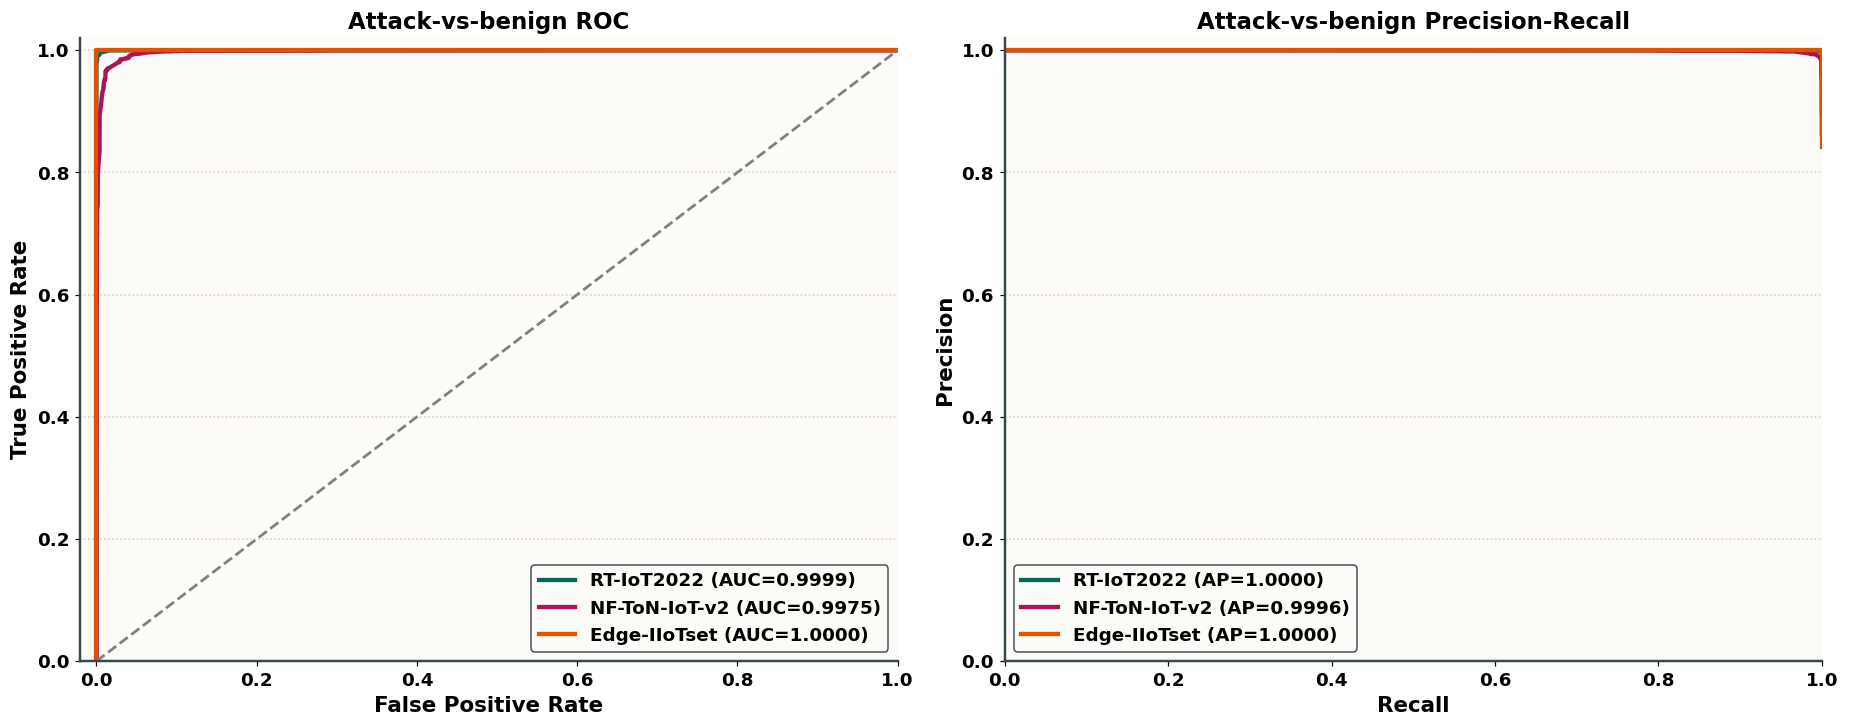

Figure 11. Binary attack-vs-benign ROC (left) and precision-recall (right) curves of the fused neurosymbolic scores (fixed reference seed); P(attack) = sum of attack-class posteriors from the fused Dirichlet mean.


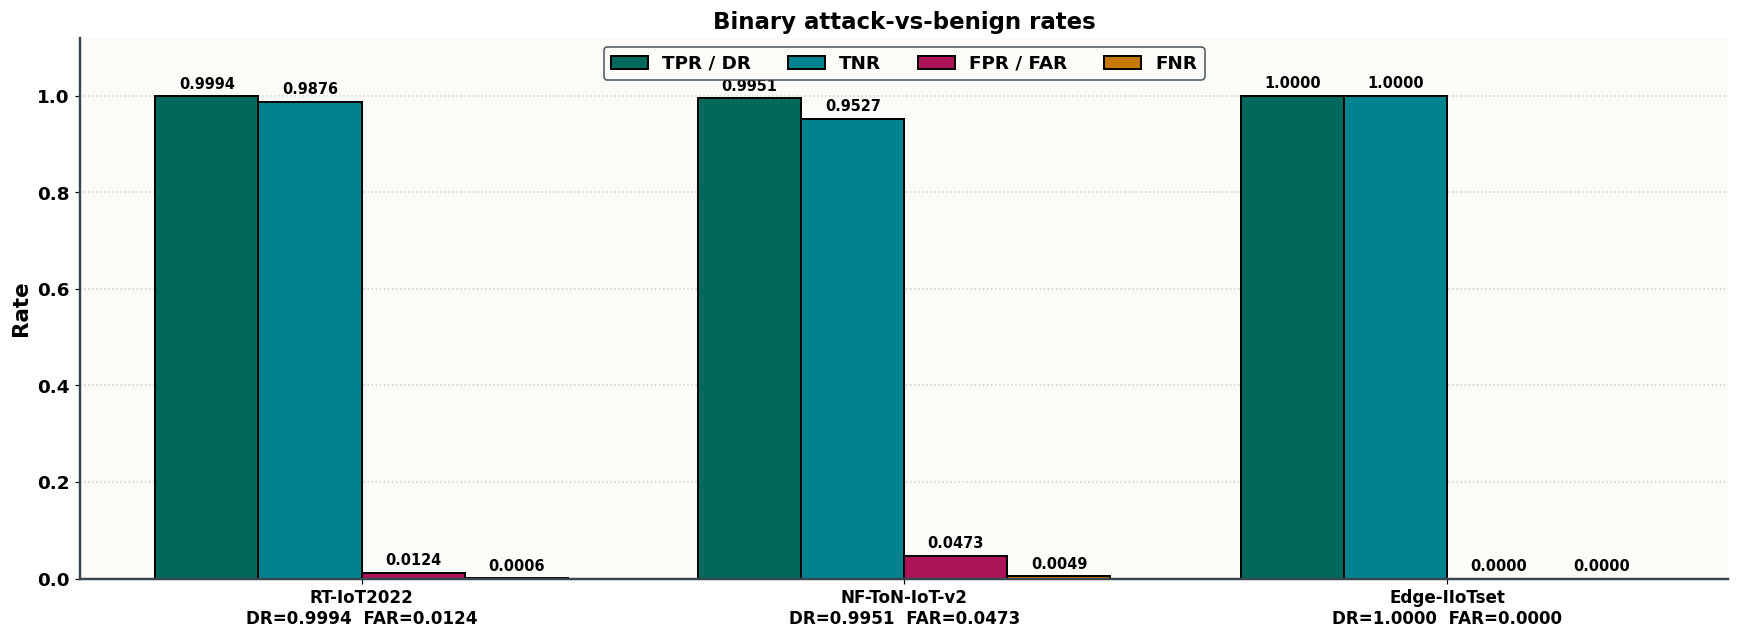

Figure 12. Binary attack-vs-benign detection rates (fixed reference seed): TPR/DR, TNR, FPR/FAR and FNR per dataset; per-seed means and counts in evitab_ns_publication_table.csv.
Cell 14 - Confusion-derived rates + ROC/PR curves + detection-rate bars

RT-IoT2022: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=22,108  FN=14  FP=31  TN=2,471
  Detection Rate (TPR)=0.9994  False Alarm Rate (FPR)=0.0124  TNR=0.9876  FNR=0.0006  PPV=0.9986  NPV=0.9944

NF-ToN-IoT-v2: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=124,850  FN=618  FP=946  TN=19,054
  Detection Rate (TPR)=0.9951  False Alarm Rate (FPR)=0.0473  TNR=0.9527  FNR=0.0049  PPV=0.9925  NPV=0.9686

Edge-IIoTset: binary attack-vs-benign (rep seed 42, neurosymbolic)
  TP=25,625  FN=0  FP=0  TN=4,821
  Detection Rate (TPR)=1.0000  False Alarm Rate (FPR)=0.0000  TNR=1.0000  FNR=0.0000  PPV=1.0000  NPV=1.0000

Per-class one-vs-rest rates (first rows):
   Dataset                      Class  Support    TP  FN  FP    TN

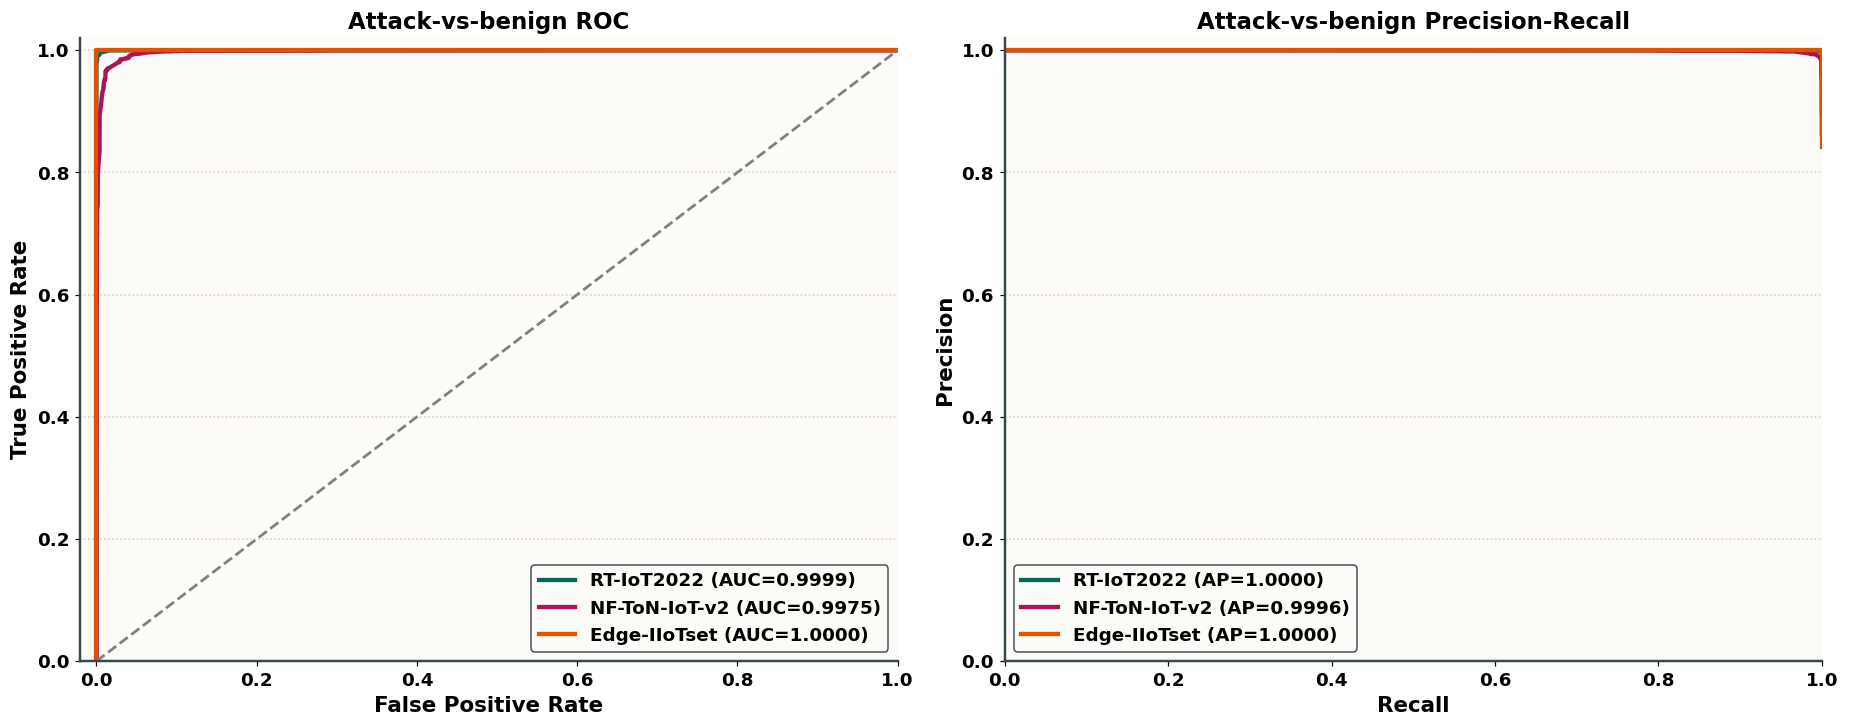

Figure 11. Binary attack-vs-benign ROC (left) and precision-recall (right) curves of the fused neurosymbolic scores (fixed reference seed); P(attack) = sum of attack-class posteriors from the fused Dirichlet mean.


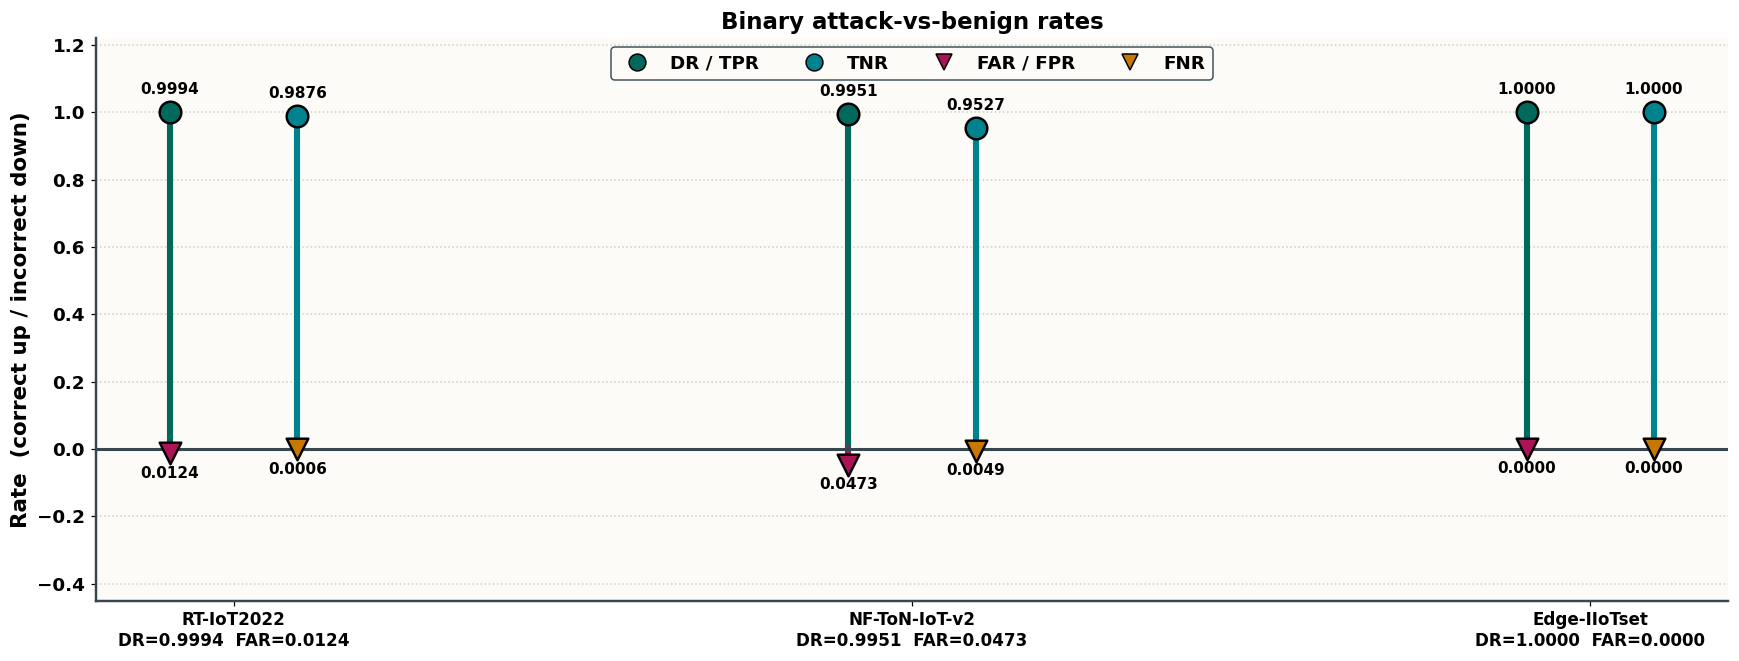

Figure 12 (mirrored lollipop). Binary attack-vs-benign rates: correct rates point up, error rates down - a deployment-oriented at-a-glance summary.
Cell 14 - Confusion-derived rates + ROC/PR + detection-rate bars is complete


In [18]:
# Cell 14 - Confusion-derived rates (TP/TN/FP/FN, TPR/TNR/FPR/FNR, +PPV/NPV, DR/FAR)
#           per class and binary attack-vs-benign | Figure 11: ROC + PR curves |
#           Figure 12: detection-rate bars
# ------------------------------------------------------------------------------------
print('Cell 14 - Confusion-derived rates + ROC/PR curves + detection-rate bars')

def rates_from_counts(tp, fn, fp, tn):
    return dict(TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn),
                TPR=tp/(tp+fn) if tp+fn else np.nan,      # sensitivity / recall / detection rate
                TNR=tn/(tn+fp) if tn+fp else np.nan,      # specificity
                FPR=fp/(fp+tn) if fp+tn else np.nan,      # false-alarm rate
                FNR=fn/(fn+tp) if fn+tp else np.nan,      # miss rate
                PPV=tp/(tp+fp) if tp+fp else np.nan,      # precision
                NPV=tn/(tn+fn) if tn+fn else np.nan)

PERCLASS_ROWS, BIN_ROWS = [], []
for name, d in DATA.items():
    y, pred = d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"]
    cm = confusion_matrix(y, pred); total = cm.sum()
    for i, cls in enumerate(d["classes"]):                 # one-vs-rest per class
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp
        PERCLASS_ROWS.append({"Dataset": name, "Class": cls, "Support": int(cm[i].sum()),
                              **rates_from_counts(tp, fn, fp, total - tp - fn - fp)})
    is_att_true = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[y]
    is_att_pred = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[pred]
    tp = int(( is_att_true &  is_att_pred).sum()); fn = int(( is_att_true & ~is_att_pred).sum())
    fp = int((~is_att_true &  is_att_pred).sum()); tn = int((~is_att_true & ~is_att_pred).sum())
    r = rates_from_counts(tp, fn, fp, tn)
    r["Accuracy"] = (tp + tn) / total
    BIN_ROWS.append({"Dataset": name, **r})
    print(f"\n{name}: binary attack-vs-benign (rep seed {REP_SEED}, neurosymbolic)")
    print(f"  TP={tp:,}  FN={fn:,}  FP={fp:,}  TN={tn:,}")
    print(f"  Detection Rate (TPR)={r['TPR']:.4f}  False Alarm Rate (FPR)={r['FPR']:.4f}  "
          f"TNR={r['TNR']:.4f}  FNR={r['FNR']:.4f}  PPV={r['PPV']:.4f}  NPV={r['NPV']:.4f}")

perclass = pd.DataFrame(PERCLASS_ROWS).round(4); binary = pd.DataFrame(BIN_ROWS).round(4)
print("\nPer-class one-vs-rest rates (first rows):"); print(perclass.head(12).to_string(index=False))
perclass.to_csv("perclass_confusion_rates.csv", index=False)
binary.to_csv("binary_detection_rates.csv", index=False)

# Figure 11: binary attack-vs-benign ROC and PR curves (rep seed, fused scores)
fig, (r1, r2) = plt.subplots(1, 2, figsize=(17, 6.8))
DCOL2 = {"RT-IoT2022": "#00695C", "NF-ToN-IoT-v2": "#AD1457", "Edge-IIoTset": "#E65100"}
for name, d in DATA.items():
    ev = MODELS[name].evidence(d["Xte"])
    A_te = ENGINES[name].activations(d["raw_test"])
    proba = prob_np(apply_fusion(FUSIONS[name], ev, A_te))
    att_cls = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])
    y_att   = att_cls[d["yte"]].astype(int)
    p_att   = proba[:, att_cls].sum(1)                    # P(attack) = sum of attack-class probs
    fpr, tpr, _ = roc_curve(y_att, p_att)
    prec, rec, _ = precision_recall_curve(y_att, p_att)
    auc_v = roc_auc_score(y_att, p_att); ap_v = average_precision_score(y_att, p_att)
    r1.plot(fpr, tpr, color=DCOL2[name], linewidth=2.8, label=f"{name} (AUC={auc_v:.4f})")
    r2.plot(rec, prec, color=DCOL2[name], linewidth=2.8, label=f"{name} (AP={ap_v:.4f})")
r1.plot([0, 1], [0, 1], "--", color="grey", linewidth=1.8)
r1.set_xlabel("False Positive Rate"); r1.set_ylabel("True Positive Rate")
r1.set_title("Attack-vs-benign ROC"); r1.legend(prop={"weight": "bold"}, loc="lower right")
r1.set_xlim(-0.02, 1.0); r1.set_ylim(0, 1.02); bold_ticks(r1)
r2.set_xlabel("Recall"); r2.set_ylabel("Precision")
r2.set_title("Attack-vs-benign Precision-Recall")
r2.legend(prop={"weight": "bold"}, loc="lower left")
r2.set_xlim(0, 1.0); r2.set_ylim(0, 1.02); bold_ticks(r2)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig11_roc_pr_curves.png"); plt.show()
print("Figure 11. Binary attack-vs-benign ROC (left) and precision-recall (right) curves of the "
      "fused neurosymbolic scores (fixed reference seed); P(attack) = sum of attack-class "
      "posteriors from the fused Dirichlet mean.")

# Figure 12: binary detection-rate grouped bars (traditional)
fig, ax = plt.subplots(figsize=(16, 6))
keys = [("TPR", "TPR / DR", "#00695C"), ("TNR", "TNR", "#00838F"),
        ("FPR", "FPR / FAR", "#AD1457"), ("FNR", "FNR", "#C77800")]
xx = np.arange(len(BIN_ROWS)); w = 0.19
for k, (key, lab, col) in enumerate(keys):
    v = [row[key] for row in BIN_ROWS]
    b = ax.bar(xx + (k - 1.5) * w, v, w, label=lab, color=col,
               edgecolor="black", linewidth=1.3)
    ax.bar_label(b, fmt="%.4f", fontweight="bold", fontsize=9.5, padding=3)
ax.set_xticks(xx)
ax.set_xticklabels([f"{row['Dataset']}\nDR={row['TPR']:.4f}  FAR={row['FPR']:.4f}"
                    for row in BIN_ROWS], fontweight="bold", fontsize=11)
ax.set_ylim(0, 1.12); ax.set_ylabel("Rate")
ax.legend(ncols=4, loc="upper center", prop={"weight": "bold"})
ax.set_title("Binary attack-vs-benign rates")
bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig12_detection_rates.png"); plt.show()
print("Figure 12. Binary attack-vs-benign detection rates (fixed reference seed): "
      "TPR/DR, TNR, FPR/FAR and FNR per dataset; per-seed means and counts in "
      "evitab_ns_publication_table.csv.")
print('Cell 14 - Confusion-derived rates + ROC/PR curves + detection-rate bars')

def rates_from_counts(tp, fn, fp, tn):
    return dict(TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn),
                TPR=tp/(tp+fn) if tp+fn else np.nan,      # sensitivity / recall / detection rate
                TNR=tn/(tn+fp) if tn+fp else np.nan,      # specificity
                FPR=fp/(fp+tn) if fp+tn else np.nan,      # false-alarm rate
                FNR=fn/(fn+tp) if fn+tp else np.nan,      # miss rate
                PPV=tp/(tp+fp) if tp+fp else np.nan,      # precision
                NPV=tn/(tn+fn) if tn+fn else np.nan)

PERCLASS_ROWS, BIN_ROWS = [], []
for name, d in DATA.items():
    y, pred = d["yte"], RESULTS_REP[name]["Neurosymbolic"]["pred"]
    cm = confusion_matrix(y, pred); total = cm.sum()
    for i, cls in enumerate(d["classes"]):                 # one-vs-rest per class
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp
        PERCLASS_ROWS.append({"Dataset": name, "Class": cls, "Support": int(cm[i].sum()),
                              **rates_from_counts(tp, fn, fp, total - tp - fn - fp)})
    is_att_true = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[y]
    is_att_pred = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])[pred]
    tp = int(( is_att_true &  is_att_pred).sum()); fn = int(( is_att_true & ~is_att_pred).sum())
    fp = int((~is_att_true &  is_att_pred).sum()); tn = int((~is_att_true & ~is_att_pred).sum())
    r = rates_from_counts(tp, fn, fp, tn)
    r["Accuracy"] = (tp + tn) / total
    BIN_ROWS.append({"Dataset": name, **r})
    print(f"\n{name}: binary attack-vs-benign (rep seed {REP_SEED}, neurosymbolic)")
    print(f"  TP={tp:,}  FN={fn:,}  FP={fp:,}  TN={tn:,}")
    print(f"  Detection Rate (TPR)={r['TPR']:.4f}  False Alarm Rate (FPR)={r['FPR']:.4f}  "
          f"TNR={r['TNR']:.4f}  FNR={r['FNR']:.4f}  PPV={r['PPV']:.4f}  NPV={r['NPV']:.4f}")

perclass = pd.DataFrame(PERCLASS_ROWS).round(4); binary = pd.DataFrame(BIN_ROWS).round(4)
print("\nPer-class one-vs-rest rates (first rows):"); print(perclass.head(12).to_string(index=False))
perclass.to_csv("perclass_confusion_rates.csv", index=False)
binary.to_csv("binary_detection_rates.csv", index=False)

# Figure 11: binary attack-vs-benign ROC and PR curves (rep seed, fused scores)
fig, (r1, r2) = plt.subplots(1, 2, figsize=(17, 6.8))
DCOL2 = {"RT-IoT2022": "#00695C", "NF-ToN-IoT-v2": "#AD1457", "Edge-IIoTset": "#E65100"}
for name, d in DATA.items():
    ev = MODELS[name].evidence(d["Xte"])
    A_te = ENGINES[name].activations(d["raw_test"])
    proba = prob_np(apply_fusion(FUSIONS[name], ev, A_te))
    att_cls = np.array([class_to_group(c) != "BENIGN" for c in d["classes"]])
    y_att   = att_cls[d["yte"]].astype(int)
    p_att   = proba[:, att_cls].sum(1)                    # P(attack) = sum of attack-class probs
    fpr, tpr, _ = roc_curve(y_att, p_att)
    prec, rec, _ = precision_recall_curve(y_att, p_att)
    auc_v = roc_auc_score(y_att, p_att); ap_v = average_precision_score(y_att, p_att)
    r1.plot(fpr, tpr, color=DCOL2[name], linewidth=2.8, label=f"{name} (AUC={auc_v:.4f})")
    r2.plot(rec, prec, color=DCOL2[name], linewidth=2.8, label=f"{name} (AP={ap_v:.4f})")
r1.plot([0, 1], [0, 1], "--", color="grey", linewidth=1.8)
r1.set_xlabel("False Positive Rate"); r1.set_ylabel("True Positive Rate")
r1.set_title("Attack-vs-benign ROC"); r1.legend(prop={"weight": "bold"}, loc="lower right")
r1.set_xlim(-0.02, 1.0); r1.set_ylim(0, 1.02); bold_ticks(r1)
r2.set_xlabel("Recall"); r2.set_ylabel("Precision")
r2.set_title("Attack-vs-benign Precision-Recall")
r2.legend(prop={"weight": "bold"}, loc="lower left")
r2.set_xlim(0, 1.0); r2.set_ylim(0, 1.02); bold_ticks(r2)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig11_roc_pr_curves.png"); plt.show()
print("Figure 11. Binary attack-vs-benign ROC (left) and precision-recall (right) curves of the "
      "fused neurosymbolic scores (fixed reference seed); P(attack) = sum of attack-class "
      "posteriors from the fused Dirichlet mean.")

# Figure 12: detection-rate lollipop summary (good rates up, error rates down)
fig, ax = plt.subplots(figsize=(16, 6.2))
keys_up   = [("TPR", "DR / TPR", "#00695C"), ("TNR", "TNR", "#00838F")]
keys_down = [("FPR", "FAR / FPR", "#AD1457"), ("FNR", "FNR", "#C77800")]
group_w, stem_w = 1.6, 0.30
for gi, row in enumerate(BIN_ROWS):
    x0 = gi * group_w
    for k, (key, lab, col) in enumerate(keys_up):
        x = x0 + (k - 0.5) * stem_w
        v = row[key]
        ax.plot([x, x], [0, v], color=col, linewidth=4, solid_capstyle="round", zorder=2)
        ax.scatter([x], [v], s=200, color=col, edgecolor="black", linewidth=1.6, zorder=3)
        ax.annotate(f"{v:.4f}", (x, v), xytext=(0, 12), textcoords="offset points",
                    ha="center", fontweight="bold", fontsize=10)
    for k, (key, lab, col) in enumerate(keys_down):
        x = x0 + (k - 0.5) * stem_w
        v = row[key]
        ax.plot([x, x], [0, -v], color=col, linewidth=4, solid_capstyle="round", zorder=2)
        ax.scatter([x], [-v], s=200, color=col, edgecolor="black", linewidth=1.6,
                   marker="v", zorder=3)
        ax.annotate(f"{v:.4f}", (x, -v), xytext=(0, -16), textcoords="offset points",
                    ha="center", fontweight="bold", fontsize=10)
ax.axhline(0, color="#37474F", linewidth=2)
ax.set_xticks([gi * group_w for gi in range(len(BIN_ROWS))])
ax.set_xticklabels([f"{row['Dataset']}\nDR={row['TPR']:.4f}  FAR={row['FPR']:.4f}"
                    for row in BIN_ROWS], fontweight="bold", fontsize=11)
ax.set_ylim(-0.45, 1.22)
ax.set_ylabel("Rate  (correct up / incorrect down)")
handles = [plt.Line2D([0], [0], marker="o", ls="", ms=11, color=c, markeredgecolor="black",
                      label=l) for _, l, c in keys_up] + \
          [plt.Line2D([0], [0], marker="v", ls="", ms=11, color=c, markeredgecolor="black",
                      label=l) for _, l, c in keys_down]
ax.legend(handles=handles, ncols=4, loc="upper center", prop={"weight": "bold"})
ax.set_title("Binary attack-vs-benign rates")
bold_ticks(ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig12_detection_rates.png"); plt.show()
print("Figure 12 (mirrored lollipop). Binary attack-vs-benign rates: correct rates point up, error rates down - a deployment-oriented at-a-glance summary.")
print('Cell 14 - Confusion-derived rates + ROC/PR + detection-rate bars is complete')

In [19]:
# Cell 15 - Resource-aware cascade depth + training-support-grounded uncertainty
#   One extra set of fits feeds Tables (resource-aware configurations) and
#   (uncertainty / calibration). Each cascade is grown to the full MAX_LEVELS
#   (level patience switched off) and every grown level is kept, so all prefixes
#   L1, L1-2, ..., L1-MAX_LEVELS are scored from the same fit. Level k is grown with
#   the same seeds and subsamples as in Cells 5-6, so replaying the validation rule
#   of EviTabCascade.fit on the stored val accuracies recovers the deployed model of
#   that seed exactly (checked against EXP below).
#   * per prefix: test acc / macro-F1, single-flow p50/p99, size, INT8 guard on VAL
#   * deployed prefix: ECE, Brier, error-detection AUROC/AUPR and AURC, with the
#     count-backed vacuity and 1-MSP as competing error scores, plus the training
#     support behind every test flow (leaf occupancy of the level-1 tables)
# -------------------------------------------------------------------------------------
print('Cell 15 - Resource-aware depth + uncertainty validation (shared fits)')
import copy

RA_SEEDS  = SEEDS[:3]          # use SEEDS for the full 10-seed protocol
ECE_BINS  = 15
INT8_TOL  = 0.01               # same <=1 point guard as Cell 11, but judged on validation
# resource-aware selection (Eq. resource_objective): weights and deployment budgets
RA_LAMBDA = (0.5, 0.5)         # (lambda_L, lambda_M)
RA_A_TOL  = 0.005              # A_min = best validation accuracy - 0.5 point
RA_L_MAX  = 10.0               # p99 budget, ms/flow
RA_M_MAX  = 64 * 1024          # memory budget, KB (classification artefact)

if "lat_stats" not in globals():          # Cell 11 not run in this session
    def lat_stats(fn, r=300):
        for _ in range(20): fn()
        ts = []
        for _ in range(r):
            t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1e3)
        return float(np.median(ts)), float(np.percentile(ts, 99))
def prefix_view(model, k, use_avg):
    v = copy.copy(model)
    v.levels = model.grown_levels[:k]
    v.n_levels, v.use_avg = k, use_avg
    return v

def int8_view(v):
    q = copy.copy(v)
    q.levels = [(quantize_leaves_int8(a), quantize_leaves_int8(b)) for a, b in v.levels]
    return q

def replay_selection(va_last, va_avg, patience=None):
    # same rule as EviTabCascade.fit: strict improvement, "last" tried before "avg",
    # stop once `patience` levels pass without improvement (never before level 2)
    patience = LEVEL_PATIENCE if patience is None else patience
    best_acc, best_cfg, wait = -1.0, (1, False), 0
    for lv in range(len(va_last)):
        for acc, cfg in [(va_last[lv], (lv + 1, False)), (va_avg[lv], (lv + 1, True))]:
            if acc > best_acc: best_acc, best_cfg, wait = acc, cfg, -1
        wait += 1
        if wait >= patience and lv + 1 >= 2: break
    return best_cfg

def mode_probs(P, k, use_avg):
    return np.mean(P[:k], axis=0) if use_avg else P[k - 1]

def ece_score(conf, correct, n_bins=ECE_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    b = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
    ece = 0.0
    for i in range(n_bins):
        m = b == i
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def brier_score(proba, y):
    Y = np.eye(proba.shape[1])[y]
    return float(((proba - Y) ** 2).sum(1).mean())

def risk_coverage(unc, err):
    # most certain flows first; risk at coverage i/n = error rate of the i kept flows
    o = np.argsort(unc, kind="stable")
    risk = np.cumsum(err[o]) / np.arange(1, len(err) + 1)
    return np.arange(1, len(err) + 1) / len(err), risk

def aurc(unc, err):
    return float(risk_coverage(unc, err)[1].mean())

def leaf_support(model, X):
    # training flows behind each visited leaf. leaf0 = N / (N_leaf + KAPPA), so the
    # leaf occupancy is recovered exactly as N_leaf = KAPPA * s / (1 - s), s = sum_c leaf0.
    # Level-1 tables act on the raw flow features, so their occupancy is the support
    # of the flow itself (deeper levels also condition on level-1 beliefs).
    out = []
    for tab in model.grown_levels[0]:
        s = tab["leaf0"].astype(np.float64).sum(2)
        n_leaf = KAPPA * s / np.maximum(1.0 - s, 1e-12)
        ids = table_ids(X, tab["feat"], tab["thr"], tab["D"])
        out.append(n_leaf[np.arange(len(n_leaf))[None, :], ids])
    return np.median(np.hstack(out), axis=1)

def resource_pick(rows):
    # Eq. (resource_objective) subject to the accuracy / tail-latency / memory budgets
    a_min = max(r["val_acc"] for r in rows) - RA_A_TOL
    ok = [r for r in rows if r["val_acc"] >= a_min and r["p99"] <= RA_L_MAX
          and r["size_kb"] <= RA_M_MAX]
    if not ok: return None
    L_ref = max(r["p99"] for r in rows); M_ref = max(r["size_kb"] for r in rows)
    cost = lambda r: RA_LAMBDA[0] * r["p99"] / L_ref + RA_LAMBDA[1] * r["size_kb"] / M_ref
    return min(ok, key=cost)["k"]

RA_ROWS, UQ_ROWS, UQ_REP = [], [], {}
_patience = LEVEL_PATIENCE
for name, df in DATASETS.items():
    for seed in RA_SEEDS:
        ra_tag = f"levels_{name}_{seed}"
        ck = ckpt_load(ra_tag)
        if ck is not None:
            RA_ROWS += ck["rows"]; UQ_ROWS.append(ck["uq"])
            if seed == RA_SEEDS[0]:
                UQ_REP[name] = ck["rep"]
            print(f"   {name} seed {seed}: loaded from checkpoint (no refit)", flush=True)
            continue
        d = make_split(name, df, seed)
        Xtr, Xva, ytr, yva = split_train_val(d, name, seed)
        np.random.seed(seed); torch.manual_seed(seed)
        LEVEL_PATIENCE = MAX_LEVELS + 1          # grow every level; restored below
        try:
            model = EviTabCascade(len(d["classes"])).fit(Xtr, ytr, seed, Xva=Xva, yva=yva)
        finally:
            LEVEL_PATIENCE = _patience
        K = len(model.grown_levels)
        full = prefix_view(model, K, False)
        full8 = int8_view(full)
        P_va, P_te = full._forward(Xva)[1], full._forward(d["Xte"])[1]
        P_va8, P_te8 = full8._forward(Xva)[1], full8._forward(d["Xte"])[1]
        acc = lambda P, y: float((P.argmax(1) == y).mean())
        va_last = [acc(P_va[k - 1], yva) for k in range(1, K + 1)]
        va_avg  = [acc(np.mean(P_va[:k], 0), yva) for k in range(1, K + 1)]
        k_dep, avg_dep = replay_selection(va_last, va_avg)

        # sanity check against the main protocol (Cells 5-6) for this seed
        main = next((r for r in globals().get("EXP", {}).get(name, []) if r["seed"] == seed), None)
        acc_dep = acc(mode_probs(P_te, k_dep, avg_dep), d["yte"])
        if main is not None:
            same = (len(main["marks"]) == k_dep and
                    abs(main["res"]["Neural"]["acc"] - acc_dep) < 2e-3)   # torch thread count can nudge refinement
            print(f"   {name} seed {seed}: replayed L1-{k_dep} avg={avg_dep} test acc={acc_dep:.4f} "
                  f"| main run L1-{len(main['marks'])} acc={main['res']['Neural']['acc']:.4f} "
                  f"-> {'matches' if same else 'MISMATCH - check before using these numbers'}")

        rows = []
        x1 = d["Xte"][:1]
        for k in range(1, K + 1):
            # per prefix the inference mode is chosen on validation, as in the cascade
            use_avg = k > 1 and va_avg[k - 1] > va_last[k - 1]
            v = prefix_view(model, k, use_avg)
            va32 = acc(mode_probs(P_va, k, use_avg), yva)
            va8  = acc(mode_probs(P_va8, k, use_avg), yva)
            te32 = mode_probs(P_te, k, use_avg); te8 = mode_probs(P_te8, k, use_avg)
            int8_ok = (va32 - va8) <= INT8_TOL
            int8_ok_test = (acc(te32, d["yte"]) - acc(te8, d["yte"])) <= INT8_TOL
            dep = int8_view(v) if int8_ok else v
            proba = te8 if int8_ok else te32
            pred = proba.argmax(1)
            p50, p99 = lat_stats(lambda: dep.predict_proba(x1))
            rows.append(dict(Dataset=name, seed=seed, k=k, use_avg=use_avg,
                             variant="INT8-leaf" if int8_ok else "FP32-tables",
                             int8_guard_val=int8_ok, int8_guard_test=int8_ok_test,
                             val_acc=va8 if int8_ok else va32,
                             acc=accuracy_score(d["yte"], pred),
                             f1_m=f1_score(d["yte"], pred, average="macro", zero_division=0),
                             p50=p50, p99=p99,
                             size_kb=model_size_kb(v, int8=int8_ok, with_novelty=False),
                             size_nov_kb=model_size_kb(v, int8=int8_ok, with_novelty=True),
                             deployed=(k == k_dep)))
        pick = resource_pick(rows)
        for r in rows:
            r["ra_pick"] = (r["k"] == pick)
        RA_ROWS += rows
        print(f"   {name} seed {seed}: " + " | ".join(
              f"L1-{r['k']}{'a' if r['use_avg'] else ''} {r['variant'][:4]} acc={r['acc']*100:.2f} "
              f"F1m={r['f1_m']:.4f} p99={r['p99']:.2f}ms {r['size_kb']:.0f}KB" for r in rows)
              + f" | val-selected L1-{k_dep}, resource-aware pick L1-{pick}", flush=True)

        # uncertainty of the deployed prefix (as deployed: INT8 decisions, FP16 counts)
        r_dep = next(r for r in rows if r["k"] == k_dep)
        v = prefix_view(model, k_dep, avg_dep)
        dep = int8_view(v) if r_dep["variant"] == "INT8-leaf" else v
        proba = mode_probs(P_te8 if r_dep["variant"] == "INT8-leaf" else P_te, k_dep, avg_dep)
        y = d["yte"]; pred = proba.argmax(1)
        conf = proba.max(1); err = (pred != y).astype(int)
        vac = vacuity_np(dep.base_evidence(d["Xte"]))
        sup = leaf_support(model, d["Xte"])
        two = err.min() != err.max()               # error AUROC/AUPR need both outcomes
        UQ_ROWS.append(dict(
            Dataset=name, seed=seed, k=k_dep, use_avg=avg_dep, err_rate=err.mean(),
            ece=ece_score(conf, 1 - err), brier=brier_score(proba, y),
            err_auroc_vac=roc_auc_score(err, vac) if two else np.nan,
            err_aupr_vac=average_precision_score(err, vac) if two else np.nan,
            err_auroc_msp=roc_auc_score(err, 1 - conf) if two else np.nan,
            err_aupr_msp=average_precision_score(err, 1 - conf) if two else np.nan,
            aurc_vac=aurc(vac, err), aurc_msp=aurc(1 - conf, err),
            aurc_oracle=aurc(err.astype(float), err),
            rho_support_vac=pd.Series(sup).corr(pd.Series(vac), method="spearman")))
        rep = dict(conf=conf, err=err, vac=vac, sup=sup)
        if seed == RA_SEEDS[0]:
            UQ_REP[name] = rep
        u = UQ_ROWS[-1]
        print(f"   {name} seed {seed}: ECE={u['ece']:.4f} Brier={u['brier']:.4f} | "
              f"error AUROC vac={u['err_auroc_vac']:.4f} msp={u['err_auroc_msp']:.4f} | "
              f"AURC vac={u['aurc_vac']:.4f} msp={u['aurc_msp']:.4f} oracle={u['aurc_oracle']:.4f} | "
              f"Spearman(support, vacuity)={u['rho_support_vac']:+.3f}", flush=True)
        ckpt_save(ra_tag, dict(rows=rows, uq=UQ_ROWS[-1], rep=rep))
        del model, full, full8, d

RA_DF, UQ_DF = pd.DataFrame(RA_ROWS), pd.DataFrame(UQ_ROWS)
RA_DF.to_csv("resource_aware_levels.csv", index=False)
UQ_DF.to_csv("uncertainty_calibration.csv", index=False)
with open("uncertainty_rep_seed.pkl", "wb") as fh:
    pickle.dump(UQ_REP, fh)
n_flip = int((RA_DF.int8_guard_val != RA_DF.int8_guard_test).sum())
print(f"INT8 guard: validation and test decisions differ on {n_flip} of {len(RA_DF)} configurations")
print("per-seed results -> resource_aware_levels.csv, uncertainty_calibration.csv")
print('Cell 15 - Resource-aware depth + uncertainty validation is complete')


Cell 15 - Resource-aware depth + uncertainty validation (shared fits)
      level 1: val last=0.9973 avg=0.9973 (best=0.9973 @ (1, False))
      level 2: val last=0.9969 avg=0.9971 (best=0.9973 @ (1, False))
      level 3: val last=0.9966 avg=0.9969 (best=0.9973 @ (1, False))
      level 4: val last=0.9971 avg=0.9972 (best=0.9973 @ (1, False))
   RT-IoT2022 seed 42: replayed L1-1 avg=False test acc=0.9968 | main run L1-1 acc=0.9968 -> matches
   RT-IoT2022 seed 42: L1-1 INT8 acc=99.68 F1m=0.9619 p99=2.80ms 1158KB | L1-2a INT8 acc=99.65 F1m=0.9647 p99=3.85ms 4235KB | L1-3a INT8 acc=99.65 F1m=0.9521 p99=6.10ms 7312KB | L1-4a INT8 acc=99.70 F1m=0.9570 p99=7.68ms 10388KB | val-selected L1-1, resource-aware pick L1-1
   RT-IoT2022 seed 42: ECE=0.0049 Brier=0.0049 | error AUROC vac=0.9653 msp=0.9958 | AURC vac=0.0001 msp=0.0000 oracle=0.0000 | Spearman(support, vacuity)=-0.876
      level 1: val last=0.9963 avg=0.9963 (best=0.9963 @ (1, False))
      level 2: val last=0.9960 avg=0.9959 (best

Cell 16 - Resource-aware configurations table + Figure 13
      Dataset  k  acc_mu  acc_sd  f1_mu  f1_sd  p50_mu  p99_mu  p99_sd     kb_mu    kb_nov  int8  n_dep  n_ra  n
   RT-IoT2022  1  0.9961  0.0006 0.9551 0.0096  0.5446  1.3107  1.2880  1158.000  3596.000   1.0      3     3  3
   RT-IoT2022  2  0.9959  0.0005 0.9260 0.0509  1.8202  2.8431  0.9108  4234.750 12816.750   1.0      0     0  3
   RT-IoT2022  3  0.9963  0.0002 0.9576 0.0076  3.1383  5.3981  1.2115  7311.500 22037.500   1.0      0     0  3
   RT-IoT2022  4  0.9963  0.0006 0.9596 0.0039  5.1991  7.6707  1.5210 10388.250 31258.250   1.0      0     0  3
NF-ToN-IoT-v2  1  0.8782  0.0244 0.8574 0.0191  0.1729  0.2756  0.0732  3845.625  7819.625   0.0      0     0  3
NF-ToN-IoT-v2  2  0.9166  0.0007 0.8878 0.0017  0.3332  0.6581  0.1456 14090.125 28304.125   0.0      0     3  3
NF-ToN-IoT-v2  3  0.9168  0.0005 0.8879 0.0009  0.5035  0.9343  0.1256 24334.625 48788.625   0.0      2     0  3
NF-ToN-IoT-v2  4  0.9170  0.0006 0.887

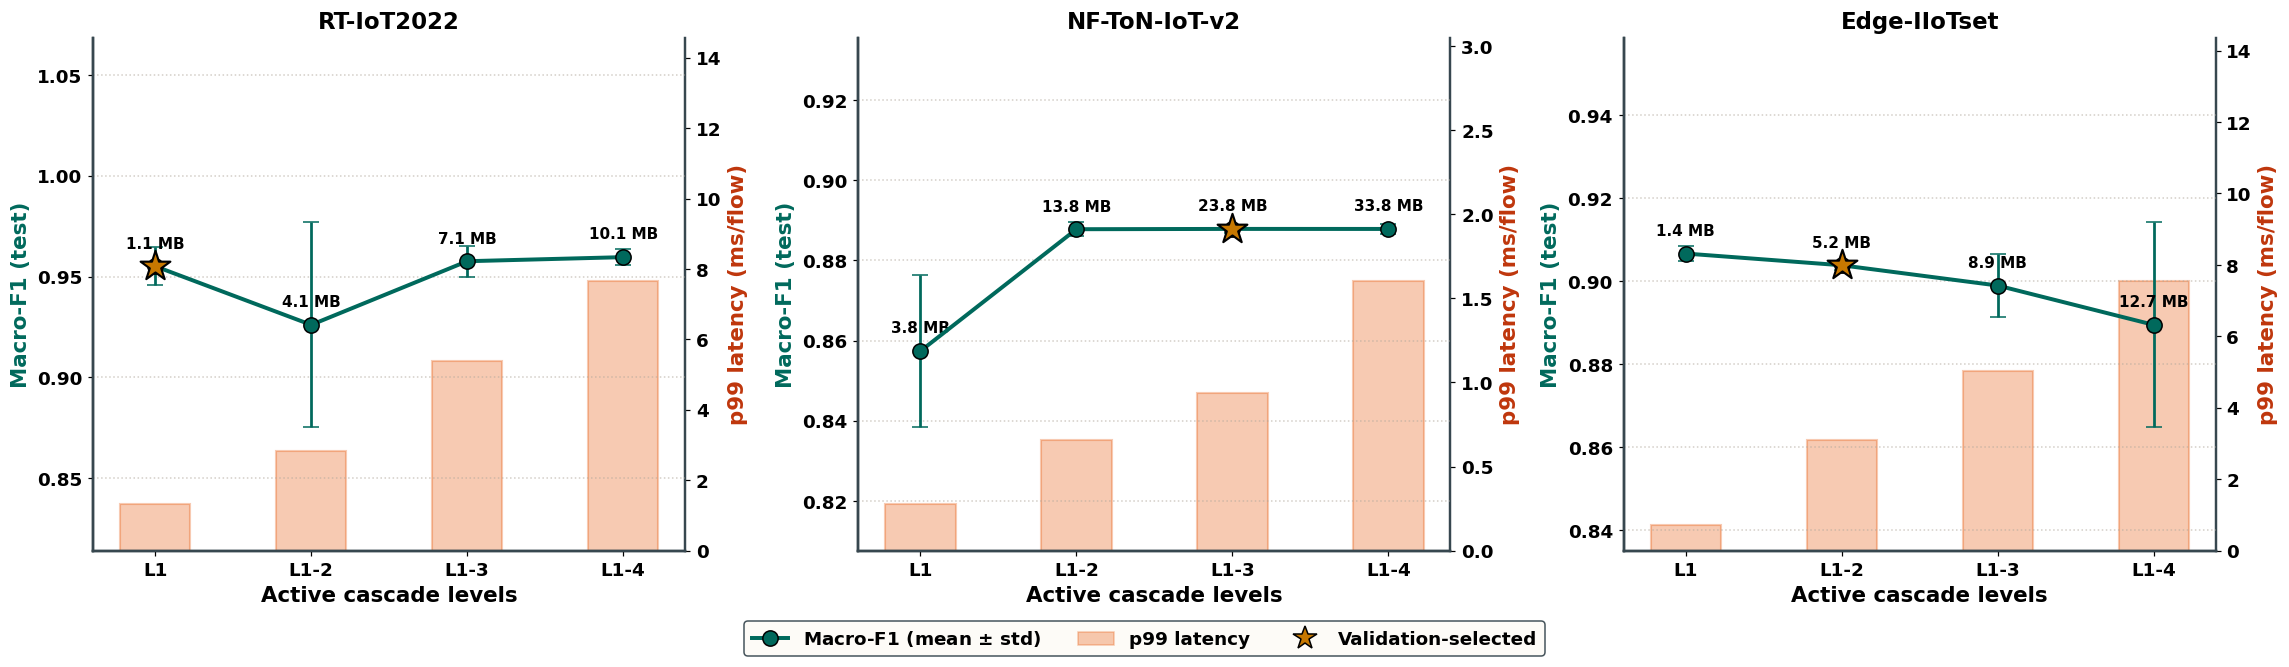

Figure 13. Macro-F1 (line, mean +/- std over seeds) against p99 single-flow latency (bars) for each cascade prefix; labels give the classification-artefact size and the star marks the prefix most often selected on validation.
Cell 16 - Resource-aware configurations table + Figure 13 is complete


In [20]:
# Cell 16 - Table: resource-aware cascade configurations | Figure 13
#   Mean +/- std over RA_SEEDS for every cascade prefix: test accuracy, macro-F1,
#   p99 single-flow latency and classification-artefact size. "Val." counts the seeds
#   on which validation selected that prefix (the deployed model); "RA" counts the
#   seeds on which the budgeted objective of Eq. (resource_objective) picked it.
#   The LaTeX rows below paste straight into Table tab:resource_configurations.
# ------------------------------------------------------------------------------------
print('Cell 16 - Resource-aware configurations table + Figure 13')

def save_fig(fig, stem):
    fig.savefig(FIG_DIR / f"{stem}.png")
    fig.savefig(FIG_DIR / f"{stem}.pdf")          # vector copy for the journal

RA_SUM = (RA_DF.groupby(["Dataset", "k"], sort=False)
          .agg(acc_mu=("acc", "mean"), acc_sd=("acc", "std"),
               f1_mu=("f1_m", "mean"), f1_sd=("f1_m", "std"),
               p50_mu=("p50", "mean"), p99_mu=("p99", "mean"), p99_sd=("p99", "std"),
               kb_mu=("size_kb", "mean"), kb_nov=("size_nov_kb", "mean"),
               int8=("int8_guard_val", "mean"), n_dep=("deployed", "sum"),
               n_ra=("ra_pick", "sum"), n=("seed", "nunique"))
          .reset_index())
RA_SUM.to_csv("resource_aware_levels_summary.csv", index=False)
print(RA_SUM.round(4).to_string(index=False))

print("\nLaTeX rows (Table tab:resource_configurations):")
for name in DATASETS:
    sub = RA_SUM[RA_SUM.Dataset == name]
    for i, r in enumerate(sub.itertuples()):
        cfg = "Level 1" if r.k == 1 else f"Levels 1--{r.k}"
        prec = "INT8" if r.int8 == 1 else ("FP32" if r.int8 == 0 else "mixed")
        lead = f"\\multirow{{{len(sub)}}}{{*}}{{\\dataset{{{name}}}}}" if i == 0 else ""
        print(f"{lead} & {cfg} & ${r.acc_mu*100:.2f} \\pm {r.acc_sd*100:.2f}$ & "
              f"${r.f1_mu:.4f} \\pm {r.f1_sd:.4f}$ & {r.p99_mu:.3f} & "
              f"{r.kb_mu:,.0f} ({prec}) & {r.n_dep}/{r.n} & {r.n_ra}/{r.n} \\\\".replace(",", "{,}"))
    print("\\midrule")

# Figure 13: what each additional level buys (macro-F1) and costs (p99, size)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.8))
for ax, name in zip(axes, DATASETS):
    sub = RA_SUM[RA_SUM.Dataset == name]
    ks = sub.k.values
    ax2 = ax.twinx()
    ax2.bar(ks, sub.p99_mu.values, width=0.45, color="#E65100", alpha=0.30,
            edgecolor="#E65100", linewidth=1.4, zorder=1)
    ax2.set_ylabel("p99 latency (ms/flow)", color="#BF360C")
    ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.set_ylim(0, sub.p99_mu.max() * 1.9)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.errorbar(ks, sub.f1_mu.values, yerr=sub.f1_sd.fillna(0).values, marker="o",
                markersize=10, color="#00695C", markeredgecolor="black", capsize=5,
                elinewidth=1.8, zorder=3)
    for r in sub.itertuples():
        size_lab = f"{r.kb_mu/1024:.1f} MB" if r.kb_mu >= 1024 else f"{r.kb_mu:.0f} KB"
        ax.annotate(size_lab, (r.k, r.f1_mu), xytext=(0, 12),
                    textcoords="offset points", ha="center", fontsize=10, fontweight="bold")
        if r.n_dep == sub.n_dep.max():
            ax.scatter([r.k], [r.f1_mu], s=420, marker="*", color="#C77800",
                       edgecolor="black", linewidth=1.4, zorder=4)
    lo = (sub.f1_mu - sub.f1_sd.fillna(0)).min(); hi = (sub.f1_mu + sub.f1_sd.fillna(0)).max()
    pad = max(hi - lo, 0.004)
    ax.set_ylim(lo - 0.6 * pad, hi + 0.9 * pad)
    ax.set_xticks(ks); ax.set_xticklabels([f"L1" if k == 1 else f"L1-{k}" for k in ks])
    ax.set_xlabel("Active cascade levels"); ax.set_ylabel("Macro-F1 (test)", color="#00695C")
    ax.set_title(name); bold_ticks(ax); bold_ticks(ax2)
handles = [plt.Line2D([0], [0], marker="o", color="#00695C", markeredgecolor="black",
                      markersize=10, label="Macro-F1 (mean $\\pm$ std)"),
           plt.Rectangle((0, 0), 1, 1, color="#E65100", alpha=0.3, label="p99 latency"),
           plt.Line2D([0], [0], marker="*", linestyle="", color="#C77800",
                      markeredgecolor="black", markersize=16, label="Validation-selected")]
fig.legend(handles=handles, loc="lower center", ncol=3, prop={"weight": "bold"},
           bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(); save_fig(fig, "fig13_resource_aware_levels"); plt.show()
print("Figure 13. Macro-F1 (line, mean +/- std over seeds) against p99 single-flow latency "
      "(bars) for each cascade prefix; labels give the classification-artefact size and the "
      "star marks the prefix most often selected on validation.")
print('Cell 16 - Resource-aware configurations table + Figure 13 is complete')


Cell 17 - Uncertainty and calibration table + Figures 14-16
RT-IoT2022      ECE=0.0055+/-0.0006  Brier=0.0056+/-0.0006  Err-AUROC (vac)=0.9650+/-0.0004  Err-AUPR (vac)=0.1153+/-0.0149  AURC (vac)=0.0002+/-0.0000  Err-AUROC (MSP)=0.9962+/-0.0004  Err-AUPR (MSP)=0.5070+/-0.0298  AURC (MSP)=0.0000+/-0.0000  AURC (oracle)=0.0000+/-0.0000  Spearman(support, vac)=-0.8653+/-0.0178
NF-ToN-IoT-v2   ECE=0.0344+/-0.0086  Brier=0.1319+/-0.0037  Err-AUROC (vac)=0.7078+/-0.0094  Err-AUPR (vac)=0.1811+/-0.0126  AURC (vac)=0.0360+/-0.0006  Err-AUROC (MSP)=0.8939+/-0.0105  Err-AUPR (MSP)=0.4106+/-0.0176  AURC (MSP)=0.0134+/-0.0009  AURC (oracle)=0.0035+/-0.0001  Spearman(support, vac)=-0.1171+/-0.2558
Edge-IIoTset    ECE=0.0498+/-0.0254  Brier=0.1213+/-0.0153  Err-AUROC (vac)=0.6372+/-0.0337  Err-AUPR (vac)=0.1183+/-0.0072  AURC (vac)=0.0450+/-0.0016  Err-AUROC (MSP)=0.9160+/-0.0319  Err-AUPR (MSP)=0.4470+/-0.0683  AURC (MSP)=0.0102+/-0.0028  AURC (oracle)=0.0031+/-0.0004  Spearman(support, vac)=-0.404

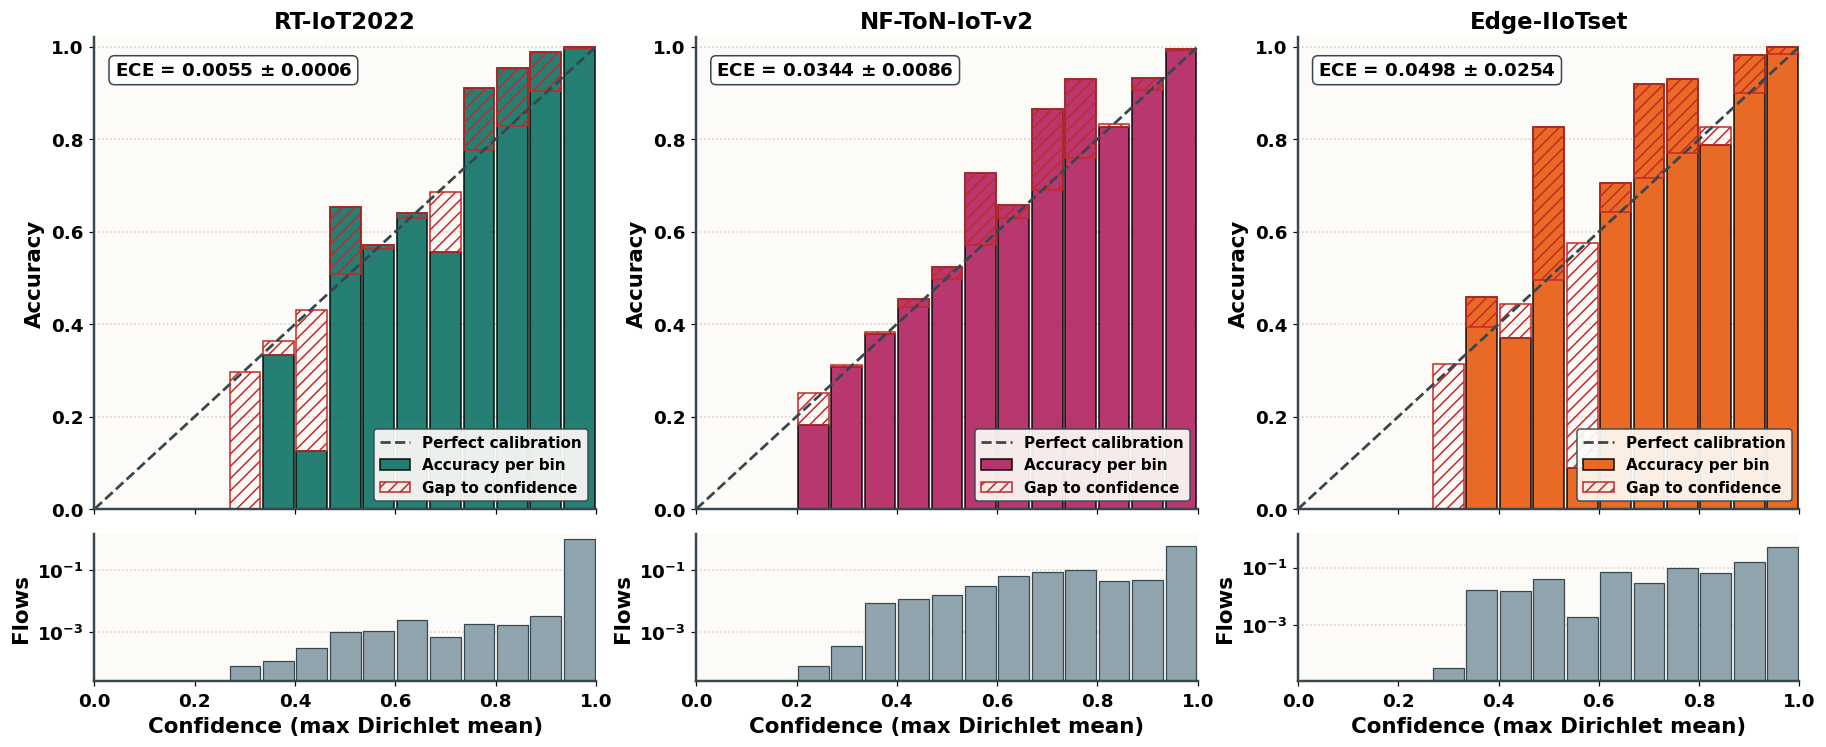

Figure 14. Reliability diagrams of the deployed model (reference seed): per-bin accuracy against confidence, hatched gap to the mean confidence, and the fraction of flows per bin (log) underneath; ECE is mean +/- std over seeds.


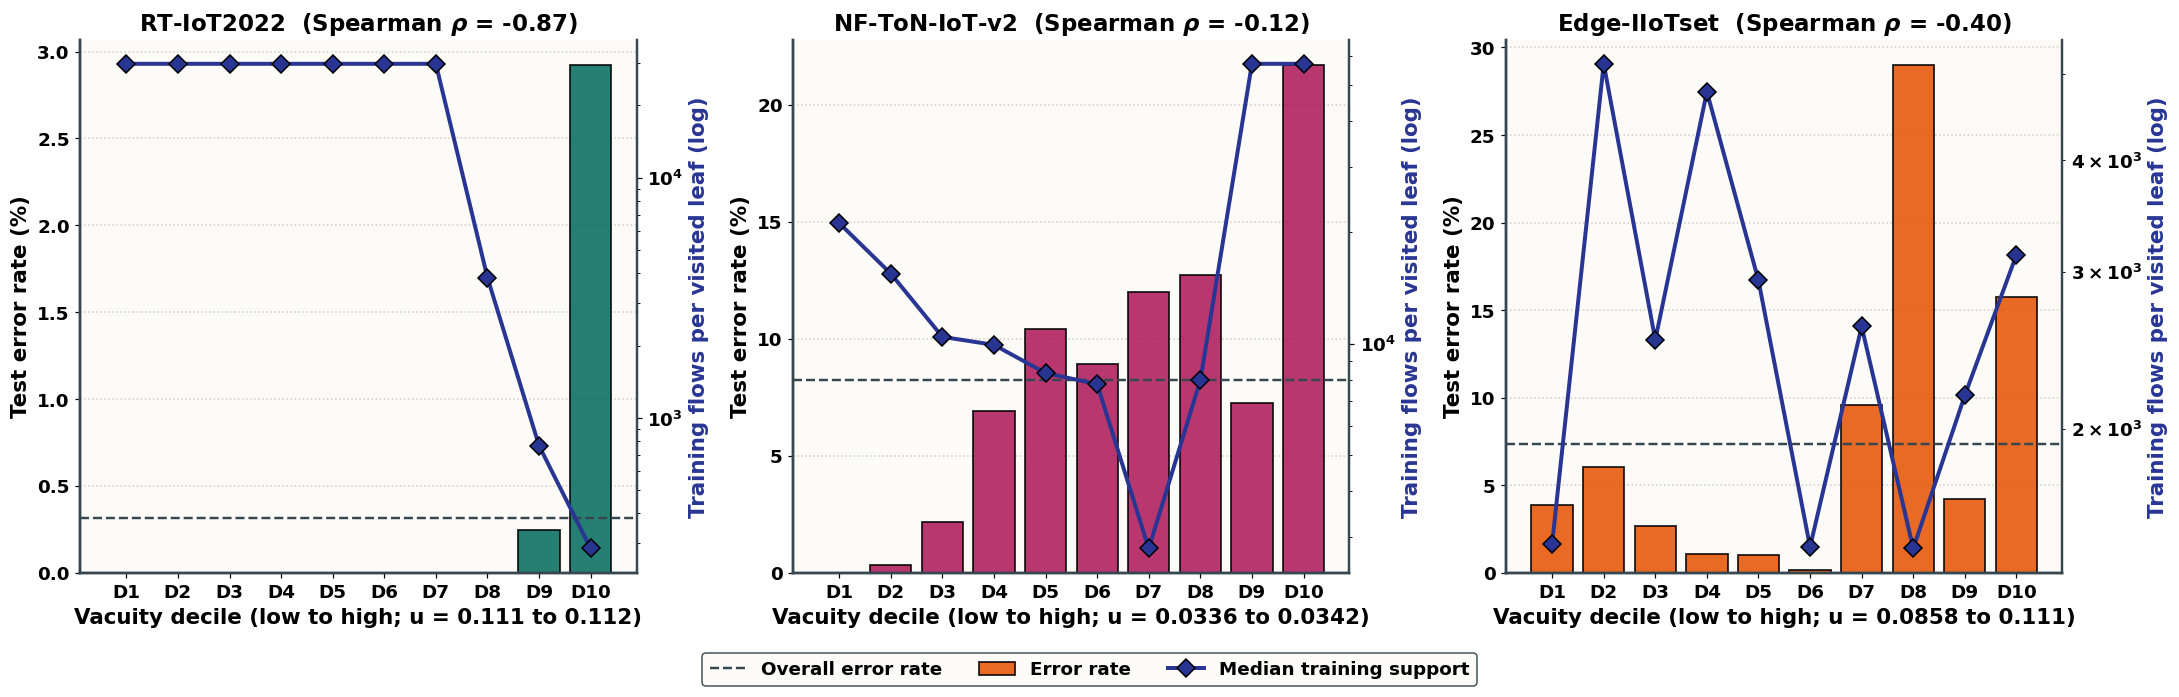

Figure 15. Test error rate (bars) and median training support of the visited level-1 leaves (line) across vacuity deciles (reference seed); rho is the Spearman correlation between support and vacuity averaged over seeds.


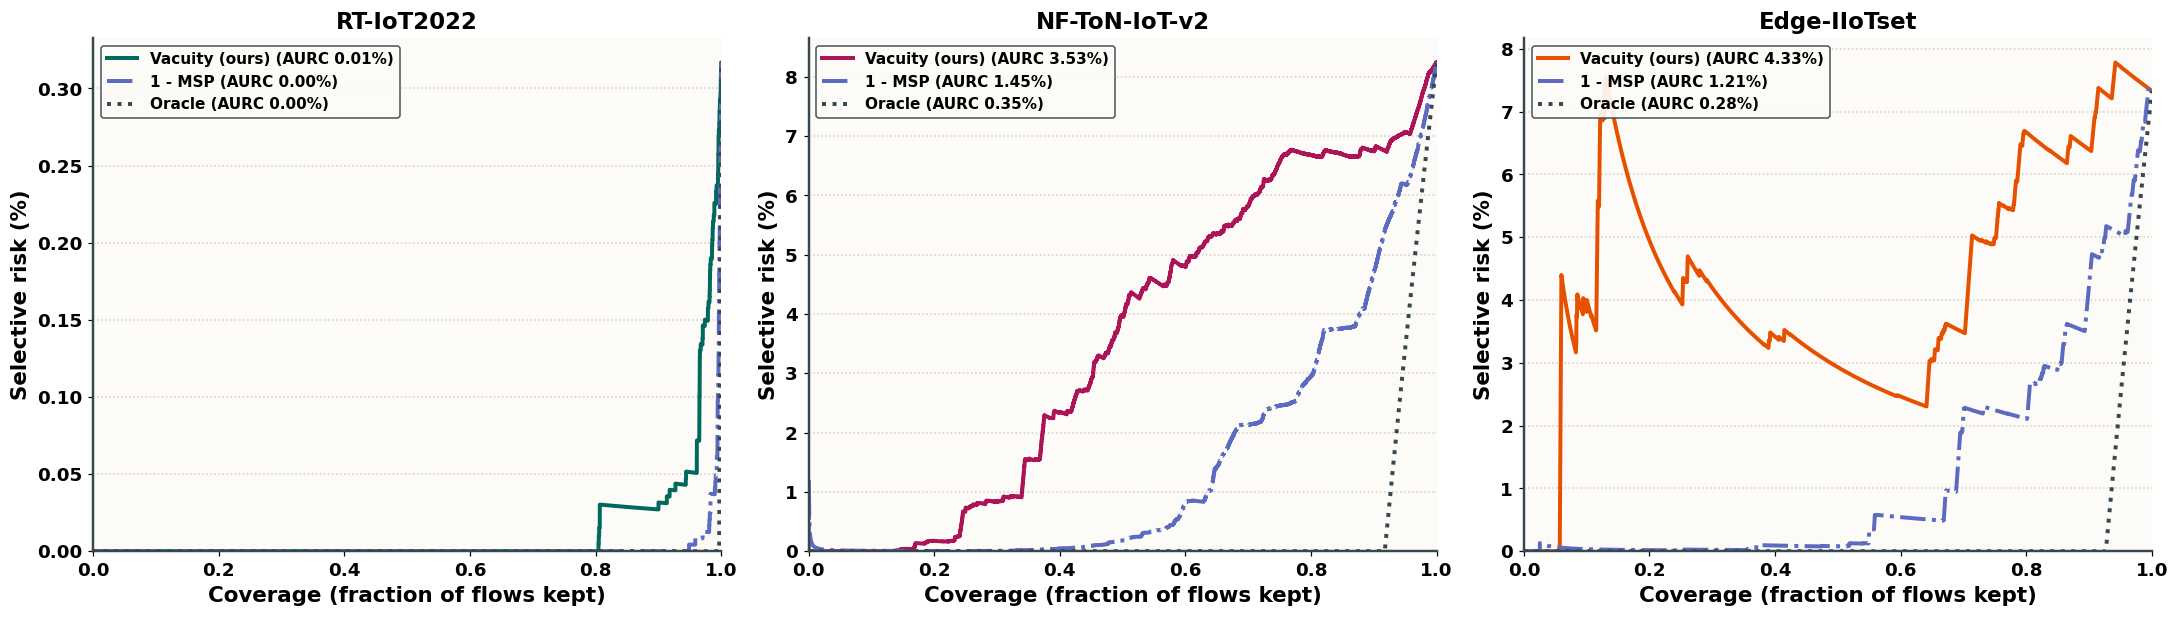

Figure 16. Risk-coverage curves of the deployed model (reference seed): flows are retained from most to least certain under vacuity, 1-MSP and the oracle ordering; lower curves and AURC are better.
Cell 17 - Uncertainty and calibration table + Figures 14-16 is complete


In [21]:
# Cell 17 - Table: uncertainty and calibration | Figures 14-16
#   ECE (15 equal-width confidence bins) and multiclass Brier of the deployed
#   probabilities; error detection (AUROC / AUPR of the score against the 0/1 error
#   indicator) and AURC of the risk-coverage curve, each for the count-backed vacuity
#   and for 1-MSP so the two can be compared on identical predictions.
#   Fig 14: reliability diagrams | Fig 15: error rate and training support across
#   vacuity bins | Fig 16: risk-coverage curves (all on the reference seed).
# -------------------------------------------------------------------------------------
print('Cell 17 - Uncertainty and calibration table + Figures 14-16')

UQ_KEYS = [("ece", "ECE"), ("brier", "Brier"), ("err_auroc_vac", "Err-AUROC (vac)"),
           ("err_aupr_vac", "Err-AUPR (vac)"), ("aurc_vac", "AURC (vac)"),
           ("err_auroc_msp", "Err-AUROC (MSP)"), ("err_aupr_msp", "Err-AUPR (MSP)"),
           ("aurc_msp", "AURC (MSP)"), ("aurc_oracle", "AURC (oracle)"),
           ("rho_support_vac", "Spearman(support, vac)")]
uq_sum = UQ_DF.groupby("Dataset", sort=False).agg(["mean", "std"])
for name in DATASETS:
    print(f"{name:15s} " + "  ".join(f"{lab}={uq_sum.loc[name, (k, 'mean')]:.4f}"
                                     f"+/-{np.nan_to_num(uq_sum.loc[name, (k, 'std')]):.4f}"
                                     for k, lab in UQ_KEYS))
uq_sum.to_csv("uncertainty_calibration_summary.csv")

def _ms(name, k, nd=4):
    mu, sd = uq_sum.loc[name, (k, "mean")], np.nan_to_num(uq_sum.loc[name, (k, "std")])
    return f"${mu:.{nd}f} \\pm {sd:.{nd}f}$"
print("\nLaTeX rows (Table tab:uncertainty_calibration; vacuity / MSP for error columns):")
for name in DATASETS:
    print(f"\\dataset{{{name}}} & {_ms(name, 'ece')} & {_ms(name, 'brier')} & "
          f"{_ms(name, 'err_auroc_vac', 3)} / {uq_sum.loc[name, ('err_auroc_msp', 'mean')]:.3f} & "
          f"{_ms(name, 'err_aupr_vac', 3)} / {uq_sum.loc[name, ('err_aupr_msp', 'mean')]:.3f} & "
          f"{_ms(name, 'aurc_vac')} / {uq_sum.loc[name, ('aurc_msp', 'mean')]:.4f} \\\\")

DCOL = {"RT-IoT2022": "#00695C", "NF-ToN-IoT-v2": "#AD1457", "Edge-IIoTset": "#E65100"}

# Figure 14: reliability diagrams, confidence histogram in a strip underneath
fig, axes = plt.subplots(2, 3, figsize=(20, 7.6), sharex="col",
                         gridspec_kw={"height_ratios": [3.2, 1], "hspace": 0.08})
edges = np.linspace(0, 1, ECE_BINS + 1); mids = 0.5 * (edges[1:] + edges[:-1])
for j, name in enumerate(DATASETS):
    ax, axh = axes[0, j], axes[1, j]
    r = UQ_REP[name]; conf, corr = r["conf"], 1 - r["err"]
    b = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, ECE_BINS - 1)
    cnt = np.bincount(b, minlength=ECE_BINS); ok = cnt > 0
    acc_b = np.array([corr[b == i].mean() if cnt[i] else np.nan for i in range(ECE_BINS)])
    conf_b = np.array([conf[b == i].mean() if cnt[i] else np.nan for i in range(ECE_BINS)])
    ax.plot([0, 1], [0, 1], "--", color="#37474F", linewidth=1.8, label="Perfect calibration")
    ax.bar(mids[ok], acc_b[ok], width=1 / ECE_BINS * 0.92, color=DCOL[name],
           edgecolor="black", linewidth=1.1, alpha=0.85, label="Accuracy per bin")
    ax.bar(mids[ok], conf_b[ok] - acc_b[ok], bottom=acc_b[ok], width=1 / ECE_BINS * 0.92,
           color="none", edgecolor="#C62828", hatch="///", linewidth=1.0, label="Gap to confidence")
    e = UQ_DF[UQ_DF.Dataset == name].ece
    ax.text(0.04, 0.92, f"ECE = {e.mean():.4f} $\\pm$ {np.nan_to_num(e.std()):.4f}",
            transform=ax.transAxes, fontsize=12, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="#37474F"))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_ylabel("Accuracy")
    ax.set_title(name); ax.legend(loc="lower right", prop={"weight": "bold", "size": 10})
    axh.bar(mids, cnt / cnt.sum(), width=1 / ECE_BINS * 0.92, color="#90A4AE",
            edgecolor="#37474F", linewidth=0.8)
    axh.set_yscale("log"); axh.set_ylim(max((cnt[ok] / cnt.sum()).min() / 3, 1e-6), 1.5)
    axh.set_ylabel("Flows"); axh.set_xlabel("Confidence (max Dirichlet mean)")
    bold_ticks(ax); bold_ticks(axh)
fig.tight_layout(); save_fig(fig, "fig14_reliability_diagrams"); plt.show()
print("Figure 14. Reliability diagrams of the deployed model (reference seed): per-bin "
      "accuracy against confidence, hatched gap to the mean confidence, and the fraction "
      "of flows per bin (log) underneath; "
      "ECE is mean +/- std over seeds.")

# Figure 15: error rate and training support across vacuity deciles
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes, DATASETS):
    r = UQ_REP[name]
    q = pd.qcut(pd.Series(r["vac"]).rank(method="first"), 10, labels=False).values
    err_q = np.array([r["err"][q == i].mean() for i in range(10)])
    sup_q = np.array([np.median(r["sup"][q == i]) for i in range(10)])
    vac_q = np.array([np.median(r["vac"][q == i]) for i in range(10)])
    x = np.arange(1, 11)
    ax.bar(x, err_q * 100, color=DCOL[name], edgecolor="black", linewidth=1.2, alpha=0.85,
           label="Error rate")
    ax.axhline(r["err"].mean() * 100, color="#37474F", linestyle="--", linewidth=1.6,
               label="Overall error rate")
    ax2 = ax.twinx()
    ax2.plot(x, np.maximum(sup_q, 1e-1), marker="D", color="#283593", markersize=8,
             markeredgecolor="black", label="Median training support")
    ax2.set_yscale("log"); ax2.grid(False); ax2.spines["right"].set_visible(True)
    ax2.set_ylabel("Training flows per visited leaf (log)", color="#283593")
    ax.set_xticks(x); ax.set_xticklabels([f"D{i}" for i in x])
    ax.set_xlabel(f"Vacuity decile (low to high; u = {vac_q[0]:.3g} to {vac_q[-1]:.3g})")
    ax.set_ylabel("Test error rate (%)")
    rho = UQ_DF[UQ_DF.Dataset == name].rho_support_vac.mean()
    ax.set_title(f"{name}  (Spearman $\\rho$ = {rho:+.2f})")
    bold_ticks(ax); bold_ticks(ax2)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=3, prop={"weight": "bold"},
           bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); save_fig(fig, "fig15_vacuity_error_support"); plt.show()
print("Figure 15. Test error rate (bars) and median training support of the visited "
      "level-1 leaves (line) across vacuity deciles (reference seed); rho is the Spearman "
      "correlation between support and vacuity averaged over seeds.")

# Figure 16: risk-coverage curves, vacuity vs MSP vs oracle ordering
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for ax, name in zip(axes, DATASETS):
    r = UQ_REP[name]
    for unc, lab, col, ls in [(r["vac"], "Vacuity (ours)", DCOL[name], "-"),
                              (1 - r["conf"], "1 - MSP", "#5C6BC0", "-."),
                              (r["err"].astype(float), "Oracle", "#37474F", ":")]:
        cov, risk = risk_coverage(unc, r["err"])
        ax.plot(cov, risk * 100, linestyle=ls, color=col,
                label=f"{lab} (AURC {risk.mean()*100:.2f}%)")
    ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
    ax.set_xlabel("Coverage (fraction of flows kept)"); ax.set_ylabel("Selective risk (%)")
    ax.set_title(name); ax.legend(loc="upper left", prop={"weight": "bold", "size": 10})
    bold_ticks(ax)
fig.tight_layout(); save_fig(fig, "fig16_risk_coverage"); plt.show()
print("Figure 16. Risk-coverage curves of the deployed model (reference seed): flows are "
      "retained from most to least certain under vacuity, 1-MSP and the oracle ordering; "
      "lower curves and AURC are better.")
print('Cell 17 - Uncertainty and calibration table + Figures 14-16 is complete')
